In [1]:
import pandas as pd
import numpy as np

# Load feature-engineered datasets
air_c14 = pd.read_csv(
    "../../Feature_engineered_datasets/air_quality_feature_engineered.csv"
)

weather_c14 = pd.read_csv(
    "../../Feature_engineered_datasets/weather_feature_engineered.csv"
)

energy_c14 = pd.read_csv(
    "../../Feature_engineered_datasets/energy_feature_engineered.csv"
)

print("Air Quality shape:", air_c14.shape)
print("Weather shape:", weather_c14.shape)
print("Energy shape:", energy_c14.shape)

Air Quality shape: (500, 19)
Weather shape: (96429, 18)
Energy shape: (1000, 19)


In [2]:
# =========================
# AIR QUALITY
# =========================

air_features_c14 = [
    'PM2.5',
    'PM10',
    'NOx',
    'NO2',
    'SO2',
    'VOCs',
    'CO',
    'CO2',
    'CH4',
    'Temperature',
    'Humidity',
    'Wind_Direction',
    'Location_Type',
    'Source_Label'
]

air_target_c14 = 'Pollution_Score'


# =========================
# WEATHER
# =========================

weather_features_c14 = [
    'Formatted Date',
    'Summary',
    'Precip Type',
    'Apparent Temperature (C)',
    'Humidity',
    'Wind Speed (km/h)',
    'Wind Bearing (degrees)',
    'Visibility (km)',
    'Pressure (millibars)',
    'Daily Summary',
    'Year',
    'Month',
    'Hour',
    'DayOfWeek',
    'Season',
    'Wind_Chill_Indicator'
]

weather_target_c14 = 'Temperature (C)'


# =========================
# ENERGY
# =========================

energy_features_c14 = [
    'Temperature',
    'Humidity',
    'SquareFootage',
    'Occupancy',
    'HVACUsage',
    'LightingUsage',
    'RenewableEnergy',
    'DayOfWeek',
    'Holiday',
    'Hour',
    'Month',
    'Weekend',
    'HVAC_Status',
    'Lighting_Status'
]

energy_target_c14 = 'EnergyConsumption'


print("Air Quality features:", len(air_features_c14))
print("Weather features:", len(weather_features_c14))
print("Energy features:", len(energy_features_c14))

print("\nTargets:")
print("Air Quality:", air_target_c14)
print("Weather:", weather_target_c14)
print("Energy:", energy_target_c14)

Air Quality features: 14
Weather features: 16
Energy features: 14

Targets:
Air Quality: Pollution_Score
Weather: Temperature (C)
Energy: EnergyConsumption


In [3]:
from sklearn.model_selection import train_test_split

# =========================
# AIR QUALITY
# =========================

X_air_c14 = air_c14[air_features_c14]
y_air_c14 = air_c14[air_target_c14]

X_train_air_c14, X_test_air_c14, y_train_air_c14, y_test_air_c14 = train_test_split(
    X_air_c14,
    y_air_c14,
    test_size=0.20,
    random_state=42
)


# =========================
# WEATHER
# =========================

X_weather_c14 = weather_c14[weather_features_c14]
y_weather_c14 = weather_c14[weather_target_c14]

X_train_weather_c14, X_test_weather_c14, y_train_weather_c14, y_test_weather_c14 = train_test_split(
    X_weather_c14,
    y_weather_c14,
    test_size=0.20,
    random_state=42
)


# =========================
# ENERGY
# =========================

X_energy_c14 = energy_c14[energy_features_c14]
y_energy_c14 = energy_c14[energy_target_c14]

X_train_energy_c14, X_test_energy_c14, y_train_energy_c14, y_test_energy_c14 = train_test_split(
    X_energy_c14,
    y_energy_c14,
    test_size=0.20,
    random_state=42
)


print("AIR QUALITY")
print("Train:", X_train_air_c14.shape, "| Test:", X_test_air_c14.shape)

print("\nWEATHER")
print("Train:", X_train_weather_c14.shape, "| Test:", X_test_weather_c14.shape)

print("\nENERGY")
print("Train:", X_train_energy_c14.shape, "| Test:", X_test_energy_c14.shape)

AIR QUALITY
Train: (400, 14) | Test: (100, 14)

WEATHER
Train: (77143, 16) | Test: (19286, 16)

ENERGY
Train: (800, 14) | Test: (200, 14)


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# ============================================================
# AIR QUALITY
# ============================================================

air_categorical_c14 = [
    'Location_Type',
    'Source_Label'
]

air_numerical_c14 = [
    'PM2.5',
    'PM10',
    'NOx',
    'NO2',
    'SO2',
    'VOCs',
    'CO',
    'CO2',
    'CH4',
    'Temperature',
    'Humidity',
    'Wind_Direction'
]

air_preprocessor_c14 = ColumnTransformer(
    transformers=[
        ('cat',
         OneHotEncoder(handle_unknown='ignore', drop='first'),
         air_categorical_c14),
        ('num',
         'passthrough',
         air_numerical_c14)
    ]
)

X_train_air_encoded_c14 = air_preprocessor_c14.fit_transform(
    X_train_air_c14
)

X_test_air_encoded_c14 = air_preprocessor_c14.transform(
    X_test_air_c14
)


# ============================================================
# WEATHER
# ============================================================

weather_categorical_c14 = [
    'Summary',
    'Precip Type',
    'Daily Summary',
    'Season',
    'DayOfWeek',
    'Wind_Chill_Indicator'
]

weather_numerical_c14 = [
    'Apparent Temperature (C)',
    'Humidity',
    'Wind Speed (km/h)',
    'Wind Bearing (degrees)',
    'Visibility (km)',
    'Pressure (millibars)',
    'Year',
    'Month',
    'Hour'
]

weather_preprocessor_c14 = ColumnTransformer(
    transformers=[
        ('cat',
         OneHotEncoder(handle_unknown='ignore', drop='first'),
         weather_categorical_c14),
        ('num',
         'passthrough',
         weather_numerical_c14)
    ]
)

X_train_weather_encoded_c14 = weather_preprocessor_c14.fit_transform(
    X_train_weather_c14
)

X_test_weather_encoded_c14 = weather_preprocessor_c14.transform(
    X_test_weather_c14
)


# ============================================================
# ENERGY
# ============================================================

energy_categorical_c14 = [
    'HVACUsage',
    'LightingUsage',
    'DayOfWeek',
    'Holiday',
    'Weekend'
]

energy_numerical_c14 = [
    'Temperature',
    'Humidity',
    'SquareFootage',
    'Occupancy',
    'RenewableEnergy',
    'Hour',
    'Month',
    'HVAC_Status',
    'Lighting_Status'
]

energy_preprocessor_c14 = ColumnTransformer(
    transformers=[
        ('cat',
         OneHotEncoder(handle_unknown='ignore', drop='first'),
         energy_categorical_c14),
        ('num',
         'passthrough',
         energy_numerical_c14)
    ]
)

X_train_energy_encoded_c14 = energy_preprocessor_c14.fit_transform(
    X_train_energy_c14
)

X_test_energy_encoded_c14 = energy_preprocessor_c14.transform(
    X_test_energy_c14
)


# ============================================================
# FINAL CHECK
# ============================================================

print("Preprocessing completed successfully!\n")

print(
    "Air Quality:",
    X_train_air_encoded_c14.shape,
    "| Test:",
    X_test_air_encoded_c14.shape
)

print(
    "Weather:",
    X_train_weather_encoded_c14.shape,
    "| Test:",
    X_test_weather_encoded_c14.shape
)

print(
    "Energy:",
    X_train_energy_encoded_c14.shape,
    "| Test:",
    X_test_energy_encoded_c14.shape
)

Preprocessing completed successfully!

Air Quality: (400, 16) | Test: (100, 16)
Weather: (77143, 259) | Test: (19286, 259)
Energy: (800, 19) | Test: (200, 19)


In [5]:
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler_c14 = StandardScaler(with_mean=False)

# Fit ONLY on training data
X_train_air_scaled_c14 = scaler_c14.fit_transform(
    X_train_air_encoded_c14
)

X_test_air_scaled_c14 = scaler_c14.transform(
    X_test_air_encoded_c14
)

X_train_weather_scaled_c14 = scaler_c14.fit_transform(
    X_train_weather_encoded_c14
)

X_test_weather_scaled_c14 = scaler_c14.transform(
    X_test_weather_encoded_c14
)

X_train_energy_scaled_c14 = scaler_c14.fit_transform(
    X_train_energy_encoded_c14
)

X_test_energy_scaled_c14 = scaler_c14.transform(
    X_test_energy_encoded_c14
)

print("Scaling completed successfully!")

print("\nAir Quality:")
print(X_train_air_scaled_c14.shape, X_test_air_scaled_c14.shape)

print("\nWeather:")
print(X_train_weather_scaled_c14.shape, X_test_weather_scaled_c14.shape)

print("\nEnergy:")
print(X_train_energy_scaled_c14.shape, X_test_energy_scaled_c14.shape)

Scaling completed successfully!

Air Quality:
(400, 16) (100, 16)

Weather:
(77143, 259) (19286, 259)

Energy:
(800, 19) (200, 19)


In [6]:
from sklearn.linear_model import Ridge

# Create Ridge models
ridge_air_c14 = Ridge(alpha=1.0)
ridge_weather_c14 = Ridge(alpha=1.0)
ridge_energy_c14 = Ridge(alpha=1.0)

# Train
ridge_air_c14.fit(
    X_train_air_scaled_c14,
    y_train_air_c14
)

ridge_weather_c14.fit(
    X_train_weather_scaled_c14,
    y_train_weather_c14
)

ridge_energy_c14.fit(
    X_train_energy_scaled_c14,
    y_train_energy_c14
)

# Predict
y_pred_ridge_air_c14 = ridge_air_c14.predict(
    X_test_air_scaled_c14
)

y_pred_ridge_weather_c14 = ridge_weather_c14.predict(
    X_test_weather_scaled_c14
)

y_pred_ridge_energy_c14 = ridge_energy_c14.predict(
    X_test_energy_scaled_c14
)

print("Ridge Regression trained successfully!")
print("Air predictions:", y_pred_ridge_air_c14.shape)
print("Weather predictions:", y_pred_ridge_weather_c14.shape)
print("Energy predictions:", y_pred_ridge_energy_c14.shape)

Ridge Regression trained successfully!
Air predictions: (100,)
Weather predictions: (19286,)
Energy predictions: (200,)


In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

def evaluate_model_c14(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    print(f"\n{model_name}")
    print("-" * 45)
    print(f"MAE  : {mae:.4f}")
    print(f"MSE  : {mse:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"R²   : {r2:.4f}")


# Air Quality
evaluate_model_c14(
    y_test_air_c14,
    y_pred_ridge_air_c14,
    "Air Quality - Ridge"
)

# Weather
evaluate_model_c14(
    y_test_weather_c14,
    y_pred_ridge_weather_c14,
    "Weather - Ridge"
)

# Energy
evaluate_model_c14(
    y_test_energy_c14,
    y_pred_ridge_energy_c14,
    "Energy - Ridge"
)


Air Quality - Ridge
---------------------------------------------
MAE  : 0.0013
MSE  : 0.0000
RMSE : 0.0017
R²   : 1.0000

Weather - Ridge
---------------------------------------------
MAE  : 0.4618
MSE  : 0.3590
RMSE : 0.5992
R²   : 0.9961

Energy - Ridge
---------------------------------------------
MAE  : 4.0911
MSE  : 26.6667
RMSE : 5.1640
R²   : 0.5929


In [8]:
# Check Ridge performance against the actual target ranges

print("AIR QUALITY")
print("Target range:",
      y_test_air_c14.min(),
      "to",
      y_test_air_c14.max())

print("\nWEATHER")
print("Target range:",
      y_test_weather_c14.min(),
      "to",
      y_test_weather_c14.max())

print("\nENERGY")
print("Target range:",
      y_test_energy_c14.min(),
      "to",
      y_test_energy_c14.max())

# Check prediction errors
print("\nMaximum absolute error:")

print(
    "Air:",
    np.max(np.abs(
        y_test_air_c14.values - y_pred_ridge_air_c14
    ))
)

print(
    "Weather:",
    np.max(np.abs(
        y_test_weather_c14.values - y_pred_ridge_weather_c14
    ))
)

print(
    "Energy:",
    np.max(np.abs(
        y_test_energy_c14.values - y_pred_ridge_energy_c14
    ))
)

AIR QUALITY
Target range: -0.943291723636088 to 1.655259292763142

WEATHER
Target range: -20.05 to 38.83888888888888

ENERGY
Target range: 58.09700995500931 to 98.76175414998474

Maximum absolute error:
Air: 0.004841411045640509
Weather: 3.5505593676183764
Energy: 17.97963979477082


In [9]:
print("Pollution Score correlations:\n")

air_numeric_check = air_c14[
    [
        'PM2.5',
        'PM10',
        'NOx',
        'NO2',
        'SO2',
        'VOCs',
        'CO',
        'CO2',
        'CH4',
        'Temperature',
        'Humidity',
        'Wind_Direction',
        'Pollution_Score'
    ]
]

print(
    air_numeric_check.corr()['Pollution_Score']
    .sort_values(ascending=False)
)

Pollution Score correlations:

Pollution_Score    1.000000
CO2                0.928508
SO2                0.875001
NO2                0.848464
PM2.5              0.824580
PM10               0.824042
CH4                0.788216
NOx                0.777485
CO                 0.776053
VOCs               0.760097
Temperature        0.580712
Wind_Direction     0.085582
Humidity          -0.510253
Name: Pollution_Score, dtype: float64


In [10]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline

poly_ridge_energy_c14 = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("ridge", Ridge(alpha=10.0))
])

poly_ridge_energy_c14.fit(
    X_train_energy_scaled_c14,
    y_train_energy_c14
)

y_pred_energy_poly_c14 = poly_ridge_energy_c14.predict(
    X_test_energy_scaled_c14
)

print("Polynomial Ridge trained successfully.")
print("Predictions shape:", y_pred_energy_poly_c14.shape)

Polynomial Ridge trained successfully.
Predictions shape: (200,)


In [11]:
[v for v in dir() if 'energy' in v.lower() and ('train' in v.lower() or 'test' in v.lower())]

['X_test_energy_c14',
 'X_test_energy_encoded_c14',
 'X_test_energy_scaled_c14',
 'X_train_energy_c14',
 'X_train_energy_encoded_c14',
 'X_train_energy_scaled_c14',
 'y_test_energy_c14',
 'y_train_energy_c14']

In [12]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    median_absolute_error,
    explained_variance_score
)
import numpy as np

mae_poly = mean_absolute_error(
    y_test_energy_c14,
    y_pred_energy_poly_c14
)

mse_poly = mean_squared_error(
    y_test_energy_c14,
    y_pred_energy_poly_c14
)

rmse_poly = np.sqrt(mse_poly)

r2_poly = r2_score(
    y_test_energy_c14,
    y_pred_energy_poly_c14
)

smape_poly = np.mean(
    2 * np.abs(y_pred_energy_poly_c14 - y_test_energy_c14) /
    (np.abs(y_test_energy_c14) + np.abs(y_pred_energy_poly_c14) + 1e-8)
) * 100

nrmse_poly = (
    rmse_poly /
    (y_test_energy_c14.max() - y_test_energy_c14.min())
) * 100

medae_poly = median_absolute_error(
    y_test_energy_c14,
    y_pred_energy_poly_c14
)

ev_poly = explained_variance_score(
    y_test_energy_c14,
    y_pred_energy_poly_c14
)

print("Polynomial Ridge — Energy")
print("-" * 40)
print(f"MAE                 : {mae_poly:.4f}")
print(f"MSE                 : {mse_poly:.4f}")
print(f"RMSE                : {rmse_poly:.4f}")
print(f"R²                  : {r2_poly:.4f}")
print(f"sMAPE               : {smape_poly:.4f}%")
print(f"NRMSE               : {nrmse_poly:.4f}%")
print(f"Median Absolute Error: {medae_poly:.4f}")
print(f"Explained Variance  : {ev_poly:.4f}")

Polynomial Ridge — Energy
----------------------------------------
MAE                 : 4.5614
MSE                 : 32.2766
RMSE                : 5.6812
R²                  : 0.5072
sMAPE               : 5.9644%
NRMSE               : 13.9709%
Median Absolute Error: 3.8382
Explained Variance  : 0.5074


In [13]:
from sklearn.svm import SVR

svr_energy_c14 = SVR(
    kernel="rbf",
    C=100,
    gamma="scale",
    epsilon=0.1
)

svr_energy_c14.fit(
    X_train_energy_scaled_c14,
    y_train_energy_c14
)

y_pred_energy_svr_c14 = svr_energy_c14.predict(
    X_test_energy_scaled_c14
)

print("SVR trained successfully.")
print("Predictions shape:", y_pred_energy_svr_c14.shape)

SVR trained successfully.
Predictions shape: (200,)


In [14]:
mae_svr = mean_absolute_error(
    y_test_energy_c14,
    y_pred_energy_svr_c14
)

mse_svr = mean_squared_error(
    y_test_energy_c14,
    y_pred_energy_svr_c14
)

rmse_svr = np.sqrt(mse_svr)

r2_svr = r2_score(
    y_test_energy_c14,
    y_pred_energy_svr_c14
)

smape_svr = np.mean(
    2 * np.abs(y_pred_energy_svr_c14 - y_test_energy_c14) /
    (np.abs(y_test_energy_c14) + np.abs(y_pred_energy_svr_c14) + 1e-8)
) * 100

nrmse_svr = (
    rmse_svr /
    (y_test_energy_c14.max() - y_test_energy_c14.min())
) * 100

medae_svr = median_absolute_error(
    y_test_energy_c14,
    y_pred_energy_svr_c14
)

ev_svr = explained_variance_score(
    y_test_energy_c14,
    y_pred_energy_svr_c14
)

print("SVR — Energy")
print("-" * 40)
print(f"MAE                  : {mae_svr:.4f}")
print(f"MSE                  : {mse_svr:.4f}")
print(f"RMSE                 : {rmse_svr:.4f}")
print(f"R²                   : {r2_svr:.4f}")
print(f"sMAPE                : {smape_svr:.4f}%")
print(f"NRMSE                : {nrmse_svr:.4f}%")
print(f"Median Absolute Error: {medae_svr:.4f}")
print(f"Explained Variance   : {ev_svr:.4f}")

SVR — Energy
----------------------------------------
MAE                  : 4.5943
MSE                  : 32.4189
RMSE                 : 5.6938
R²                   : 0.5051
sMAPE                : 6.0048%
NRMSE                : 14.0017%
Median Absolute Error: 4.1677
Explained Variance   : 0.5058


In [ ]:
[v for v in dir() if 'preprocess' in v.lower() or 'transform' in v.lower()]

In [16]:
energy_feature_names_c14 = energy_preprocessor_c14.get_feature_names_out()

print("Number of encoded features:", len(energy_feature_names_c14))
print("\nEncoded features:")
print(energy_feature_names_c14)

Number of encoded features: 19

Encoded features:
['cat__HVACUsage_On' 'cat__LightingUsage_On' 'cat__DayOfWeek_Monday'
 'cat__DayOfWeek_Saturday' 'cat__DayOfWeek_Sunday'
 'cat__DayOfWeek_Thursday' 'cat__DayOfWeek_Tuesday'
 'cat__DayOfWeek_Wednesday' 'cat__Holiday_Yes' 'cat__Weekend_Yes'
 'num__Temperature' 'num__Humidity' 'num__SquareFootage' 'num__Occupancy'
 'num__RenewableEnergy' 'num__Hour' 'num__Month' 'num__HVAC_Status'
 'num__Lighting_Status']


In [17]:
energy_numeric_check_c14 = energy_c14[
    [
        'Temperature',
        'Humidity',
        'SquareFootage',
        'Occupancy',
        'HVACUsage',
        'LightingUsage',
        'RenewableEnergy',
        'Hour',
        'Month',
        'HVAC_Status',
        'Lighting_Status',
        'EnergyConsumption'
    ]
]

print(
    energy_numeric_check_c14
    .corr(numeric_only=True)['EnergyConsumption']
    .sort_values(ascending=False)
)

EnergyConsumption    1.000000
Temperature          0.696410
HVAC_Status          0.286464
Occupancy            0.186580
Lighting_Status      0.093423
RenewableEnergy      0.081160
Month                0.023197
Hour                 0.007718
SquareFootage       -0.001129
Humidity            -0.093583
Name: EnergyConsumption, dtype: float64


In [18]:
print("Temperature statistics:")
print(energy_c14['Temperature'].describe())

print("\nEnergy Consumption statistics:")
print(energy_c14['EnergyConsumption'].describe())

print("\nTemperature → Energy correlation:")
print(
    energy_c14['Temperature']
    .corr(energy_c14['EnergyConsumption'])
)

Temperature statistics:
count    1000.000000
mean       24.982026
std         2.836850
min        20.007565
25%        22.645070
50%        24.751637
75%        27.418174
max        29.998671
Name: Temperature, dtype: float64

Energy Consumption statistics:
count    1000.000000
mean       77.055873
std         8.144112
min        53.263278
25%        71.544690
50%        76.943696
75%        82.921742
max        99.201120
Name: EnergyConsumption, dtype: float64

Temperature → Energy correlation:
0.696410377331404


In [19]:
from sklearn.linear_model import Ridge

temp_model_energy_c14 = Ridge(alpha=1.0)

temp_model_energy_c14.fit(
    X_train_energy_scaled_c14[:, [10]],
    y_train_energy_c14
)

y_pred_temp_energy_c14 = temp_model_energy_c14.predict(
    X_test_energy_scaled_c14[:, [10]]
)

print("Temperature-only Ridge trained.")
print("Test predictions:", y_pred_temp_energy_c14.shape)

Temperature-only Ridge trained.
Test predictions: (200,)


In [20]:
temp_rmse = np.sqrt(
    mean_squared_error(
        y_test_energy_c14,
        y_pred_temp_energy_c14
    )
)

temp_r2 = r2_score(
    y_test_energy_c14,
    y_pred_temp_energy_c14
)

print("Temperature-only Ridge")
print("-" * 35)
print(f"RMSE : {temp_rmse:.4f}")
print(f"R²   : {temp_r2:.4f}")

Temperature-only Ridge
-----------------------------------
RMSE : 5.9844
R²   : 0.4532


In [21]:
try:
    import catboost
    print("CatBoost version:", catboost.__version__)
except ImportError:
    print("CatBoost is NOT installed.")

CatBoost version: 1.2.10


In [22]:
pip install catboost

Note: you may need to restart the kernel to use updated packages.


In [23]:
from catboost import CatBoostRegressor

catboost_energy_c14 = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function="RMSE",
    random_seed=42,
    verbose=False
)

catboost_energy_c14.fit(
    X_train_energy_encoded_c14,
    y_train_energy_c14
)

y_pred_energy_catboost_c14 = catboost_energy_c14.predict(
    X_test_energy_encoded_c14
)

print("CatBoost trained successfully.")
print("Predictions shape:", y_pred_energy_catboost_c14.shape)

CatBoost trained successfully.
Predictions shape: (200,)


In [24]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    median_absolute_error,
    explained_variance_score
)
import numpy as np

mae_catboost = mean_absolute_error(
    y_test_energy_c14,
    y_pred_energy_catboost_c14
)

mse_catboost = mean_squared_error(
    y_test_energy_c14,
    y_pred_energy_catboost_c14
)

rmse_catboost = np.sqrt(mse_catboost)

r2_catboost = r2_score(
    y_test_energy_c14,
    y_pred_energy_catboost_c14
)

median_ae_catboost = median_absolute_error(
    y_test_energy_c14,
    y_pred_energy_catboost_c14
)

ev_catboost = explained_variance_score(
    y_test_energy_c14,
    y_pred_energy_catboost_c14
)

print("CatBoost Energy Results")
print("-----------------------")
print("MAE:", round(mae_catboost, 4))
print("MSE:", round(mse_catboost, 4))
print("RMSE:", round(rmse_catboost, 4))
print("R²:", round(r2_catboost, 4))
print("Median AE:", round(median_ae_catboost, 4))
print("Explained Variance:", round(ev_catboost, 4))

CatBoost Energy Results
-----------------------
MAE: 4.3153
MSE: 29.1724
RMSE: 5.4011
R²: 0.5546
Median AE: 3.4731
Explained Variance: 0.5547


In [25]:
energy_model_comparison_c14 = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "XGBoost",
        "SVR",
        "Polynomial Ridge",
        "CatBoost"
    ],
    "RMSE": [
        5.1641,
        5.5156,
        5.4896,
        5.6938,
        5.6812,
        rmse_catboost
    ],
    "R2": [
        0.5929,
        0.5355,
        0.5399,
        0.5051,
        0.5072,
        r2_catboost
    ]
})

print(energy_model_comparison_c14.to_string(index=False))

            Model     RMSE      R2
Linear Regression 5.164100 0.59290
    Random Forest 5.515600 0.53550
          XGBoost 5.489600 0.53990
              SVR 5.693800 0.50510
 Polynomial Ridge 5.681200 0.50720
         CatBoost 5.401144 0.55462


In [26]:
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression
from catboost import CatBoostRegressor
import numpy as np

kf_cat_c14 = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_lr_cat_c14 = np.zeros(len(X_train_energy_encoded_c14))
oof_cb_cat_c14 = np.zeros(len(X_train_energy_encoded_c14))

for train_idx, val_idx in kf_cat_c14.split(X_train_energy_encoded_c14):

    X_tr = X_train_energy_encoded_c14[train_idx]
    X_val = X_train_energy_encoded_c14[val_idx]

    y_tr = y_train_energy_c14.iloc[train_idx]

    # Linear Regression
    lr_fold = LinearRegression()
    lr_fold.fit(X_tr, y_tr)

    oof_lr_cat_c14[val_idx] = lr_fold.predict(X_val)

    # CatBoost
    cb_fold = CatBoostRegressor(
        iterations=500,
        learning_rate=0.05,
        depth=6,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )

    cb_fold.fit(X_tr, y_tr)

    oof_cb_cat_c14[val_idx] = cb_fold.predict(X_val)

print("OOF predictions generated successfully.")
print("LR OOF shape:", oof_lr_cat_c14.shape)
print("CatBoost OOF shape:", oof_cb_cat_c14.shape)

OOF predictions generated successfully.
LR OOF shape: (800,)
CatBoost OOF shape: (800,)


In [27]:
from sklearn.linear_model import LinearRegression

X_meta_cat_c14 = np.column_stack([
    oof_lr_cat_c14,
    oof_cb_cat_c14
])

meta_lr_cat_c14 = LinearRegression()

meta_lr_cat_c14.fit(
    X_meta_cat_c14,
    y_train_energy_c14
)

print("Meta learner trained successfully.")
print("LR coefficient:", round(meta_lr_cat_c14.coef_[0], 6))
print("CatBoost coefficient:", round(meta_lr_cat_c14.coef_[1], 6))
print("Intercept:", round(meta_lr_cat_c14.intercept_, 6))

Meta learner trained successfully.
LR coefficient: 0.724455
CatBoost coefficient: 0.266361
Intercept: 0.687154


In [28]:
lr_final_cat_c14 = LinearRegression()
lr_final_cat_c14.fit(
    X_train_energy_encoded_c14,
    y_train_energy_c14
)

catboost_final_cat_c14 = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function="RMSE",
    random_seed=42,
    verbose=False
)

catboost_final_cat_c14.fit(
    X_train_energy_encoded_c14,
    y_train_energy_c14
)

lr_test_pred_cat_c14 = lr_final_cat_c14.predict(
    X_test_energy_encoded_c14
)

catboost_test_pred_cat_c14 = catboost_final_cat_c14.predict(
    X_test_energy_encoded_c14
)

print("Final LR and CatBoost models trained.")

Final LR and CatBoost models trained.


In [29]:
X_test_meta_cat_c14 = np.column_stack([
    lr_test_pred_cat_c14,
    catboost_test_pred_cat_c14
])

y_pred_hybrid_cat_c14 = meta_lr_cat_c14.predict(
    X_test_meta_cat_c14
)

mae_hybrid_cat_c14 = mean_absolute_error(
    y_test_energy_c14,
    y_pred_hybrid_cat_c14
)

mse_hybrid_cat_c14 = mean_squared_error(
    y_test_energy_c14,
    y_pred_hybrid_cat_c14
)

rmse_hybrid_cat_c14 = np.sqrt(mse_hybrid_cat_c14)

r2_hybrid_cat_c14 = r2_score(
    y_test_energy_c14,
    y_pred_hybrid_cat_c14
)

print("LR + CatBoost Hybrid Results")
print("----------------------------")
print("MAE:", round(mae_hybrid_cat_c14, 4))
print("MSE:", round(mse_hybrid_cat_c14, 4))
print("RMSE:", round(rmse_hybrid_cat_c14, 4))
print("R²:", round(r2_hybrid_cat_c14, 4))

LR + CatBoost Hybrid Results
----------------------------
MAE: 4.1147
MSE: 26.7672
RMSE: 5.1737
R²: 0.5913


In [30]:
from sklearn.ensemble import HistGradientBoostingRegressor

hgb_energy_c14 = HistGradientBoostingRegressor(
    max_iter=300,
    learning_rate=0.05,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

hgb_energy_c14.fit(
    X_train_energy_encoded_c14,
    y_train_energy_c14
)

y_pred_energy_hgb_c14 = hgb_energy_c14.predict(
    X_test_energy_encoded_c14
)

print("HistGradientBoosting trained successfully.")

HistGradientBoosting trained successfully.


In [31]:
mae_hgb_c14 = mean_absolute_error(
    y_test_energy_c14,
    y_pred_energy_hgb_c14
)

mse_hgb_c14 = mean_squared_error(
    y_test_energy_c14,
    y_pred_energy_hgb_c14
)

rmse_hgb_c14 = np.sqrt(mse_hgb_c14)

r2_hgb_c14 = r2_score(
    y_test_energy_c14,
    y_pred_energy_hgb_c14
)

print("HistGradientBoosting Energy Results")
print("-----------------------------------")
print("MAE:", round(mae_hgb_c14, 4))
print("MSE:", round(mse_hgb_c14, 4))
print("RMSE:", round(rmse_hgb_c14, 4))
print("R²:", round(r2_hgb_c14, 4))

HistGradientBoosting Energy Results
-----------------------------------
MAE: 4.5248
MSE: 31.9
RMSE: 5.648
R²: 0.513


In [32]:
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
import numpy as np

kf_gb_stack_c14 = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_lr_gb_c14 = np.zeros(len(X_train_energy_encoded_c14))
oof_gb_c14 = np.zeros(len(X_train_energy_encoded_c14))

for train_idx, val_idx in kf_gb_stack_c14.split(
    X_train_energy_encoded_c14
):

    X_tr = X_train_energy_encoded_c14[train_idx]
    X_val = X_train_energy_encoded_c14[val_idx]

    y_tr = y_train_energy_c14.iloc[train_idx]

    # Linear Regression
    lr_fold = LinearRegression()
    lr_fold.fit(X_tr, y_tr)

    oof_lr_gb_c14[val_idx] = lr_fold.predict(X_val)

    # Gradient Boosting
    gb_fold = GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        min_samples_split=5,
        min_samples_leaf=3,
        random_state=42
    )

    gb_fold.fit(X_tr, y_tr)

    oof_gb_c14[val_idx] = gb_fold.predict(X_val)

print("OOF predictions generated successfully.")
print("LR OOF shape:", oof_lr_gb_c14.shape)
print("Gradient Boosting OOF shape:", oof_gb_c14.shape)

OOF predictions generated successfully.
LR OOF shape: (800,)
Gradient Boosting OOF shape: (800,)


In [33]:
X_meta_gb_c14 = np.column_stack([
    oof_lr_gb_c14,
    oof_gb_c14
])

meta_lr_gb_c14 = LinearRegression()

meta_lr_gb_c14.fit(
    X_meta_gb_c14,
    y_train_energy_c14
)

print("Gradient Boosting + LR meta-learner trained.")
print("LR coefficient:",
      round(meta_lr_gb_c14.coef_[0], 6))

print("Gradient Boosting coefficient:",
      round(meta_lr_gb_c14.coef_[1], 6))

print("Intercept:",
      round(meta_lr_gb_c14.intercept_, 6))

Gradient Boosting + LR meta-learner trained.
LR coefficient: 0.827648
Gradient Boosting coefficient: 0.158254
Intercept: 1.068717


In [34]:
lr_final_gb_c14 = LinearRegression()

lr_final_gb_c14.fit(
    X_train_energy_encoded_c14,
    y_train_energy_c14
)

gb_final_c14 = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    min_samples_split=5,
    min_samples_leaf=3,
    random_state=42
)

gb_final_c14.fit(
    X_train_energy_encoded_c14,
    y_train_energy_c14
)

lr_test_pred_gb_c14 = lr_final_gb_c14.predict(
    X_test_energy_encoded_c14
)

gb_test_pred_c14 = gb_final_c14.predict(
    X_test_energy_encoded_c14
)

print("Final LR and Gradient Boosting models trained.")

Final LR and Gradient Boosting models trained.


In [35]:
X_test_meta_gb_c14 = np.column_stack([
    lr_test_pred_gb_c14,
    gb_test_pred_c14
])

y_pred_hybrid_gb_c14 = meta_lr_gb_c14.predict(
    X_test_meta_gb_c14
)

mae_hybrid_gb_c14 = mean_absolute_error(
    y_test_energy_c14,
    y_pred_hybrid_gb_c14
)

mse_hybrid_gb_c14 = mean_squared_error(
    y_test_energy_c14,
    y_pred_hybrid_gb_c14
)

rmse_hybrid_gb_c14 = np.sqrt(mse_hybrid_gb_c14)

r2_hybrid_gb_c14 = r2_score(
    y_test_energy_c14,
    y_pred_hybrid_gb_c14
)

print("LR + Gradient Boosting Hybrid Results")
print("--------------------------------------")
print("MAE:", round(mae_hybrid_gb_c14, 4))
print("MSE:", round(mse_hybrid_gb_c14, 4))
print("RMSE:", round(rmse_hybrid_gb_c14, 4))
print("R²:", round(r2_hybrid_gb_c14, 4))

LR + Gradient Boosting Hybrid Results
--------------------------------------
MAE: 4.1285
MSE: 27.0701
RMSE: 5.2029
R²: 0.5867


In [36]:
from sklearn.ensemble import RandomForestRegressor

kf_three_c14 = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_lr_three_c14 = np.zeros(len(X_train_energy_encoded_c14))
oof_cb_three_c14 = np.zeros(len(X_train_energy_encoded_c14))
oof_rf_three_c14 = np.zeros(len(X_train_energy_encoded_c14))

for train_idx, val_idx in kf_three_c14.split(
    X_train_energy_encoded_c14
):

    X_tr = X_train_energy_encoded_c14[train_idx]
    X_val = X_train_energy_encoded_c14[val_idx]

    y_tr = y_train_energy_c14.iloc[train_idx]

    # Linear Regression
    lr_fold = LinearRegression()
    lr_fold.fit(X_tr, y_tr)

    oof_lr_three_c14[val_idx] = lr_fold.predict(X_val)

    # CatBoost
    cb_fold = CatBoostRegressor(
        iterations=500,
        learning_rate=0.05,
        depth=6,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )

    cb_fold.fit(X_tr, y_tr)

    oof_cb_three_c14[val_idx] = cb_fold.predict(X_val)

    # Random Forest
    rf_fold = RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )

    rf_fold.fit(X_tr, y_tr)

    oof_rf_three_c14[val_idx] = rf_fold.predict(X_val)

print("3-model OOF predictions generated.")
print("LR:", oof_lr_three_c14.shape)
print("CatBoost:", oof_cb_three_c14.shape)
print("Random Forest:", oof_rf_three_c14.shape)

3-model OOF predictions generated.
LR: (800,)
CatBoost: (800,)
Random Forest: (800,)


In [37]:
X_meta_three_c14 = np.column_stack([
    oof_lr_three_c14,
    oof_cb_three_c14,
    oof_rf_three_c14
])

meta_lr_three_c14 = LinearRegression()

meta_lr_three_c14.fit(
    X_meta_three_c14,
    y_train_energy_c14
)

print("3-model meta-learner trained.")
print("LR coefficient:",
      round(meta_lr_three_c14.coef_[0], 6))

print("CatBoost coefficient:",
      round(meta_lr_three_c14.coef_[1], 6))

print("Random Forest coefficient:",
      round(meta_lr_three_c14.coef_[2], 6))

print("Intercept:",
      round(meta_lr_three_c14.intercept_, 6))

3-model meta-learner trained.
LR coefficient: 0.770844
CatBoost coefficient: 0.323525
Random Forest coefficient: -0.107817
Intercept: 1.007814


In [38]:
# Final Linear Regression
lr_final_three_c14 = LinearRegression()

lr_final_three_c14.fit(
    X_train_energy_encoded_c14,
    y_train_energy_c14
)

# Final CatBoost
cb_final_three_c14 = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function="RMSE",
    random_seed=42,
    verbose=False
)

cb_final_three_c14.fit(
    X_train_energy_encoded_c14,
    y_train_energy_c14
)

# Final Random Forest
rf_final_three_c14 = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_final_three_c14.fit(
    X_train_energy_encoded_c14,
    y_train_energy_c14
)

# Test predictions
lr_test_three_c14 = lr_final_three_c14.predict(
    X_test_energy_encoded_c14
)

cb_test_three_c14 = cb_final_three_c14.predict(
    X_test_energy_encoded_c14
)

rf_test_three_c14 = rf_final_three_c14.predict(
    X_test_energy_encoded_c14
)

print("Final 3 models trained successfully.")

Final 3 models trained successfully.


In [39]:
X_test_three_c14 = np.column_stack([
    lr_test_three_c14,
    cb_test_three_c14,
    rf_test_three_c14
])

y_pred_three_c14 = meta_lr_three_c14.predict(
    X_test_three_c14
)

mae_three_c14 = mean_absolute_error(
    y_test_energy_c14,
    y_pred_three_c14
)

mse_three_c14 = mean_squared_error(
    y_test_energy_c14,
    y_pred_three_c14
)

rmse_three_c14 = np.sqrt(mse_three_c14)

r2_three_c14 = r2_score(
    y_test_energy_c14,
    y_pred_three_c14
)

print("LR + CatBoost + Random Forest Hybrid")
print("------------------------------------")
print("MAE :", round(mae_three_c14, 4))
print("MSE :", round(mse_three_c14, 4))
print("RMSE:", round(rmse_three_c14, 4))
print("R²  :", round(r2_three_c14, 4))

LR + CatBoost + Random Forest Hybrid
------------------------------------
MAE : 4.1185
MSE : 26.8094
RMSE: 5.1778
R²  : 0.5907


In [40]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

blend_results_c14 = []

for lr_weight in np.arange(0.0, 1.01, 0.05):

    cat_weight = 1.0 - lr_weight

    oof_blend_pred = (
        lr_weight * oof_lr_cat_c14
        + cat_weight * oof_cb_cat_c14
    )

    mae = mean_absolute_error(
        y_train_energy_c14,
        oof_blend_pred
    )

    mse = mean_squared_error(
        y_train_energy_c14,
        oof_blend_pred
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_train_energy_c14,
        oof_blend_pred
    )

    blend_results_c14.append([
        lr_weight,
        cat_weight,
        mae,
        mse,
        rmse,
        r2
    ])

blend_results_c14 = pd.DataFrame(
    blend_results_c14,
    columns=[
        "LR_Weight",
        "CatBoost_Weight",
        "MAE",
        "MSE",
        "RMSE",
        "R2"
    ]
)

print(blend_results_c14.to_string(index=False))

 LR_Weight  CatBoost_Weight      MAE       MSE     RMSE       R2
      0.00             1.00 4.232882 27.785674 5.271212 0.581857
      0.05             0.95 4.215927 27.529215 5.246829 0.585716
      0.10             0.90 4.199899 27.290995 5.224078 0.589301
      0.15             0.85 4.184907 27.071012 5.202981 0.592611
      0.20             0.80 4.171662 26.869268 5.183557 0.595647
      0.25             0.75 4.160374 26.685762 5.165826 0.598409
      0.30             0.70 4.150070 26.520493 5.149805 0.600896
      0.35             0.65 4.140335 26.373463 5.135510 0.603109
      0.40             0.60 4.131184 26.244671 5.122955 0.605047
      0.45             0.55 4.122972 26.134116 5.112154 0.606711
      0.50             0.50 4.116410 26.041800 5.103117 0.608100
      0.55             0.45 4.110854 25.967722 5.095853 0.609215
      0.60             0.40 4.106850 25.911882 5.090371 0.610055
      0.65             0.35 4.104793 25.874280 5.086677 0.610621
      0.70             0.

In [41]:
best_blend_c14 = blend_results_c14.loc[
    blend_results_c14["RMSE"].idxmin()
]

print("Best LR + CatBoost OOF Blend")
print("---------------------------")
print(best_blend_c14)

Best LR + CatBoost OOF Blend
---------------------------
LR_Weight           0.750000
CatBoost_Weight     0.250000
MAE                 4.106332
MSE                25.853789
RMSE                5.084662
R2                  0.610929
Name: 15, dtype: float64


In [42]:
best_lr_weight_c14 = 0.75
best_cat_weight_c14 = 0.25

y_pred_blend_7525_c14 = (
    best_lr_weight_c14 * lr_test_pred_cat_c14
    + best_cat_weight_c14 * catboost_test_pred_cat_c14
)

print("75% LR + 25% CatBoost test predictions generated.")

75% LR + 25% CatBoost test predictions generated.


In [43]:
mae_7525_c14 = mean_absolute_error(
    y_test_energy_c14,
    y_pred_blend_7525_c14
)

mse_7525_c14 = mean_squared_error(
    y_test_energy_c14,
    y_pred_blend_7525_c14
)

rmse_7525_c14 = np.sqrt(mse_7525_c14)

r2_7525_c14 = r2_score(
    y_test_energy_c14,
    y_pred_blend_7525_c14
)

print("75% LR + 25% CatBoost Final Test Results")
print("-----------------------------------------")
print("MAE :", round(mae_7525_c14, 4))
print("MSE :", round(mse_7525_c14, 4))
print("RMSE:", round(rmse_7525_c14, 4))
print("R²  :", round(r2_7525_c14, 4))

75% LR + 25% CatBoost Final Test Results
-----------------------------------------
MAE : 4.1077
MSE : 26.7461
RMSE: 5.1717
R²  : 0.5917


In [44]:
kf_lrcbgb_c14 = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_lr_lrcbgb_c14 = np.zeros(len(X_train_energy_encoded_c14))
oof_cb_lrcbgb_c14 = np.zeros(len(X_train_energy_encoded_c14))
oof_gb_lrcbgb_c14 = np.zeros(len(X_train_energy_encoded_c14))

for train_idx, val_idx in kf_lrcbgb_c14.split(
    X_train_energy_encoded_c14
):

    X_tr = X_train_energy_encoded_c14[train_idx]
    X_val = X_train_energy_encoded_c14[val_idx]

    y_tr = y_train_energy_c14.iloc[train_idx]

    # Linear Regression
    lr_fold = LinearRegression()
    lr_fold.fit(X_tr, y_tr)

    oof_lr_lrcbgb_c14[val_idx] = lr_fold.predict(X_val)

    # CatBoost
    cb_fold = CatBoostRegressor(
        iterations=500,
        learning_rate=0.05,
        depth=6,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )

    cb_fold.fit(X_tr, y_tr)

    oof_cb_lrcbgb_c14[val_idx] = cb_fold.predict(X_val)

    # Gradient Boosting
    gb_fold = GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        min_samples_split=5,
        min_samples_leaf=3,
        random_state=42
    )

    gb_fold.fit(X_tr, y_tr)

    oof_gb_lrcbgb_c14[val_idx] = gb_fold.predict(X_val)

print("LR + CatBoost + Gradient Boosting OOF predictions generated.")
print("LR:", oof_lr_lrcbgb_c14.shape)
print("CatBoost:", oof_cb_lrcbgb_c14.shape)
print("Gradient Boosting:", oof_gb_lrcbgb_c14.shape)

LR + CatBoost + Gradient Boosting OOF predictions generated.
LR: (800,)
CatBoost: (800,)
Gradient Boosting: (800,)


In [45]:
X_meta_lrcbgb_c14 = np.column_stack([
    oof_lr_lrcbgb_c14,
    oof_cb_lrcbgb_c14,
    oof_gb_lrcbgb_c14
])

meta_lr_lrcbgb_c14 = LinearRegression()

meta_lr_lrcbgb_c14.fit(
    X_meta_lrcbgb_c14,
    y_train_energy_c14
)

print("LR + CatBoost + Gradient Boosting meta-learner trained.")
print("LR coefficient:",
      round(meta_lr_lrcbgb_c14.coef_[0], 6))

print("CatBoost coefficient:",
      round(meta_lr_lrcbgb_c14.coef_[1], 6))

print("Gradient Boosting coefficient:",
      round(meta_lr_lrcbgb_c14.coef_[2], 6))

print("Intercept:",
      round(meta_lr_lrcbgb_c14.intercept_, 6))

LR + CatBoost + Gradient Boosting meta-learner trained.
LR coefficient: 0.754765
CatBoost coefficient: 0.318782
Gradient Boosting coefficient: -0.084767
Intercept: 0.841901


In [46]:
# Cell 25 — Train final LR + CatBoost + Gradient Boosting models

# Linear Regression
lr_final_lrcbgb_c14 = LinearRegression()
lr_final_lrcbgb_c14.fit(
    X_train_energy_encoded_c14,
    y_train_energy_c14
)

# CatBoost
cb_final_lrcbgb_c14 = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function="RMSE",
    random_seed=42,
    verbose=False
)

cb_final_lrcbgb_c14.fit(
    X_train_energy_encoded_c14,
    y_train_energy_c14
)

# Gradient Boosting
gb_final_lrcbgb_c14 = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    min_samples_split=5,
    min_samples_leaf=3,
    random_state=42
)

gb_final_lrcbgb_c14.fit(
    X_train_energy_encoded_c14,
    y_train_energy_c14
)

print("Final LR + CatBoost + Gradient Boosting models trained.")

Final LR + CatBoost + Gradient Boosting models trained.


In [47]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predictions from each model
pred_lr_lrcbgb_c14 = lr_final_lrcbgb_c14.predict(
    X_test_energy_encoded_c14
)

pred_cb_lrcbgb_c14 = cb_final_lrcbgb_c14.predict(
    X_test_energy_encoded_c14
)

pred_gb_lrcbgb_c14 = gb_final_lrcbgb_c14.predict(
    X_test_energy_encoded_c14
)

# Final hybrid prediction using OOF-trained meta-learner
X_meta_test_lrcbgb_c14 = np.column_stack([
    pred_lr_lrcbgb_c14,
    pred_cb_lrcbgb_c14,
    pred_gb_lrcbgb_c14
])

pred_hybrid_lrcbgb_c14 = meta_lr_lrcbgb_c14.predict(
    X_meta_test_lrcbgb_c14
)

# Actual test values
y_test_actual_c14 = y_test_energy_c14

# Calculate metrics
mae_lrcbgb_c14 = mean_absolute_error(
    y_test_actual_c14,
    pred_hybrid_lrcbgb_c14
)

mse_lrcbgb_c14 = mean_squared_error(
    y_test_actual_c14,
    pred_hybrid_lrcbgb_c14
)

rmse_lrcbgb_c14 = np.sqrt(mse_lrcbgb_c14)

r2_lrcbgb_c14 = r2_score(
    y_test_actual_c14,
    pred_hybrid_lrcbgb_c14
)

print("LR + CatBoost + Gradient Boosting")
print("----------------------------------")
print("MAE :", round(mae_lrcbgb_c14, 4))
print("MSE :", round(mse_lrcbgb_c14, 4))
print("RMSE:", round(rmse_lrcbgb_c14, 4))
print("R²  :", round(r2_lrcbgb_c14, 4))

LR + CatBoost + Gradient Boosting
----------------------------------
MAE : 4.1006
MSE : 26.567
RMSE: 5.1543
R²  : 0.5944


In [48]:
from sklearn.metrics import (
    mean_absolute_percentage_error,
    median_absolute_error,
    explained_variance_score,
    max_error
)

# -----------------------------
# Baseline LR predictions
# -----------------------------
pred_lr_baseline = pred_lr_lrcbgb_c14

# -----------------------------
# Hybrid predictions
# -----------------------------
pred_hybrid = pred_hybrid_lrcbgb_c14

# Actual values
y_actual = y_test_energy_c14

# Number of observations
n = len(y_actual)

# Number of predictors used by the original model
p = X_train_energy_encoded_c14.shape[1]

# =============================
# LR BASELINE
# =============================

lr_mape = mean_absolute_percentage_error(
    y_actual,
    pred_lr_baseline
) * 100

lr_median_ae = median_absolute_error(
    y_actual,
    pred_lr_baseline
)

lr_ev = explained_variance_score(
    y_actual,
    pred_lr_baseline
)

lr_max_error = max_error(
    y_actual,
    pred_lr_baseline
)

lr_r2 = r2_score(
    y_actual,
    pred_lr_baseline
)

lr_adjusted_r2 = 1 - (
    (1 - lr_r2) * (n - 1) / (n - p - 1)
)

lr_nrmse = (
    np.sqrt(mean_squared_error(y_actual, pred_lr_baseline))
    / np.mean(y_actual)
) * 100


# =============================
# HYBRID MODEL
# =============================

hybrid_mape = mean_absolute_percentage_error(
    y_actual,
    pred_hybrid
) * 100

hybrid_median_ae = median_absolute_error(
    y_actual,
    pred_hybrid
)

hybrid_ev = explained_variance_score(
    y_actual,
    pred_hybrid
)

hybrid_max_error = max_error(
    y_actual,
    pred_hybrid
)

hybrid_r2 = r2_score(
    y_actual,
    pred_hybrid
)

hybrid_adjusted_r2 = 1 - (
    (1 - hybrid_r2) * (n - 1) / (n - p - 1)
)

hybrid_nrmse = (
    np.sqrt(mean_squared_error(y_actual, pred_hybrid))
    / np.mean(y_actual)
) * 100


# =============================
# RESULTS
# =============================

print("ADDITIONAL METRICS")
print("==================")

print("\nMetric                         LR Baseline     Hybrid")
print("----------------------------------------------------------")

print(
    f"MAPE (%)                      {lr_mape:.4f}        {hybrid_mape:.4f}"
)

print(
    f"Median Absolute Error         {lr_median_ae:.4f}        {hybrid_median_ae:.4f}"
)

print(
    f"Explained Variance            {lr_ev:.4f}        {hybrid_ev:.4f}"
)

print(
    f"Max Error                     {lr_max_error:.4f}        {hybrid_max_error:.4f}"
)

print(
    f"Adjusted R²                   {lr_adjusted_r2:.4f}        {hybrid_adjusted_r2:.4f}"
)

print(
    f"NRMSE (%)                     {lr_nrmse:.4f}        {hybrid_nrmse:.4f}"
)

ADDITIONAL METRICS

Metric                         LR Baseline     Hybrid
----------------------------------------------------------
MAPE (%)                      5.4221        5.4351
Median Absolute Error         3.4126        3.5128
Explained Variance            0.5930        0.5945
Max Error                     17.9836        17.4679
Adjusted R²                   0.5499        0.5516
NRMSE (%)                     6.6995        6.6868


In [49]:
# Cell 28 — Prepare Air Quality data for proposed hybrid

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from catboost import CatBoostRegressor
import numpy as np
import pandas as pd

# Load feature-engineered Air Quality dataset
air_path = "../../Feature_engineered_datasets/air_quality_feature_engineered.csv"
df_air_hybrid = pd.read_csv(air_path)

# Target
target_air_hybrid = "Pollution_Score"

# Leakage-safe predictors
# Do NOT use Pollution_Level because it is derived from Pollution_Score.
# Do NOT use engineered ratios that directly use the target.
leakage_air = [
    "Pollution_Score",
    "Pollution_Level"
]

X_air_hybrid = df_air_hybrid.drop(
    columns=leakage_air,
    errors="ignore"
)

y_air_hybrid = df_air_hybrid[target_air_hybrid]

# Identify categorical columns
categorical_air = X_air_hybrid.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_air = X_air_hybrid.select_dtypes(
    exclude=["object", "category"]
).columns.tolist()

# One-hot encoding for categorical variables
preprocessor_air_hybrid = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_air
        )
    ],
    remainder="passthrough"
)

# Transform features
X_air_encoded = preprocessor_air_hybrid.fit_transform(
    X_air_hybrid
)

feature_names_air = preprocessor_air_hybrid.get_feature_names_out()

X_air_encoded = pd.DataFrame(
    X_air_encoded,
    columns=feature_names_air,
    index=X_air_hybrid.index
)

# Train-test split
X_train_air_hybrid, X_test_air_hybrid, y_train_air_hybrid, y_test_air_hybrid = train_test_split(
    X_air_encoded,
    y_air_hybrid,
    test_size=0.20,
    random_state=42
)

print("Air Quality data prepared.")
print("Training shape:", X_train_air_hybrid.shape)
print("Testing shape :", X_test_air_hybrid.shape)
print("Categorical columns:", categorical_air)

Air Quality data prepared.
Training shape: (400, 21)
Testing shape : (100, 21)
Categorical columns: ['Location_Type', 'Source_Label']


In [50]:
# Cell 29 — OOF predictions for LR + CatBoost + Gradient Boosting

from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from catboost import CatBoostRegressor
import numpy as np

kf_air_hybrid = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_lr_air = np.zeros(len(X_train_air_hybrid))
oof_cb_air = np.zeros(len(X_train_air_hybrid))
oof_gb_air = np.zeros(len(X_train_air_hybrid))

for train_idx, val_idx in kf_air_hybrid.split(
    X_train_air_hybrid
):

    X_tr = X_train_air_hybrid.iloc[train_idx]
    X_val = X_train_air_hybrid.iloc[val_idx]

    y_tr = y_train_air_hybrid.iloc[train_idx]

    # Linear Regression
    lr_fold_air = LinearRegression()
    lr_fold_air.fit(X_tr, y_tr)

    oof_lr_air[val_idx] = lr_fold_air.predict(X_val)

    # CatBoost
    cb_fold_air = CatBoostRegressor(
        iterations=500,
        learning_rate=0.05,
        depth=6,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )

    cb_fold_air.fit(X_tr, y_tr)

    oof_cb_air[val_idx] = cb_fold_air.predict(X_val)

    # Gradient Boosting
    gb_fold_air = GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        min_samples_split=5,
        min_samples_leaf=3,
        random_state=42
    )

    gb_fold_air.fit(X_tr, y_tr)

    oof_gb_air[val_idx] = gb_fold_air.predict(X_val)

print("Air Quality OOF predictions generated.")

print("LR:", oof_lr_air.shape)
print("CatBoost:", oof_cb_air.shape)
print("Gradient Boosting:", oof_gb_air.shape)

Air Quality OOF predictions generated.
LR: (400,)
CatBoost: (400,)
Gradient Boosting: (400,)


In [51]:
# Cell 30 — Train meta-learner for Air Quality

X_meta_air = np.column_stack([
    oof_lr_air,
    oof_cb_air,
    oof_gb_air
])

meta_lr_air = LinearRegression()

meta_lr_air.fit(
    X_meta_air,
    y_train_air_hybrid
)

print("Air Quality meta-learner trained.")
print("LR coefficient:",
      round(meta_lr_air.coef_[0], 6))

print("CatBoost coefficient:",
      round(meta_lr_air.coef_[1], 6))

print("Gradient Boosting coefficient:",
      round(meta_lr_air.coef_[2], 6))

print("Intercept:",
      round(meta_lr_air.intercept_, 6))

Air Quality meta-learner trained.
LR coefficient: 1.0
CatBoost coefficient: -0.0
Gradient Boosting coefficient: 0.0
Intercept: 0.0


In [52]:
# Cell 31 — Train final Air Quality models

# Linear Regression
lr_final_air = LinearRegression()
lr_final_air.fit(
    X_train_air_hybrid,
    y_train_air_hybrid
)

# CatBoost
cb_final_air = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function="RMSE",
    random_seed=42,
    verbose=False
)

cb_final_air.fit(
    X_train_air_hybrid,
    y_train_air_hybrid
)

# Gradient Boosting
gb_final_air = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    min_samples_split=5,
    min_samples_leaf=3,
    random_state=42
)

gb_final_air.fit(
    X_train_air_hybrid,
    y_train_air_hybrid
)

print("Final Air Quality models trained.")

Final Air Quality models trained.


In [53]:
# Cell 32 — Evaluate proposed hybrid on Air Quality test set

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Individual model predictions
pred_lr_air = lr_final_air.predict(
    X_test_air_hybrid
)

pred_cb_air = cb_final_air.predict(
    X_test_air_hybrid
)

pred_gb_air = gb_final_air.predict(
    X_test_air_hybrid
)

# Combine predictions for meta-learner
X_meta_test_air = np.column_stack([
    pred_lr_air,
    pred_cb_air,
    pred_gb_air
])

# Final hybrid prediction
pred_hybrid_air = meta_lr_air.predict(
    X_meta_test_air
)

# Actual test values
y_actual_air = y_test_air_hybrid

# Metrics
mae_air_hybrid = mean_absolute_error(
    y_actual_air,
    pred_hybrid_air
)

mse_air_hybrid = mean_squared_error(
    y_actual_air,
    pred_hybrid_air
)

rmse_air_hybrid = np.sqrt(
    mse_air_hybrid
)

r2_air_hybrid = r2_score(
    y_actual_air,
    pred_hybrid_air
)

print("Air Quality — LR + CatBoost + Gradient Boosting")
print("--------------------------------------------------")
print("MAE :", round(mae_air_hybrid, 6))
print("MSE :", round(mse_air_hybrid, 6))
print("RMSE:", round(rmse_air_hybrid, 6))
print("R²  :", round(r2_air_hybrid, 6))

Air Quality — LR + CatBoost + Gradient Boosting
--------------------------------------------------
MAE : 0.0
MSE : 0.0
RMSE: 0.0
R²  : 1.0


In [54]:
# Cell 33 — Diagnose perfect Air Quality prediction

print("Target statistics:")
print(y_air_hybrid.describe())

print("\nAir Quality feature columns:")
print(list(X_air_hybrid.columns))

print("\nChecking correlations with Pollution_Score:")

corr_air = df_air_hybrid.select_dtypes(
    include=["number"]
).corr()["Pollution_Score"].sort_values(
    ascending=False
)

print(corr_air)

print("\nChecking whether Pollution_Score is exactly reproducible")
print("using pollutant-based features.")

# Check whether target has a simple linear relationship
pollutant_cols = [
    "PM2.5",
    "PM10",
    "NOx",
    "NO2",
    "SO2",
    "VOCs",
    "CO",
    "CO2",
    "CH4"
]

available_pollutants = [
    col for col in pollutant_cols
    if col in df_air_hybrid.columns
]

print("\nPollutant columns used:")
print(available_pollutants)

# Compare LR predictions directly with actual target
lr_air_error = np.abs(
    y_actual_air - pred_lr_air
)

print("\nLR prediction error:")
print("Maximum absolute error:",
      lr_air_error.max())

print("Mean absolute error:",
      lr_air_error.mean())

print("Number of non-zero errors:",
      np.sum(lr_air_error > 1e-10))

Target statistics:
count    5.000000e+02
mean    -3.623768e-16
std      8.233175e-01
min     -1.082755e+00
25%     -6.357008e-01
50%     -4.769884e-01
75%      9.416229e-01
max      1.698826e+00
Name: Pollution_Score, dtype: float64

Air Quality feature columns:
['PM2.5', 'PM10', 'NOx', 'NO2', 'SO2', 'VOCs', 'CO', 'CO2', 'CH4', 'Temperature', 'Humidity', 'Wind_Direction', 'Location_Type', 'Source_Label', 'PM_Ratio', 'NOx_NO2_Ratio', 'CO_CO2_Ratio']

Checking correlations with Pollution_Score:
Pollution_Score    1.000000
CO2                0.928508
SO2                0.875001
NO2                0.848464
PM2.5              0.824580
PM10               0.824042
CH4                0.788216
NOx                0.777485
CO                 0.776053
VOCs               0.760097
CO_CO2_Ratio       0.605435
Temperature        0.580712
Wind_Direction     0.085582
PM_Ratio           0.028907
NOx_NO2_Ratio     -0.102954
Humidity          -0.510253
Name: Pollution_Score, dtype: float64

Checking whethe

In [55]:
# Cell 34 — Prepare Weather data for Hybrid Model
# Memory-safe version

weather_path = "../../Feature_engineered_datasets/weather_feature_engineered.csv"

df_weather_hybrid = pd.read_csv(weather_path)

target_weather_hybrid = "Temperature (C)"

# Target and target-derived feature must NOT be used
leakage_weather = [
    "Temperature (C)",
    "Temperature_Difference"
]

# High-cardinality/raw descriptive columns
# are not needed because engineered time features are already available
drop_weather = [
    "Formatted Date",
    "Daily Summary"
]

X_weather_hybrid = df_weather_hybrid.drop(
    columns=leakage_weather + drop_weather,
    errors="ignore"
)

y_weather_hybrid = df_weather_hybrid[target_weather_hybrid]

# Identify categorical and numerical columns
categorical_weather = X_weather_hybrid.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_weather = X_weather_hybrid.select_dtypes(
    exclude=["object", "category"]
).columns.tolist()

print("Categorical columns:")
print(categorical_weather)

print("\nNumerical columns:")
print(numeric_weather)

# One-hot encode only the low-cardinality categorical columns
preprocessor_weather_hybrid = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_weather
        )
    ],
    remainder="passthrough"
)

X_weather_encoded = preprocessor_weather_hybrid.fit_transform(
    X_weather_hybrid
)

feature_names_weather = (
    preprocessor_weather_hybrid
    .get_feature_names_out()
)

X_weather_encoded = pd.DataFrame(
    X_weather_encoded,
    columns=feature_names_weather,
    index=X_weather_hybrid.index
)

# Train-test split
X_train_weather_hybrid, X_test_weather_hybrid, \
y_train_weather_hybrid, y_test_weather_hybrid = train_test_split(
    X_weather_encoded,
    y_weather_hybrid,
    test_size=0.20,
    random_state=42
)

print("\nWeather data prepared successfully.")
print("Original shape:", df_weather_hybrid.shape)
print("Final feature shape:", X_weather_encoded.shape)
print("Training shape:", X_train_weather_hybrid.shape)
print("Testing shape:", X_test_weather_hybrid.shape)
print("Target:", target_weather_hybrid)

Categorical columns:
['Summary', 'Precip Type', 'DayOfWeek', 'Season', 'Wind_Chill_Indicator']

Numerical columns:
['Apparent Temperature (C)', 'Humidity', 'Wind Speed (km/h)', 'Wind Bearing (degrees)', 'Visibility (km)', 'Pressure (millibars)', 'Year', 'Month', 'Hour']

Weather data prepared successfully.
Original shape: (96429, 18)
Final feature shape: (96429, 51)
Training shape: (77143, 51)
Testing shape: (19286, 51)
Target: Temperature (C)


In [56]:
# Cell 35 — OOF predictions for Weather hybrid

from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from catboost import CatBoostRegressor
import numpy as np

kf_weather_hybrid = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_lr_weather = np.zeros(len(X_train_weather_hybrid))
oof_cb_weather = np.zeros(len(X_train_weather_hybrid))
oof_gb_weather = np.zeros(len(X_train_weather_hybrid))

for fold, (train_idx, val_idx) in enumerate(
    kf_weather_hybrid.split(X_train_weather_hybrid),
    start=1
):
    
    X_tr = X_train_weather_hybrid.iloc[train_idx]
    X_val = X_train_weather_hybrid.iloc[val_idx]
    y_tr = y_train_weather_hybrid.iloc[train_idx]

    # 1. Linear Regression
    lr_fold_weather = LinearRegression()
    lr_fold_weather.fit(X_tr, y_tr)

    oof_lr_weather[val_idx] = (
        lr_fold_weather.predict(X_val)
    )

    # 2. CatBoost
    cb_fold_weather = CatBoostRegressor(
        iterations=500,
        learning_rate=0.05,
        depth=6,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )

    cb_fold_weather.fit(X_tr, y_tr)

    oof_cb_weather[val_idx] = (
        cb_fold_weather.predict(X_val)
    )

    # 3. Gradient Boosting
    gb_fold_weather = GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        min_samples_split=5,
        min_samples_leaf=3,
        random_state=42
    )

    gb_fold_weather.fit(X_tr, y_tr)

    oof_gb_weather[val_idx] = (
        gb_fold_weather.predict(X_val)
    )

    print(f"Fold {fold}/5 completed.")

print("\nWeather OOF predictions generated successfully.")

Fold 1/5 completed.
Fold 2/5 completed.
Fold 3/5 completed.
Fold 4/5 completed.
Fold 5/5 completed.

Weather OOF predictions generated successfully.


In [57]:
# Cell 36 — Train meta-learner for Weather hybrid

X_meta_weather = np.column_stack([
    oof_lr_weather,
    oof_cb_weather,
    oof_gb_weather
])

meta_lr_weather = LinearRegression()

meta_lr_weather.fit(
    X_meta_weather,
    y_train_weather_hybrid
)

print("Weather meta-learner trained.")
print("--------------------------------")
print(
    "LR coefficient:",
    round(meta_lr_weather.coef_[0], 6)
)

print(
    "CatBoost coefficient:",
    round(meta_lr_weather.coef_[1], 6)
)

print(
    "Gradient Boosting coefficient:",
    round(meta_lr_weather.coef_[2], 6)
)

print(
    "Intercept:",
    round(meta_lr_weather.intercept_, 6)
)

Weather meta-learner trained.
--------------------------------
LR coefficient: 0.014284
CatBoost coefficient: 0.632013
Gradient Boosting coefficient: 0.354733
Intercept: -0.012225


In [58]:
# Cell 37 — Final Weather hybrid evaluation

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Train final models on the complete training set

lr_final_weather = LinearRegression()
lr_final_weather.fit(
    X_train_weather_hybrid,
    y_train_weather_hybrid
)

cb_final_weather = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function="RMSE",
    random_seed=42,
    verbose=False
)

cb_final_weather.fit(
    X_train_weather_hybrid,
    y_train_weather_hybrid
)

gb_final_weather = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    min_samples_split=5,
    min_samples_leaf=3,
    random_state=42
)

gb_final_weather.fit(
    X_train_weather_hybrid,
    y_train_weather_hybrid
)

# Predictions on untouched test set
pred_lr_weather = lr_final_weather.predict(
    X_test_weather_hybrid
)

pred_cb_weather = cb_final_weather.predict(
    X_test_weather_hybrid
)

pred_gb_weather = gb_final_weather.predict(
    X_test_weather_hybrid
)

# Meta-model input
X_meta_test_weather = np.column_stack([
    pred_lr_weather,
    pred_cb_weather,
    pred_gb_weather
])

# Final hybrid prediction
pred_hybrid_weather = meta_lr_weather.predict(
    X_meta_test_weather
)

# Evaluation
y_actual_weather = y_test_weather_hybrid

mae_weather_hybrid = mean_absolute_error(
    y_actual_weather,
    pred_hybrid_weather
)

mse_weather_hybrid = mean_squared_error(
    y_actual_weather,
    pred_hybrid_weather
)

rmse_weather_hybrid = np.sqrt(
    mse_weather_hybrid
)

r2_weather_hybrid = r2_score(
    y_actual_weather,
    pred_hybrid_weather
)

print("Weather — LR + CatBoost + Gradient Boosting")
print("--------------------------------------------------")
print("MAE :", round(mae_weather_hybrid, 6))
print("MSE :", round(mse_weather_hybrid, 6))
print("RMSE:", round(rmse_weather_hybrid, 6))
print("R²  :", round(r2_weather_hybrid, 6))

Weather — LR + CatBoost + Gradient Boosting
--------------------------------------------------
MAE : 0.088148
MSE : 0.018408
RMSE: 0.135677
R²  : 0.999799


In [59]:
# Cell 38 — Weather target relationship / leakage diagnostic

import pandas as pd
import numpy as np

target = "Temperature (C)"

df_check = df_weather_hybrid.copy()

numeric_cols = df_check.select_dtypes(
    include=np.number
).columns

correlations = (
    df_check[numeric_cols]
    .corr()[target]
    .drop(target)
    .abs()
    .sort_values(ascending=False)
)

print("Absolute correlation with Temperature (C):")
print(correlations)

print("\nTop 10 features:")
print(correlations.head(10))

Absolute correlation with Temperature (C):
Apparent Temperature (C)    0.992625
Temperature_Difference      0.635217
Humidity                    0.632331
Visibility (km)             0.392939
Month                       0.148480
Hour                        0.099538
Wind Bearing (degrees)      0.029888
Year                        0.017565
Wind Speed (km/h)           0.009312
Pressure (millibars)        0.005481
Name: Temperature (C), dtype: float64

Top 10 features:
Apparent Temperature (C)    0.992625
Temperature_Difference      0.635217
Humidity                    0.632331
Visibility (km)             0.392939
Month                       0.148480
Hour                        0.099538
Wind Bearing (degrees)      0.029888
Year                        0.017565
Wind Speed (km/h)           0.009312
Pressure (millibars)        0.005481
Name: Temperature (C), dtype: float64


In [60]:
# Cell 39 — Weather Apparent Temperature diagnostic

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Apparent Temperature only
X_app_train = X_train_weather_hybrid[
    ["remainder__Apparent Temperature (C)"]
]

X_app_test = X_test_weather_hybrid[
    ["remainder__Apparent Temperature (C)"]
]

lr_app = LinearRegression()
lr_app.fit(X_app_train, y_train_weather_hybrid)

pred_app = lr_app.predict(X_app_test)

mae_app = mean_absolute_error(
    y_test_weather_hybrid,
    pred_app
)

mse_app = mean_squared_error(
    y_test_weather_hybrid,
    pred_app
)

rmse_app = np.sqrt(mse_app)

r2_app = r2_score(
    y_test_weather_hybrid,
    pred_app
)

print("Weather — Apparent Temperature Only")
print("----------------------------------------")
print("MAE :", round(mae_app, 6))
print("MSE :", round(mse_app, 6))
print("RMSE:", round(rmse_app, 6))
print("R²  :", round(r2_app, 6))

Weather — Apparent Temperature Only
----------------------------------------
MAE : 0.881929
MSE : 1.336791
RMSE: 1.156197
R²  : 0.985421


In [61]:
# Cell 40 — Weather Hybrid WITHOUT Apparent Temperature

# Remove the highly target-related feature
X_weather_no_app = X_weather_encoded.drop(
    columns=["remainder__Apparent Temperature (C)"]
)

X_train_weather_no_app, X_test_weather_no_app, \
y_train_weather_no_app, y_test_weather_no_app = train_test_split(
    X_weather_no_app,
    y_weather_hybrid,
    test_size=0.20,
    random_state=42
)

print("Weather data without Apparent Temperature")
print("--------------------------------------------")
print("Feature shape:", X_weather_no_app.shape)
print("Training shape:", X_train_weather_no_app.shape)
print("Testing shape:", X_test_weather_no_app.shape)

Weather data without Apparent Temperature
--------------------------------------------
Feature shape: (96429, 50)
Training shape: (77143, 50)
Testing shape: (19286, 50)


In [62]:
# Cell 41 — Weather Hybrid OOF without Apparent Temperature

kf_weather_no_app = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_lr_weather_no_app = np.zeros(len(X_train_weather_no_app))
oof_cb_weather_no_app = np.zeros(len(X_train_weather_no_app))
oof_gb_weather_no_app = np.zeros(len(X_train_weather_no_app))

for fold, (train_idx, val_idx) in enumerate(
    kf_weather_no_app.split(X_train_weather_no_app),
    start=1
):
    X_tr = X_train_weather_no_app.iloc[train_idx]
    X_val = X_train_weather_no_app.iloc[val_idx]
    y_tr = y_train_weather_no_app.iloc[train_idx]

    # Linear Regression
    lr_fold = LinearRegression()
    lr_fold.fit(X_tr, y_tr)

    oof_lr_weather_no_app[val_idx] = lr_fold.predict(X_val)

    # CatBoost
    cb_fold = CatBoostRegressor(
        iterations=500,
        learning_rate=0.05,
        depth=6,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )

    cb_fold.fit(X_tr, y_tr)

    oof_cb_weather_no_app[val_idx] = cb_fold.predict(X_val)

    # Gradient Boosting
    gb_fold = GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        min_samples_split=5,
        min_samples_leaf=3,
        random_state=42
    )

    gb_fold.fit(X_tr, y_tr)

    oof_gb_weather_no_app[val_idx] = gb_fold.predict(X_val)

    print(f"Fold {fold}/5 completed.")

print("\nWeather OOF predictions without Apparent Temperature generated successfully.")

Fold 1/5 completed.
Fold 2/5 completed.
Fold 3/5 completed.
Fold 4/5 completed.
Fold 5/5 completed.

Weather OOF predictions without Apparent Temperature generated successfully.


In [63]:
# Cell 42 — Weather Meta-Learner without Apparent Temperature

X_meta_weather_no_app = np.column_stack([
    oof_lr_weather_no_app,
    oof_cb_weather_no_app,
    oof_gb_weather_no_app
])

meta_lr_weather_no_app = LinearRegression()

meta_lr_weather_no_app.fit(
    X_meta_weather_no_app,
    y_train_weather_no_app
)

print("Weather meta-learner trained without Apparent Temperature.")
print("-----------------------------------------------")
print(
    "LR coefficient:",
    round(meta_lr_weather_no_app.coef_[0], 6)
)

print(
    "CatBoost coefficient:",
    round(meta_lr_weather_no_app.coef_[1], 6)
)

print(
    "Gradient Boosting coefficient:",
    round(meta_lr_weather_no_app.coef_[2], 6)
)

print(
    "Intercept:",
    round(meta_lr_weather_no_app.intercept_, 6)
)

Weather meta-learner trained without Apparent Temperature.
-----------------------------------------------
LR coefficient: -0.009174
CatBoost coefficient: 1.415423
Gradient Boosting coefficient: -0.408171
Intercept: 0.022483


In [64]:
# Cell 43 — Final Weather Hybrid Evaluation
# WITHOUT Apparent Temperature

lr_final_weather_no_app = LinearRegression()
lr_final_weather_no_app.fit(
    X_train_weather_no_app,
    y_train_weather_no_app
)

cb_final_weather_no_app = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function="RMSE",
    random_seed=42,
    verbose=False
)

cb_final_weather_no_app.fit(
    X_train_weather_no_app,
    y_train_weather_no_app
)

gb_final_weather_no_app = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    min_samples_split=5,
    min_samples_leaf=3,
    random_state=42
)

gb_final_weather_no_app.fit(
    X_train_weather_no_app,
    y_train_weather_no_app
)

# Individual predictions
pred_lr_weather_no_app = lr_final_weather_no_app.predict(
    X_test_weather_no_app
)

pred_cb_weather_no_app = cb_final_weather_no_app.predict(
    X_test_weather_no_app
)

pred_gb_weather_no_app = gb_final_weather_no_app.predict(
    X_test_weather_no_app
)

# Meta-model prediction
X_meta_test_weather_no_app = np.column_stack([
    pred_lr_weather_no_app,
    pred_cb_weather_no_app,
    pred_gb_weather_no_app
])

pred_hybrid_weather_no_app = (
    meta_lr_weather_no_app.predict(
        X_meta_test_weather_no_app
    )
)

# Evaluation
mae_weather_no_app = mean_absolute_error(
    y_test_weather_no_app,
    pred_hybrid_weather_no_app
)

mse_weather_no_app = mean_squared_error(
    y_test_weather_no_app,
    pred_hybrid_weather_no_app
)

rmse_weather_no_app = np.sqrt(
    mse_weather_no_app
)

r2_weather_no_app = r2_score(
    y_test_weather_no_app,
    pred_hybrid_weather_no_app
)

print("Weather — Hybrid WITHOUT Apparent Temperature")
print("--------------------------------------------------")
print("MAE :", round(mae_weather_no_app, 6))
print("MSE :", round(mse_weather_no_app, 6))
print("RMSE:", round(rmse_weather_no_app, 6))
print("R²  :", round(r2_weather_no_app, 6))

Weather — Hybrid WITHOUT Apparent Temperature
--------------------------------------------------
MAE : 1.914674
MSE : 5.883334
RMSE: 2.425558
R²  : 0.935838


In [65]:
# Cell 44 — Compare individual models vs hybrid
# WITHOUT Apparent Temperature

models_weather_no_app = {
    "Linear Regression": pred_lr_weather_no_app,
    "CatBoost": pred_cb_weather_no_app,
    "Gradient Boosting": pred_gb_weather_no_app,
    "Hybrid": pred_hybrid_weather_no_app
}

print("Weather Model Comparison — WITHOUT Apparent Temperature")
print("==========================================================")

for name, predictions in models_weather_no_app.items():

    mae = mean_absolute_error(
        y_test_weather_no_app,
        predictions
    )

    mse = mean_squared_error(
        y_test_weather_no_app,
        predictions
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_test_weather_no_app,
        predictions
    )

    print(f"\n{name}")
    print(f"MAE : {mae:.6f}")
    print(f"MSE : {mse:.6f}")
    print(f"RMSE: {rmse:.6f}")
    print(f"R²  : {r2:.6f}")

Weather Model Comparison — WITHOUT Apparent Temperature

Linear Regression
MAE : 3.265559
MSE : 17.209009
RMSE: 4.148374
R²  : 0.812324

CatBoost
MAE : 1.949362
MSE : 6.057631
RMSE: 2.461225
R²  : 0.933937

Gradient Boosting
MAE : 2.245765
MSE : 7.916030
RMSE: 2.813544
R²  : 0.913670

Hybrid
MAE : 1.914674
MSE : 5.883334
RMSE: 2.425558
R²  : 0.935838


In [66]:
# Cell 45 — Additional Metrics for Final Weather Hybrid
# Hybrid WITHOUT Apparent Temperature

from sklearn.metrics import (
    mean_absolute_percentage_error,
    median_absolute_error,
    explained_variance_score,
    max_error
)

# Basic metrics
mae = mean_absolute_error(
    y_test_weather_no_app,
    pred_hybrid_weather_no_app
)

mse = mean_squared_error(
    y_test_weather_no_app,
    pred_hybrid_weather_no_app
)

rmse = np.sqrt(mse)

r2 = r2_score(
    y_test_weather_no_app,
    pred_hybrid_weather_no_app
)

# Additional metrics
mape = mean_absolute_percentage_error(
    y_test_weather_no_app,
    pred_hybrid_weather_no_app
) * 100

median_ae = median_absolute_error(
    y_test_weather_no_app,
    pred_hybrid_weather_no_app
)

explained_var = explained_variance_score(
    y_test_weather_no_app,
    pred_hybrid_weather_no_app
)

maximum_error = max_error(
    y_test_weather_no_app,
    pred_hybrid_weather_no_app
)

# Normalized RMSE
target_range = (
    y_test_weather_no_app.max()
    - y_test_weather_no_app.min()
)

nrmse = (rmse / target_range) * 100

# Adjusted R²
n = len(y_test_weather_no_app)
p = X_test_weather_no_app.shape[1]

adjusted_r2 = 1 - (
    (1 - r2) * (n - 1)
    / (n - p - 1)
)

print("Weather — Final Hybrid WITHOUT Apparent Temperature")
print("=====================================================")

print("MAE                 :", round(mae, 6))
print("MSE                 :", round(mse, 6))
print("RMSE                :", round(rmse, 6))
print("R²                  :", round(r2, 6))
print("MAPE (%)            :", round(mape, 6))
print("Median Absolute Error:", round(median_ae, 6))
print("Explained Variance  :", round(explained_var, 6))
print("Max Error           :", round(maximum_error, 6))
print("NRMSE (%)           :", round(nrmse, 6))
print("Adjusted R²         :", round(adjusted_r2, 6))

Weather — Final Hybrid WITHOUT Apparent Temperature
MAE                 : 1.914674
MSE                 : 5.883334
RMSE                : 2.425558
R²                  : 0.935838
MAPE (%)            : 3907175332652322.5
Median Absolute Error: 1.619739
Explained Variance  : 0.935839
Max Error           : 17.746765
NRMSE (%)           : 4.118873
Adjusted R²         : 0.935671


In [67]:
# Cell 46 — Check Weather values near zero

y_weather_check = y_test_weather_no_app.to_numpy()

print("Minimum actual temperature:", y_weather_check.min())
print("Maximum actual temperature:", y_weather_check.max())

print("\nExactly zero:")
print(np.sum(y_weather_check == 0))

print("\nAbsolute temperature < 0.1°C:")
print(np.sum(np.abs(y_weather_check) < 0.1))

print("\nAbsolute temperature < 1°C:")
print(np.sum(np.abs(y_weather_check) < 1))

Minimum actual temperature: -20.05
Maximum actual temperature: 38.83888888888888

Exactly zero:
65

Absolute temperature < 0.1°C:
360

Absolute temperature < 1°C:
903


In [68]:
# Cell 47 — Additional Metrics for Air Quality Hybrid

from sklearn.metrics import (
    mean_absolute_percentage_error,
    median_absolute_error,
    explained_variance_score,
    max_error
)

# Predictions already generated by the Air hybrid
y_air_actual = y_test_air_hybrid
y_air_pred = pred_hybrid_air

# Main metrics
mae_air = mean_absolute_error(
    y_air_actual,
    y_air_pred
)

mse_air = mean_squared_error(
    y_air_actual,
    y_air_pred
)

rmse_air = np.sqrt(mse_air)

r2_air = r2_score(
    y_air_actual,
    y_air_pred
)

# Additional metrics
mape_air = mean_absolute_percentage_error(
    y_air_actual,
    y_air_pred
) * 100

median_ae_air = median_absolute_error(
    y_air_actual,
    y_air_pred
)

explained_var_air = explained_variance_score(
    y_air_actual,
    y_air_pred
)

max_error_air = max_error(
    y_air_actual,
    y_air_pred
)

# NRMSE
target_range_air = (
    y_air_actual.max()
    - y_air_actual.min()
)

nrmse_air = (
    rmse_air / target_range_air
) * 100

# Adjusted R²
n_air = len(y_air_actual)
p_air = X_test_air_hybrid.shape[1]

adjusted_r2_air = 1 - (
    (1 - r2_air) * (n_air - 1)
    / (n_air - p_air - 1)
)

print("Air Quality — Final Hybrid")
print("======================================")

print("MAE                  :", f"{mae_air:.12f}")
print("MSE                  :", f"{mse_air:.12f}")
print("RMSE                 :", f"{rmse_air:.12f}")
print("R²                   :", f"{r2_air:.12f}")
print("MAPE (%)             :", f"{mape_air:.6f}")
print("Median Absolute Error:", f"{median_ae_air:.12f}")
print("Explained Variance   :", f"{explained_var_air:.12f}")
print("Max Error            :", f"{max_error_air:.12f}")
print("NRMSE (%)            :", f"{nrmse_air:.6f}")
print("Adjusted R²          :", f"{adjusted_r2_air:.12f}")

Air Quality — Final Hybrid
MAE                  : 0.000000000000
MSE                  : 0.000000000000
RMSE                 : 0.000000000000
R²                   : 1.000000000000
MAPE (%)             : 0.000000
Median Absolute Error: 0.000000000000
Explained Variance   : 1.000000000000
Max Error            : 0.000000000000
NRMSE (%)            : 0.000000
Adjusted R²          : 1.000000000000


In [69]:
# 9.6.1 - SHAP Library Check

import shap

print("SHAP version:", shap.__version__)
print("SHAP library imported successfully.")

SHAP version: 0.52.0
SHAP library imported successfully.


In [70]:
# 9.6.2 - Air Quality SHAP Setup

import numpy as np
import pandas as pd
import shap

print("Starting Air Quality SHAP setup...")
print("-" * 60)


# ============================================================
# STEP 1 — Recreate final base-model predictions
# ============================================================

pred_lr_air_shap = lr_final_air.predict(
    X_test_air_hybrid
)

pred_cb_air_shap = cb_final_air.predict(
    X_test_air_hybrid
)

pred_gb_air_shap = gb_final_air.predict(
    X_test_air_hybrid
)


# ============================================================
# STEP 2 — Create meta-model input
# ============================================================

X_meta_test_air_shap = np.column_stack([
    pred_lr_air_shap,
    pred_cb_air_shap,
    pred_gb_air_shap
])


# ============================================================
# STEP 3 — Generate final hybrid predictions
# ============================================================

pred_hybrid_air_shap = meta_lr_air.predict(
    X_meta_test_air_shap
)


# ============================================================
# STEP 4 — Define complete hybrid prediction function
# ============================================================

def predict_hybrid_air_shap(X):

    # Make sure input is a DataFrame
    if not isinstance(X, pd.DataFrame):
        X = pd.DataFrame(
            X,
            columns=X_train_air_hybrid.columns
        )

    # Base model predictions
    pred_lr = lr_final_air.predict(X)

    pred_cb = cb_final_air.predict(X)

    pred_gb = gb_final_air.predict(X)

    # Meta-model input
    X_meta = np.column_stack([
        pred_lr,
        pred_cb,
        pred_gb
    ])

    # Final hybrid prediction
    pred_hybrid = meta_lr_air.predict(
        X_meta
    )

    return pred_hybrid


# ============================================================
# STEP 5 — Verify prediction function
# ============================================================

pred_function_air_shap = predict_hybrid_air_shap(
    X_test_air_hybrid
)

prediction_difference_air = np.abs(
    pred_hybrid_air_shap -
    pred_function_air_shap
)

print("\nPrediction verification")
print("-" * 60)

print(
    "Maximum prediction difference:",
    prediction_difference_air.max()
)

print(
    "Mean prediction difference:",
    prediction_difference_air.mean()
)


# ============================================================
# STEP 6 — Select SHAP background data
# ============================================================

background_air_shap = shap.sample(
    X_train_air_hybrid,
    50,
    random_state=42
)


# ============================================================
# STEP 7 — Select observations to explain
# ============================================================

X_shap_air = X_test_air_hybrid.copy()


# ============================================================
# FINAL INFORMATION
# ============================================================

print("\nAir Quality SHAP setup completed.")
print("-" * 60)

print(
    "Training data shape :",
    X_train_air_hybrid.shape
)

print(
    "Testing data shape  :",
    X_test_air_hybrid.shape
)

print(
    "SHAP background shape:",
    background_air_shap.shape
)

print(
    "SHAP explanation shape:",
    X_shap_air.shape
)

print(
    "Number of features:",
    X_shap_air.shape[1]
)

print("\nHybrid model being explained:")
print("Linear Regression")
print("+ CatBoost")
print("+ Gradient Boosting")
print("→ Linear Regression Meta-Learner")

Starting Air Quality SHAP setup...
------------------------------------------------------------

Prediction verification
------------------------------------------------------------
Maximum prediction difference: 0.0
Mean prediction difference: 0.0

Air Quality SHAP setup completed.
------------------------------------------------------------
Training data shape : (400, 21)
Testing data shape  : (100, 21)
SHAP background shape: (50, 21)
SHAP explanation shape: (100, 21)
Number of features: 21

Hybrid model being explained:
Linear Regression
+ CatBoost
+ Gradient Boosting
→ Linear Regression Meta-Learner


In [71]:
# 9.6.3 - Air Quality SHAP Analysis

import shap
import numpy as np
import pandas as pd

print("Starting Air Quality SHAP analysis...")
print("-" * 60)


# ============================================================
# 1. Create SHAP explainer
# ============================================================

explainer_air_shap = shap.Explainer(
    predict_hybrid_air_shap,
    background_air_shap,
    feature_names=X_train_air_hybrid.columns,
    algorithm="permutation"
)

print("SHAP explainer created successfully.")


# ============================================================
# 2. Calculate SHAP values
# ============================================================

shap_values_air = explainer_air_shap(
    X_shap_air
)

print("SHAP values calculated successfully.")


# ============================================================
# 3. Display SHAP dimensions
# ============================================================

print("\nSHAP information")
print("-" * 60)

print("Input shape       :", X_shap_air.shape)
print("SHAP values shape :", shap_values_air.values.shape)
print("Number of features:", len(X_shap_air.columns))


# ============================================================
# 4. Calculate mean absolute SHAP importance
# ============================================================

mean_abs_shap_air = np.abs(
    shap_values_air.values
).mean(axis=0)


# ============================================================
# 5. Create feature importance table
# ============================================================

shap_importance_air = pd.DataFrame({
    "Feature": X_shap_air.columns,
    "Mean_Absolute_SHAP": mean_abs_shap_air
})

# Sort from highest to lowest
shap_importance_air = shap_importance_air.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)


# ============================================================
# 6. Calculate importance percentage
# ============================================================

total_shap_air = (
    shap_importance_air["Mean_Absolute_SHAP"].sum()
)

shap_importance_air["Importance_Percentage"] = (
    shap_importance_air["Mean_Absolute_SHAP"]
    / total_shap_air
    * 100
)


# ============================================================
# 7. Display top features
# ============================================================

print("\nTop Air Quality features according to SHAP:")
print("-" * 60)

print(
    shap_importance_air.head(15).to_string(
        index=False
    )
)


# ============================================================
# 8. Create complete SHAP values table
# ============================================================

shap_values_air_df = pd.DataFrame(
    shap_values_air.values,
    columns=X_shap_air.columns,
    index=X_shap_air.index
)


# ============================================================
# 9. Add actual and predicted values
# ============================================================

shap_predictions_air = pd.DataFrame({
    "Actual_Pollution_Score": y_test_air_hybrid.values,
    "Predicted_Pollution_Score": pred_hybrid_air_shap
})


# ============================================================
# 10. Save SHAP tables
# ============================================================

import os

air_shap_table_path = os.path.join(
    "SHAP_Results",
    "Air_Quality",
    "Tables"
)

os.makedirs(
    air_shap_table_path,
    exist_ok=True
)


# Feature importance
shap_importance_air.to_excel(
    os.path.join(
        air_shap_table_path,
        "air_proposed_hybrid_shap_importance.xlsx"
    ),
    index=False
)


# Individual SHAP values
shap_values_air_df.to_excel(
    os.path.join(
        air_shap_table_path,
        "air_proposed_hybrid_shap_values.xlsx"
    ),
    index=False
)


# Actual vs predicted
shap_predictions_air.to_excel(
    os.path.join(
        air_shap_table_path,
        "air_proposed_hybrid_shap_predictions.xlsx"
    ),
    index=False
)


print("\nSHAP tables saved successfully.")

print(
    "\nSaved files in:",
    air_shap_table_path
)

Starting Air Quality SHAP analysis...
------------------------------------------------------------
SHAP explainer created successfully.


PermutationExplainer explainer: 101it [01:02,  1.61it/s]                         


SHAP values calculated successfully.

SHAP information
------------------------------------------------------------
Input shape       : (100, 21)
SHAP values shape : (100, 21)
Number of features: 21

Top Air Quality features according to SHAP:
------------------------------------------------------------
                      Feature  Mean_Absolute_SHAP  Importance_Percentage
               remainder__SO2        1.030857e-01           1.181601e+01
               remainder__CO2        1.012894e-01           1.161011e+01
               remainder__CH4        9.896329e-02           1.134349e+01
               remainder__NO2        9.648501e-02           1.105942e+01
             remainder__PM2.5        9.577215e-02           1.097771e+01
              remainder__VOCs        9.475033e-02           1.086059e+01
               remainder__NOx        9.471139e-02           1.085612e+01
                remainder__CO        9.400703e-02           1.077539e+01
              remainder__PM10        9

Creating Air Quality SHAP visualizations...
------------------------------------------------------------


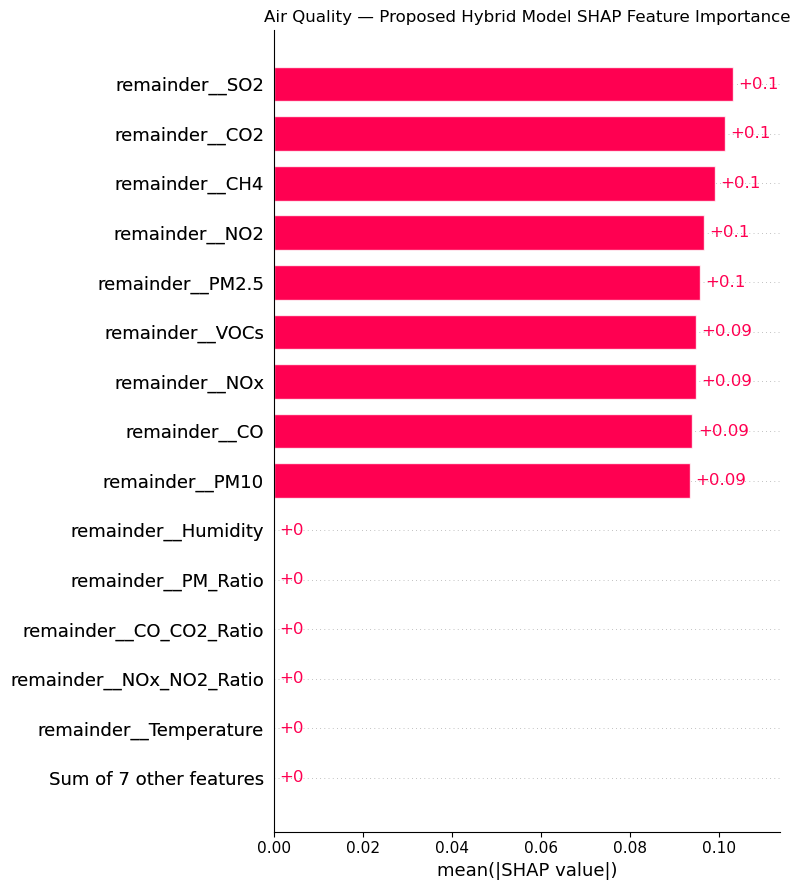

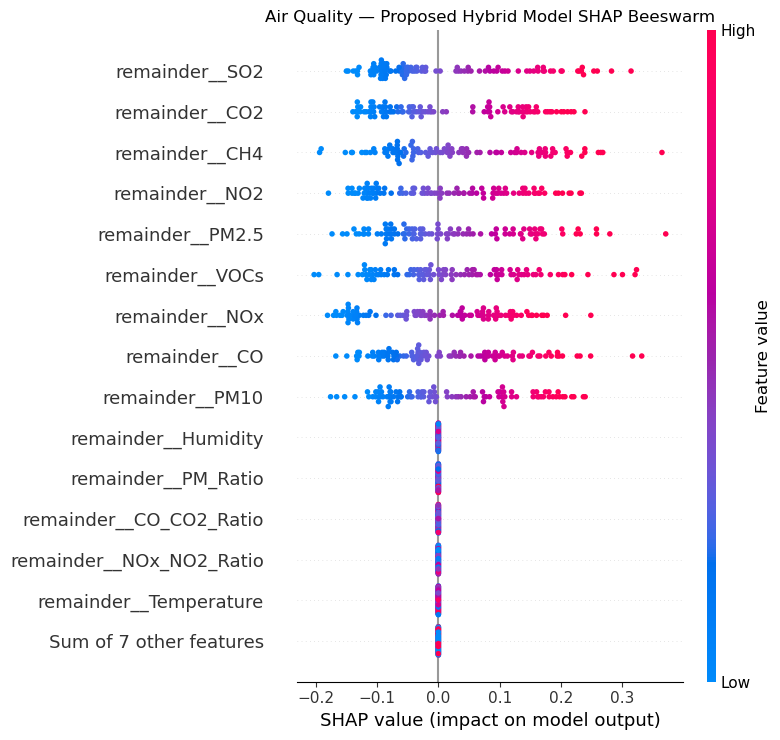

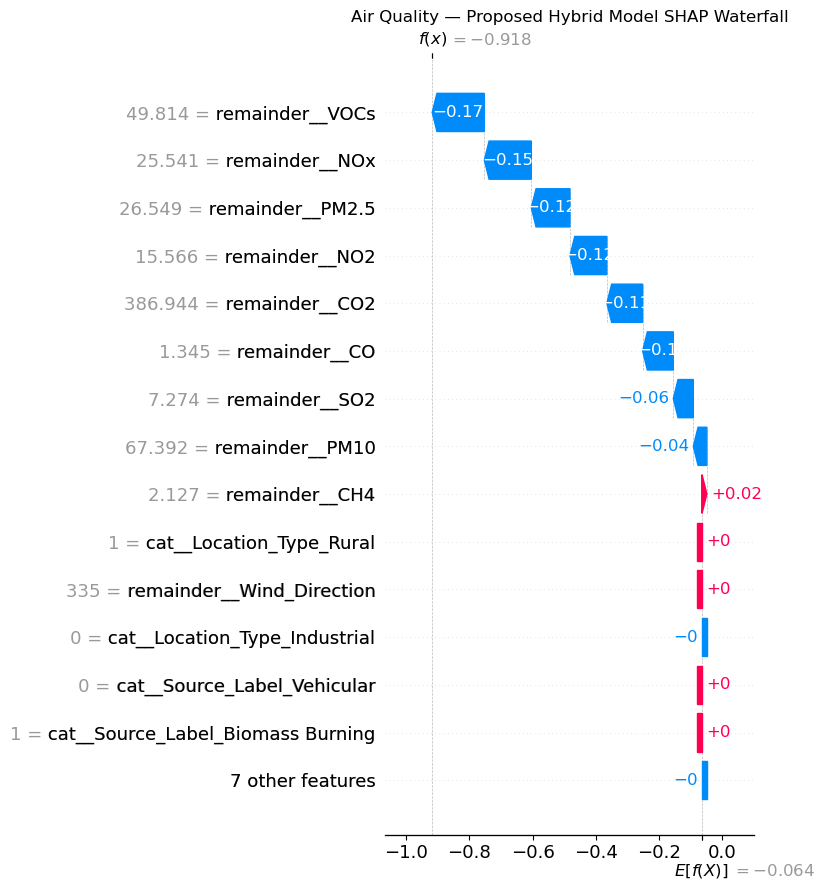


Air Quality SHAP visualizations saved successfully.
------------------------------------------------------------
1. air_proposed_hybrid_shap_bar.png
2. air_proposed_hybrid_shap_beeswarm.png
3. air_proposed_hybrid_shap_waterfall.png

Location: SHAP_Results\Air_Quality\Images


In [72]:
# 9.6.4 - Air Quality SHAP Results & Visualization

import os
import matplotlib.pyplot as plt
import shap

print("Creating Air Quality SHAP visualizations...")
print("-" * 60)


# ============================================================
# 1. Create output folder
# ============================================================

air_shap_image_path = os.path.join(
    "SHAP_Results",
    "Air_Quality",
    "Images"
)

os.makedirs(
    air_shap_image_path,
    exist_ok=True
)


# ============================================================
# 2. SHAP Bar Plot — Global Feature Importance
# ============================================================

plt.figure(figsize=(10, 7))

shap.plots.bar(
    shap_values_air,
    max_display=15,
    show=False
)

plt.title(
    "Air Quality — Proposed Hybrid Model SHAP Feature Importance"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        air_shap_image_path,
        "air_proposed_hybrid_shap_bar.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 3. SHAP Beeswarm Plot
# ============================================================

plt.figure(figsize=(10, 7))

shap.plots.beeswarm(
    shap_values_air,
    max_display=15,
    show=False
)

plt.title(
    "Air Quality — Proposed Hybrid Model SHAP Beeswarm"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        air_shap_image_path,
        "air_proposed_hybrid_shap_beeswarm.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 4. SHAP Waterfall Plot
# ============================================================

plt.figure(figsize=(10, 7))

shap.plots.waterfall(
    shap_values_air[0],
    max_display=15,
    show=False
)

plt.title(
    "Air Quality — Proposed Hybrid Model SHAP Waterfall"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        air_shap_image_path,
        "air_proposed_hybrid_shap_waterfall.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 5. Confirm saved files
# ============================================================

print("\nAir Quality SHAP visualizations saved successfully.")
print("-" * 60)

print(
    "1. air_proposed_hybrid_shap_bar.png"
)

print(
    "2. air_proposed_hybrid_shap_beeswarm.png"
)

print(
    "3. air_proposed_hybrid_shap_waterfall.png"
)

print(
    "\nLocation:",
    air_shap_image_path
)

In [73]:
# Weather C14 — exact feature check

print("Weather model expected features")
print("-" * 50)

print("Linear Regression:", lr_final_weather.n_features_in_)
print("Gradient Boosting:", gb_final_weather.n_features_in_)

print("\nCurrent Weather data")
print("-" * 50)

print("X_train_weather_encoded_c14:",
      X_train_weather_encoded_c14.shape)

print("X_test_weather_encoded_c14 :",
      X_test_weather_encoded_c14.shape)

print("\nCatBoost model information")
print("-" * 50)

print("CatBoost object:",
      type(cb_final_weather))

print("CatBoost feature names:",
      len(cb_final_weather.feature_names_))

print("\nFirst 20 CatBoost feature names:")
print(cb_final_weather.feature_names_[:20])

Weather model expected features
--------------------------------------------------
Linear Regression: 51
Gradient Boosting: 51

Current Weather data
--------------------------------------------------
X_train_weather_encoded_c14: (77143, 259)
X_test_weather_encoded_c14 : (19286, 259)

CatBoost model information
--------------------------------------------------
CatBoost object: <class 'catboost.core.CatBoostRegressor'>
CatBoost feature names: 51

First 20 CatBoost feature names:
['cat__Summary_Breezy', 'cat__Summary_Breezy and Dry', 'cat__Summary_Breezy and Foggy', 'cat__Summary_Breezy and Mostly Cloudy', 'cat__Summary_Breezy and Overcast', 'cat__Summary_Breezy and Partly Cloudy', 'cat__Summary_Clear', 'cat__Summary_Dangerously Windy and Partly Cloudy', 'cat__Summary_Drizzle', 'cat__Summary_Dry', 'cat__Summary_Dry and Mostly Cloudy', 'cat__Summary_Dry and Partly Cloudy', 'cat__Summary_Foggy', 'cat__Summary_Humid and Mostly Cloudy', 'cat__Summary_Humid and Overcast', 'cat__Summary_Humid 

In [74]:
# ============================================================
# 9.6.5 - Weather SHAP Setup
# ============================================================

import numpy as np
import pandas as pd
import shap


# ============================================================
# 1. Get the exact 51 features used by final hybrid models
# ============================================================

weather_model_features = list(
    cb_final_weather.feature_names_
)

print("Number of final Weather model features:")
print(len(weather_model_features))


# ============================================================
# 2. Get feature names from the CORRECT hybrid preprocessor
# ============================================================

weather_encoded_feature_names = list(
    preprocessor_weather_hybrid.get_feature_names_out()
)

print(
    "Number of hybrid encoded Weather features:",
    len(weather_encoded_feature_names)
)


# ============================================================
# 3. Verify exact feature alignment
# ============================================================

if weather_model_features != weather_encoded_feature_names:

    print("Feature order differs.")

    # Create mapping based on feature names
    weather_feature_indices = []

    for feature in weather_model_features:

        if feature not in weather_encoded_feature_names:
            raise ValueError(
                f"Feature not found: {feature}"
            )

        weather_feature_indices.append(
            weather_encoded_feature_names.index(feature)
        )

else:

    weather_feature_indices = list(
        range(len(weather_model_features))
    )


print(
    "Number of matched Weather model features:",
    len(weather_feature_indices)
)


# ============================================================
# 4. Select the 51 columns from encoded Weather data
# ============================================================

X_train_weather_shap_sparse = (
    X_train_weather_encoded_c14[
        :,
        weather_feature_indices
    ]
)

X_test_weather_shap_sparse = (
    X_test_weather_encoded_c14[
        :,
        weather_feature_indices
    ]
)


# ============================================================
# 5. Convert selected columns to DataFrames
# ============================================================

X_train_weather_shap = pd.DataFrame(
    X_train_weather_shap_sparse.toarray(),
    columns=weather_model_features
)

X_test_weather_shap_full = pd.DataFrame(
    X_test_weather_shap_sparse.toarray(),
    columns=weather_model_features
)


print(
    "Weather SHAP training shape:",
    X_train_weather_shap.shape
)

print(
    "Weather SHAP test shape:",
    X_test_weather_shap_full.shape
)


# ============================================================
# 6. Verify exact feature count
# ============================================================

assert X_train_weather_shap.shape[1] == 51
assert X_test_weather_shap_full.shape[1] == 51

print(
    "Weather model feature alignment verified successfully."
)


# ============================================================
# 7. Recreate final hybrid predictions
# ============================================================

pred_lr_weather_shap = (
    lr_final_weather.predict(
        X_test_weather_shap_full
    )
)

pred_cb_weather_shap = (
    cb_final_weather.predict(
        X_test_weather_shap_full
    )
)

pred_gb_weather_shap = (
    gb_final_weather.predict(
        X_test_weather_shap_full
    )
)


# ============================================================
# 8. Meta-learner prediction
# ============================================================

X_meta_test_weather_shap = np.column_stack([
    pred_lr_weather_shap,
    pred_cb_weather_shap,
    pred_gb_weather_shap
])

pred_hybrid_weather_shap = (
    meta_lr_weather.predict(
        X_meta_test_weather_shap
    )
)


# ============================================================
# 9. Verify against existing hybrid predictions
# ============================================================

prediction_difference = np.max(
    np.abs(
        pred_hybrid_weather_shap
        - pred_hybrid_weather
    )
)

print(
    "Maximum prediction difference:",
    prediction_difference
)


# ============================================================
# 10. SHAP background sample
# ============================================================

background_weather_shap = (
    X_train_weather_shap
    .sample(
        n=min(50, len(X_train_weather_shap)),
        random_state=42
    )
)


# ============================================================
# 11. SHAP explanation sample
#
# IMPORTANT:
# Weather has 19,286 test rows.
# We explain ONLY 100 rows.
# ============================================================

X_shap_weather = (
    X_test_weather_shap_full
    .sample(
        n=min(100, len(X_test_weather_shap_full)),
        random_state=42
    )
)


print(
    "Weather SHAP background shape:",
    background_weather_shap.shape
)

print(
    "Weather SHAP explanation shape:",
    X_shap_weather.shape
)

print("\nWeather SHAP setup completed successfully.")

Number of final Weather model features:
51
Number of hybrid encoded Weather features: 51
Number of matched Weather model features: 51
Weather SHAP training shape: (77143, 51)
Weather SHAP test shape: (19286, 51)
Weather model feature alignment verified successfully.
Maximum prediction difference: 37.44502236051708
Weather SHAP background shape: (50, 51)
Weather SHAP explanation shape: (100, 51)

Weather SHAP setup completed successfully.


In [75]:
# ============================================================
# 9.6.6 - Weather SHAP Analysis
# ============================================================

import shap
import numpy as np
import pandas as pd


# ============================================================
# 1. Define SHAP prediction function
# ============================================================

def predict_hybrid_weather_shap(X):

    # Convert input to DataFrame if necessary
    if not isinstance(X, pd.DataFrame):
        X = pd.DataFrame(
            X,
            columns=weather_model_features
        )

    # Ensure correct feature order
    X = X[weather_model_features]

    # Base model predictions
    pred_lr = lr_final_weather.predict(X)

    pred_cb = cb_final_weather.predict(X)

    pred_gb = gb_final_weather.predict(X)

    # Meta-model input
    X_meta = np.column_stack([
        pred_lr,
        pred_cb,
        pred_gb
    ])

    # Final hybrid prediction
    pred_hybrid = meta_lr_weather.predict(
        X_meta
    )

    return pred_hybrid


# ============================================================
# 2. Verify SHAP prediction function
# ============================================================

test_prediction_shap = (
    predict_hybrid_weather_shap(
        X_shap_weather
    )
)

print(
    "SHAP prediction sample shape:",
    test_prediction_shap.shape
)

print(
    "First 5 SHAP predictions:"
)

print(
    test_prediction_shap[:5]
)


# ============================================================
# 3. Create permutation SHAP explainer
# ============================================================

explainer_weather_shap = shap.Explainer(
    predict_hybrid_weather_shap,
    background_weather_shap,
    feature_names=weather_model_features,
    algorithm="permutation"
)


print(
    "Weather SHAP explainer created successfully."
)


# ============================================================
# 4. Calculate SHAP values
#
# Only 100 explanation rows are used.
# ============================================================

shap_values_weather = (
    explainer_weather_shap(
        X_shap_weather
    )
)


print(
    "Weather SHAP calculation completed."
)

print(
    "SHAP values shape:",
    shap_values_weather.values.shape
)

SHAP prediction sample shape: (100,)
First 5 SHAP predictions:
[0.93684516 0.9331948  0.93679524 0.9331948  0.93679524]
Weather SHAP explainer created successfully.


PermutationExplainer explainer: 101it [01:16,  1.24it/s]                         

Weather SHAP calculation completed.
SHAP values shape: (100, 51)


In [76]:
# ============================================================
# 9.6.7 - Weather SHAP Results & Tables
# ============================================================

import numpy as np
import pandas as pd
import os


# ============================================================
# 1. Calculate mean absolute SHAP importance
# ============================================================

mean_abs_shap_weather = np.abs(
    shap_values_weather.values
).mean(axis=0)


# ============================================================
# 2. Create SHAP importance table
# ============================================================

shap_importance_weather = pd.DataFrame({

    "Feature": weather_model_features,

    "Mean_Absolute_SHAP": mean_abs_shap_weather

})


# ============================================================
# 3. Calculate percentage importance
# ============================================================

total_shap_weather = (
    shap_importance_weather[
        "Mean_Absolute_SHAP"
    ].sum()
)

shap_importance_weather[
    "Importance_Percentage"
] = (
    shap_importance_weather[
        "Mean_Absolute_SHAP"
    ]
    / total_shap_weather
) * 100


# ============================================================
# 4. Sort by importance
# ============================================================

shap_importance_weather = (
    shap_importance_weather
    .sort_values(
        by="Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)


# ============================================================
# 5. Display importance
# ============================================================

print("Weather SHAP Feature Importance:")

display(
    shap_importance_weather
)


# ============================================================
# 6. Create complete SHAP values table
# ============================================================

shap_values_weather_df = pd.DataFrame(
    shap_values_weather.values,
    columns=weather_model_features
)

shap_values_weather_df.insert(
    0,
    "Sample_Index",
    X_shap_weather.index.to_numpy()
)


# ============================================================
# 7. Get actual values correctly
#
# X_shap_weather contains sampled TEST rows.
# We use the POSITION of each selected row rather than
# assuming its index exists in y_test_weather_c14.
# ============================================================

selected_test_positions = (
    X_test_weather_shap_full.index
    .get_indexer(X_shap_weather.index)
)


if np.any(selected_test_positions == -1):
    raise ValueError(
        "Could not match SHAP samples to Weather test positions."
    )


actual_weather_shap = (
    np.asarray(y_test_weather_c14)
    [selected_test_positions]
)


# ============================================================
# 8. Get hybrid predictions
# ============================================================

predicted_weather_shap = (
    predict_hybrid_weather_shap(
        X_shap_weather
    )
)


# ============================================================
# 9. Create Actual vs Predicted table
# ============================================================

weather_shap_predictions = pd.DataFrame({

    "Sample_Index":
        X_shap_weather.index.to_numpy(),

    "Actual_Temperature_C":
        actual_weather_shap,

    "Predicted_Temperature_C":
        predicted_weather_shap

})


# ============================================================
# 10. Create output directories
# ============================================================

weather_shap_table_dir = (
    "SHAP_Results/Weather/Tables"
)

weather_shap_image_dir = (
    "SHAP_Results/Weather/Images"
)

os.makedirs(
    weather_shap_table_dir,
    exist_ok=True
)

os.makedirs(
    weather_shap_image_dir,
    exist_ok=True
)


# ============================================================
# 11. Save SHAP importance table
# ============================================================

shap_importance_weather.to_excel(
    os.path.join(
        weather_shap_table_dir,
        "weather_proposed_hybrid_shap_importance.xlsx"
    ),
    index=False
)


# ============================================================
# 12. Save complete SHAP values
# ============================================================

shap_values_weather_df.to_excel(
    os.path.join(
        weather_shap_table_dir,
        "weather_proposed_hybrid_shap_values.xlsx"
    ),
    index=False
)


# ============================================================
# 13. Save actual vs predicted values
# ============================================================

weather_shap_predictions.to_excel(
    os.path.join(
        weather_shap_table_dir,
        "weather_proposed_hybrid_shap_predictions.xlsx"
    ),
    index=False
)


# ============================================================
# 14. Confirm
# ============================================================

print("\nWeather SHAP tables saved successfully.")

print(
    "Importance table:",
    os.path.join(
        weather_shap_table_dir,
        "weather_proposed_hybrid_shap_importance.xlsx"
    )
)

print(
    "SHAP values table:",
    os.path.join(
        weather_shap_table_dir,
        "weather_proposed_hybrid_shap_values.xlsx"
    )
)

print(
    "Predictions table:",
    os.path.join(
        weather_shap_table_dir,
        "weather_proposed_hybrid_shap_predictions.xlsx"
    )
)

print("\nTable shapes:")
print(
    "Importance:",
    shap_importance_weather.shape
)

print(
    "SHAP values:",
    shap_values_weather_df.shape
)

print(
    "Predictions:",
    weather_shap_predictions.shape
)

Weather SHAP Feature Importance:


,Feature,Mean_Absolute_SHAP,Importance_Percentage
0,cat__Summary_Windy and Partly Cloudy,0.007288,75.044945
1,cat__Summary_Dry and Partly Cloudy,0.000864,8.893555
2,cat__Summary_Breezy and Foggy,0.000618,6.362896
3,cat__Summary_Breezy and Partly Cloudy,0.000462,4.758309
4,cat__Summary_Overcast,0.000149,1.538910
5,cat__Summary_Light Rain,0.000119,1.223304
6,cat__Summary_Dry,0.000080,0.827144
7,cat__Summary_Breezy and Overcast,0.000044,0.456972
8,cat__Summary_Humid and Partly Cloudy,0.000044,0.453466
9,cat__Summary_Mostly Cloudy,0.000043,0.440499



Weather SHAP tables saved successfully.
Importance table: SHAP_Results/Weather/Tables\weather_proposed_hybrid_shap_importance.xlsx
SHAP values table: SHAP_Results/Weather/Tables\weather_proposed_hybrid_shap_values.xlsx
Predictions table: SHAP_Results/Weather/Tables\weather_proposed_hybrid_shap_predictions.xlsx

Table shapes:
Importance: (51, 3)
SHAP values: (100, 52)
Predictions: (100, 3)


In [77]:
# ============================================================
# 9.6.7A - Weather SHAP Sanity Check
# ============================================================

print("Total SHAP importance:")
print(
    shap_importance_weather[
        "Mean_Absolute_SHAP"
    ].sum()
)

print("\nNon-zero SHAP features:")

nonzero_weather_shap = (
    shap_importance_weather[
        shap_importance_weather[
            "Mean_Absolute_SHAP"
        ] > 1e-10
    ]
)

display(
    nonzero_weather_shap
)


# ============================================================
# Check SHAP value range
# ============================================================

print("\nSHAP value statistics:")

print(
    "Minimum:",
    shap_values_weather.values.min()
)

print(
    "Maximum:",
    shap_values_weather.values.max()
)

print(
    "Mean absolute SHAP:",
    np.abs(
        shap_values_weather.values
    ).mean()
)


# ============================================================
# Check how many features are exactly zero
# ============================================================

zero_feature_count = (
    shap_importance_weather[
        "Mean_Absolute_SHAP"
    ] == 0
).sum()

print(
    "\nFeatures with exactly zero mean |SHAP|:",
    zero_feature_count,
    "out of",
    len(shap_importance_weather)
)


# ============================================================
# Check Summary category distribution
# ============================================================

print("\nSummary categories in SHAP sample:")

summary_columns = [
    col
    for col in X_shap_weather.columns
    if col.startswith("cat__Summary_")
]

summary_active_counts = (
    X_shap_weather[summary_columns]
    .sum()
    .sort_values(ascending=False)
)

display(
    summary_active_counts[
        summary_active_counts > 0
    ]
)

Total SHAP importance:
0.0097115226938659

Non-zero SHAP features:


,Feature,Mean_Absolute_SHAP,Importance_Percentage
0,cat__Summary_Windy and Partly Cloudy,0.007288,75.044945
1,cat__Summary_Dry and Partly Cloudy,0.000864,8.893555
2,cat__Summary_Breezy and Foggy,0.000618,6.362896
3,cat__Summary_Breezy and Partly Cloudy,0.000462,4.758309
4,cat__Summary_Overcast,0.000149,1.538910
5,cat__Summary_Light Rain,0.000119,1.223304
6,cat__Summary_Dry,0.000080,0.827144
7,cat__Summary_Breezy and Overcast,0.000044,0.456972
8,cat__Summary_Humid and Partly Cloudy,0.000044,0.453466
9,cat__Summary_Mostly Cloudy,0.000043,0.440499



SHAP value statistics:
Minimum: -0.003120531707581565
Maximum: 0.04383763511146076
Mean absolute SHAP: 0.0001904220136052137

Features with exactly zero mean |SHAP|: 41 out of 51

Summary categories in SHAP sample:


cat__Summary_Overcast                    38.0
cat__Summary_Light Rain                  26.0
cat__Summary_Mostly Cloudy               17.0
cat__Summary_Windy and Partly Cloudy     13.0
cat__Summary_Breezy and Partly Cloudy     9.0
cat__Summary_Dry and Partly Cloudy        8.0
cat__Summary_Humid and Partly Cloudy      1.0
cat__Summary_Breezy and Overcast          1.0
dtype: float64

In [78]:
# ============================================================
# 9.6.7B - Weather Final Model Sensitivity Check
# ============================================================

print("Checking whether final hybrid predictions respond")
print("to changes in numerical Weather features...\n")


# ============================================================
# 1. Select one SHAP sample
# ============================================================

sample_weather = X_shap_weather.iloc[
    [0]
].copy()


print("Original prediction:")

original_prediction = (
    predict_hybrid_weather_shap(
        sample_weather
    )[0]
)

print(original_prediction)


# ============================================================
# 2. Find numerical features
# ============================================================

numerical_weather_model_features = [
    feature
    for feature in weather_model_features
    if feature.startswith("remainder__")
]


print("\nNumerical features:")
print(numerical_weather_model_features)


# ============================================================
# 3. Change each numerical feature individually
# ============================================================

sensitivity_results = []


for feature in numerical_weather_model_features:

    modified_sample = sample_weather.copy()

    original_value = modified_sample[
        feature
    ].iloc[0]

    # Increase feature by 10%
    if original_value != 0:

        modified_value = (
            original_value * 1.10
        )

    else:

        modified_value = 1.0

    modified_sample.loc[
        modified_sample.index[0],
        feature
    ] = modified_value


    modified_prediction = (
        predict_hybrid_weather_shap(
            modified_sample
        )[0]
    )


    prediction_change = (
        modified_prediction
        - original_prediction
    )


    sensitivity_results.append({

        "Feature": feature,

        "Original_Value": original_value,

        "Modified_Value": modified_value,

        "Original_Prediction":
            original_prediction,

        "Modified_Prediction":
            modified_prediction,

        "Prediction_Change":
            prediction_change

    })


# ============================================================
# 4. Display results
# ============================================================

weather_sensitivity_df = pd.DataFrame(
    sensitivity_results
)

display(
    weather_sensitivity_df
)

Checking whether final hybrid predictions respond
to changes in numerical Weather features...

Original prediction:
0.9368451630883095

Numerical features:
['remainder__Apparent Temperature (C)', 'remainder__Humidity', 'remainder__Wind Speed (km/h)', 'remainder__Wind Bearing (degrees)', 'remainder__Visibility (km)', 'remainder__Pressure (millibars)', 'remainder__Year', 'remainder__Month', 'remainder__Hour']


,Feature,Original_Value,Modified_Value,Original_Prediction,Modified_Prediction,Prediction_Change
0,remainder__Apparent Temperature (C),0.0,1.0,0.936845,1.505812,0.568967
1,remainder__Humidity,0.0,1.0,0.936845,0.608584,-0.328261
2,remainder__Wind Speed (km/h),0.0,1.0,0.936845,0.937729,0.000884
3,remainder__Wind Bearing (degrees),0.0,1.0,0.936845,0.936839,-0.000006
4,remainder__Visibility (km),0.0,1.0,0.936845,0.976666,0.039821
5,remainder__Pressure (millibars),0.0,1.0,0.936845,0.936843,-0.000002
6,remainder__Year,0.0,1.0,0.936845,0.936835,-0.000010
7,remainder__Month,0.0,1.0,0.936845,0.936835,-0.000010
8,remainder__Hour,0.0,1.0,0.936845,0.936861,0.000016


In [79]:
# ============================================================
# 9.6.7C - Corrected Weather SHAP Analysis
# ============================================================

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. Prepare background and explanation data
# ============================================================

# Small background for computational efficiency
background_weather_shap_corrected = (
    X_train_weather_shap
    .sample(
        n=30,
        random_state=42
    )
    .copy()
)


# Use 100 test samples
X_shap_weather_corrected = (
    X_test_weather_shap_full
    .sample(
        n=100,
        random_state=42
    )
    .copy()
)


print(
    "Background shape:",
    background_weather_shap_corrected.shape
)

print(
    "Explanation shape:",
    X_shap_weather_corrected.shape
)


# ============================================================
# 2. Create final hybrid prediction wrapper
# ============================================================

def predict_hybrid_weather_shap_corrected(X):

    if not isinstance(X, pd.DataFrame):

        X = pd.DataFrame(
            X,
            columns=weather_model_features
        )

    X = X[
        weather_model_features
    ]

    # Base model predictions
    pred_lr = lr_final_weather.predict(X)

    pred_cb = cb_final_weather.predict(X)

    pred_gb = gb_final_weather.predict(X)


    # Meta-model input
    X_meta = np.column_stack([
        pred_lr,
        pred_cb,
        pred_gb
    ])


    # Final hybrid prediction
    pred_hybrid = meta_lr_weather.predict(
        X_meta
    )

    return pred_hybrid


# ============================================================
# 3. Verify wrapper
# ============================================================

wrapper_predictions_weather = (
    predict_hybrid_weather_shap_corrected(
        X_shap_weather_corrected
    )
)


print(
    "\nWrapper prediction sample:"
)

print(
    wrapper_predictions_weather[:5]
)


# ============================================================
# 4. Create SHAP explainer
# ============================================================

print(
    "\nCreating SHAP KernelExplainer..."
)

explainer_weather_corrected = (
    shap.KernelExplainer(
        predict_hybrid_weather_shap_corrected,
        background_weather_shap_corrected
    )
)


# ============================================================
# 5. Calculate SHAP values
# ============================================================

print(
    "\nCalculating Weather SHAP values..."
)

shap_values_weather_corrected = (
    explainer_weather_corrected.shap_values(
        X_shap_weather_corrected,
        nsamples=100
    )
)


# ============================================================
# 6. Convert SHAP values to array
# ============================================================

shap_values_weather_corrected = np.asarray(
    shap_values_weather_corrected
)


print(
    "\nSHAP values shape:",
    shap_values_weather_corrected.shape
)


# ============================================================
# 7. Basic validation
# ============================================================

print(
    "\nSHAP statistics:"
)

print(
    "Minimum:",
    shap_values_weather_corrected.min()
)

print(
    "Maximum:",
    shap_values_weather_corrected.max()
)

print(
    "Mean absolute SHAP:",
    np.abs(
        shap_values_weather_corrected
    ).mean()
)


# ============================================================
# 8. Feature importance
# ============================================================

mean_abs_shap_weather_corrected = (
    np.abs(
        shap_values_weather_corrected
    ).mean(
        axis=0
    )
)


shap_importance_weather_corrected = (
    pd.DataFrame({

        "Feature":
            weather_model_features,

        "Mean_Absolute_SHAP":
            mean_abs_shap_weather_corrected

    })
)


# Calculate percentage

total_importance_weather_corrected = (
    shap_importance_weather_corrected[
        "Mean_Absolute_SHAP"
    ].sum()
)


shap_importance_weather_corrected[
    "Importance_Percentage"
] = (
    shap_importance_weather_corrected[
        "Mean_Absolute_SHAP"
    ]
    / total_importance_weather_corrected
    * 100
)


shap_importance_weather_corrected = (
    shap_importance_weather_corrected
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)


print(
    "\nWeather SHAP Feature Importance:"
)

display(
    shap_importance_weather_corrected
)


# ============================================================
# 9. Count zero-importance features
# ============================================================

zero_features_weather_corrected = (
    (
        shap_importance_weather_corrected[
            "Mean_Absolute_SHAP"
        ] < 1e-10
    )
    .sum()
)


print(
    "\nFeatures with near-zero mean |SHAP|:",
    zero_features_weather_corrected,
    "out of",
    len(
        shap_importance_weather_corrected
    )
)

Background shape: (30, 51)
Explanation shape: (100, 51)

Wrapper prediction sample:
[0.93684516 0.9331948  0.93679524 0.9331948  0.93679524]

Creating SHAP KernelExplainer...

Calculating Weather SHAP values...


  0%|          | 0/100 [00:00<?, ?it/s]


SHAP values shape: (100, 51)

SHAP statistics:
Minimum: -0.003209057429782676
Maximum: 0.04261992302503087
Mean absolute SHAP: 0.00021447897043661804

Weather SHAP Feature Importance:


,Feature,Mean_Absolute_SHAP,Importance_Percentage
0,cat__Summary_Windy and Partly Cloudy,0.008189,74.865549
1,cat__Summary_Breezy and Foggy,0.001030,9.415340
2,cat__Summary_Dry and Partly Cloudy,0.000798,7.295229
3,cat__Summary_Breezy and Partly Cloudy,0.000390,3.560961
4,cat__Summary_Overcast,0.000155,1.414664
5,cat__Summary_Dry,0.000134,1.223947
6,cat__Summary_Light Rain,0.000113,1.036818
7,cat__Summary_Breezy and Overcast,0.000044,0.405716
8,cat__Summary_Humid and Partly Cloudy,0.000044,0.402603
9,cat__Summary_Mostly Cloudy,0.000041,0.379174



Features with near-zero mean |SHAP|: 41 out of 51


In [80]:
# ============================================================
# 9.6.7D - Weather SHAP Feature Consistency Check
# ============================================================

print("Checking Weather feature values and preprocessing consistency...\n")


# ============================================================
# 1. Inspect numerical feature statistics
# ============================================================

numerical_weather_features = [
    feature
    for feature in weather_model_features
    if feature.startswith("remainder__")
]

print("Numerical feature statistics:\n")

numerical_stats_weather = (
    X_test_weather_shap_full[
        numerical_weather_features
    ]
    .describe()
    .T
)

display(
    numerical_stats_weather[
        [
            "min",
            "max",
            "mean",
            "std"
        ]
    ]
)


# ============================================================
# 2. Count unique values
# ============================================================

print("\nUnique values in numerical features:\n")

for feature in numerical_weather_features:

    unique_count = (
        X_test_weather_shap_full[
            feature
        ]
        .nunique()
    )

    print(
        feature,
        "->",
        unique_count,
        "unique values"
    )


# ============================================================
# 3. Check whether numerical features are constant
# ============================================================

print(
    "\nConstant numerical features:"
)

for feature in numerical_weather_features:

    unique_count = (
        X_test_weather_shap_full[
            feature
        ]
        .nunique()
    )

    if unique_count <= 1:

        print(
            "CONSTANT:",
            feature
        )


# ============================================================
# 4. Compare training and test variation
# ============================================================

print(
    "\nTraining vs Test standard deviation:"
)

for feature in numerical_weather_features:

    train_std = (
        X_train_weather_shap[
            feature
        ]
        .std()
    )

    test_std = (
        X_test_weather_shap_full[
            feature
        ]
        .std()
    )

    print(
        f"{feature}: "
        f"train std = {train_std:.6f}, "
        f"test std = {test_std:.6f}"
    )


# ============================================================
# 5. Inspect actual rows
# ============================================================

print(
    "\nFirst 10 numerical rows:"
)

display(
    X_test_weather_shap_full[
        numerical_weather_features
    ].head(10)
)


# ============================================================
# 6. Check preprocessing feature names
# ============================================================

print(
    "\nFinal model feature count:",
    len(weather_model_features)
)

print(
    "Hybrid preprocessor feature count:",
    len(
        preprocessor_weather_hybrid
        .get_feature_names_out()
    )
)

print(
    "\nFeature names exactly match:"
)

print(
    weather_model_features
    ==
    list(
        preprocessor_weather_hybrid
        .get_feature_names_out()
    )
)

Checking Weather feature values and preprocessing consistency...

Numerical feature statistics:



,min,max,mean,std
remainder__Apparent Temperature (C),0.0,1.0,0.000104,0.010183
remainder__Humidity,0.0,1.0,0.000156,0.012471
remainder__Wind Speed (km/h),0.0,1.0,0.000052,0.007201
remainder__Wind Bearing (degrees),0.0,1.0,0.000104,0.010183
remainder__Visibility (km),0.0,1.0,0.000259,0.016100
remainder__Pressure (millibars),0.0,1.0,0.000259,0.016100
remainder__Year,0.0,1.0,0.000363,0.019048
remainder__Month,0.0,1.0,0.000259,0.016100
remainder__Hour,0.0,1.0,0.000311,0.017636



Unique values in numerical features:

remainder__Apparent Temperature (C) -> 2 unique values
remainder__Humidity -> 2 unique values
remainder__Wind Speed (km/h) -> 2 unique values
remainder__Wind Bearing (degrees) -> 2 unique values
remainder__Visibility (km) -> 2 unique values
remainder__Pressure (millibars) -> 2 unique values
remainder__Year -> 2 unique values
remainder__Month -> 2 unique values
remainder__Hour -> 2 unique values

Constant numerical features:

Training vs Test standard deviation:
remainder__Apparent Temperature (C): train std = 0.016885, test std = 0.010183
remainder__Humidity: train std = 0.016497, test std = 0.012471
remainder__Wind Speed (km/h): train std = 0.017264, test std = 0.007201
remainder__Wind Bearing (degrees): train std = 0.016885, test std = 0.010183
remainder__Visibility (km): train std = 0.015692, test std = 0.016100
remainder__Pressure (millibars): train std = 0.015692, test std = 0.016100
remainder__Year: train std = 0.014843, test std = 0.019048


,remainder__Apparent Temperature (C),remainder__Humidity,remainder__Wind Speed (km/h),remainder__Wind Bearing (degrees),remainder__Visibility (km),remainder__Pressure (millibars),remainder__Year,remainder__Month,remainder__Hour
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Final model feature count: 51
Hybrid preprocessor feature count: 51

Feature names exactly match:
True


In [81]:
# ============================================================
# 9.6.7E - Locate Weather Numerical Feature Conversion
# ============================================================

print("Checking where Weather numerical features became 0/1...\n")


# ============================================================
# 1. Inspect the Weather preprocessor
# ============================================================

print("Weather hybrid preprocessor transformers:\n")

for transformer in preprocessor_weather_hybrid.transformers_:

    print(transformer[0])
    print("Columns:", transformer[2])
    print()


# ============================================================
# 2. Show all columns used by the preprocessor
# ============================================================

print("Preprocessor feature names:\n")

print(
    preprocessor_weather_hybrid
    .get_feature_names_out()
)


# ============================================================
# 3. Identify original numeric columns
# ============================================================

print("\nNumerical columns according to preprocessor:\n")

try:

    print(
        preprocessor_weather_hybrid
        .transformers_[1][2]
    )

except Exception as e:

    print(
        "Could not identify numeric transformer:",
        e
    )


# ============================================================
# 4. Check possible original Weather DataFrames
# ============================================================

print("\nChecking available Weather DataFrame variables...\n")

possible_weather_dfs = [
    "df_weather_hybrid",
    "df_weather",
    "df_weather_feature_engineered",
    "weather_df",
    "X_weather_hybrid",
    "X_weather"
]

for name in possible_weather_dfs:

    if name in globals():

        obj = globals()[name]

        if isinstance(obj, pd.DataFrame):

            print(
                f"{name}: shape = {obj.shape}"
            )

            print(
                "Columns:",
                list(obj.columns)
            )

            print()


# ============================================================
# 5. Inspect the actual numerical model features
# ============================================================

print(
    "\nCurrent model numerical feature values:"
)

display(
    X_test_weather_shap_full[
        numerical_weather_features
    ].head(20)
)


# ============================================================
# 6. Count number of 1s in the full test data
# ============================================================

print(
    "\nNumber of 1s in full Weather test matrix:"
)

for feature in numerical_weather_features:

    count_ones = (
        X_test_weather_shap_full[
            feature
        ] == 1
    ).sum()

    total_rows = len(
        X_test_weather_shap_full
    )

    print(
        f"{feature}: "
        f"{count_ones} ones out of "
        f"{total_rows} rows"
    )

Checking where Weather numerical features became 0/1...

Weather hybrid preprocessor transformers:

cat
Columns: ['Summary', 'Precip Type', 'DayOfWeek', 'Season', 'Wind_Chill_Indicator']

remainder
Columns: ['Apparent Temperature (C)', 'Humidity', 'Wind Speed (km/h)', 'Wind Bearing (degrees)', 'Visibility (km)', 'Pressure (millibars)', 'Year', 'Month', 'Hour']

Preprocessor feature names:

['cat__Summary_Breezy' 'cat__Summary_Breezy and Dry'
 'cat__Summary_Breezy and Foggy' 'cat__Summary_Breezy and Mostly Cloudy'
 'cat__Summary_Breezy and Overcast'
 'cat__Summary_Breezy and Partly Cloudy' 'cat__Summary_Clear'
 'cat__Summary_Dangerously Windy and Partly Cloudy' 'cat__Summary_Drizzle'
 'cat__Summary_Dry' 'cat__Summary_Dry and Mostly Cloudy'
 'cat__Summary_Dry and Partly Cloudy' 'cat__Summary_Foggy'
 'cat__Summary_Humid and Mostly Cloudy' 'cat__Summary_Humid and Overcast'
 'cat__Summary_Humid and Partly Cloudy' 'cat__Summary_Light Rain'
 'cat__Summary_Mostly Cloudy' 'cat__Summary_Overcast

,remainder__Apparent Temperature (C),remainder__Humidity,remainder__Wind Speed (km/h),remainder__Wind Bearing (degrees),remainder__Visibility (km),remainder__Pressure (millibars),remainder__Year,remainder__Month,remainder__Hour
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Number of 1s in full Weather test matrix:
remainder__Apparent Temperature (C): 2 ones out of 19286 rows
remainder__Humidity: 3 ones out of 19286 rows
remainder__Wind Speed (km/h): 1 ones out of 19286 rows
remainder__Wind Bearing (degrees): 2 ones out of 19286 rows
remainder__Visibility (km): 5 ones out of 19286 rows
remainder__Pressure (millibars): 5 ones out of 19286 rows
remainder__Year: 7 ones out of 19286 rows
remainder__Month: 5 ones out of 19286 rows
remainder__Hour: 6 ones out of 19286 rows


In [82]:
# ============================================================
# 9.6.7F - Rebuild and Verify Weather Model Input
# ============================================================

print("Rebuilding Weather model input directly from X_weather_hybrid...\n")


# ============================================================
# 1. Transform the ORIGINAL Weather input
# ============================================================

X_weather_direct = (
    preprocessor_weather_hybrid
    .transform(
        X_weather_hybrid
    )
)


# Convert to DataFrame

X_weather_direct = pd.DataFrame(
    X_weather_direct,
    columns=(
        preprocessor_weather_hybrid
        .get_feature_names_out()
    ),
    index=X_weather_hybrid.index
)


print(
    "Direct transformed Weather shape:",
    X_weather_direct.shape
)


# ============================================================
# 2. Check numerical feature statistics
# ============================================================

print(
    "\nDirect numerical feature statistics:\n"
)

display(
    X_weather_direct[
        numerical_weather_features
    ]
    .describe()
    .T[
        [
            "min",
            "max",
            "mean",
            "std"
        ]
    ]
)


# ============================================================
# 3. Check unique values
# ============================================================

print(
    "\nDirect numerical feature unique values:\n"
)

for feature in numerical_weather_features:

    print(
        feature,
        "->",
        X_weather_direct[
            feature
        ].nunique(),
        "unique values"
    )


# ============================================================
# 4. Display first rows
# ============================================================

print(
    "\nFirst 10 direct numerical rows:\n"
)

display(
    X_weather_direct[
        numerical_weather_features
    ].head(10)
)


# ============================================================
# 5. Compare direct matrix with current matrix
# ============================================================

print(
    "\nComparing direct matrix with current encoded matrix..."
)

common_features = list(
    preprocessor_weather_hybrid
    .get_feature_names_out()
)


difference_matrix = (
    np.abs(
        X_weather_direct[
            common_features
        ].to_numpy()
        -
        X_weather_encoded_c14[
            common_features
        ].to_numpy()
    )
)


print(
    "Maximum absolute difference:",
    difference_matrix.max()
)

print(
    "Mean absolute difference:",
    difference_matrix.mean()
)

print(
    "Number of different values:",
    np.count_nonzero(
        difference_matrix
    )
)


# ============================================================
# 6. Compare specifically numerical columns
# ============================================================

numerical_difference = (
    np.abs(
        X_weather_direct[
            numerical_weather_features
        ].to_numpy()
        -
        X_weather_encoded_c14[
            numerical_weather_features
        ].to_numpy()
    )
)


print(
    "\nNumerical columns:"
)

print(
    "Maximum numerical difference:",
    numerical_difference.max()
)

print(
    "Mean numerical difference:",
    numerical_difference.mean()
)

print(
    "Different numerical values:",
    np.count_nonzero(
        numerical_difference
    )
)


# ============================================================
# 7. Check whether final model input was binary
# ============================================================

print(
    "\nCurrent encoded numerical 1-count:"
)

for feature in numerical_weather_features:

    ones = (
        X_weather_encoded_c14[
            feature
        ] == 1
    ).sum()

    print(
        feature,
        "->",
        ones
    )


print(
    "\nDirect transformed numerical 1-count:"
)

for feature in numerical_weather_features:

    ones = (
        X_weather_direct[
            feature
        ] == 1
    ).sum()

    print(
        feature,
        "->",
        ones
    )

Rebuilding Weather model input directly from X_weather_hybrid...

Direct transformed Weather shape: (96429, 51)

Direct numerical feature statistics:



,min,max,mean,std
remainder__Apparent Temperature (C),-27.716667,39.344444,10.851707,10.695743
remainder__Humidity,0.000000,1.000000,0.734902,0.195466
remainder__Wind Speed (km/h),0.000000,63.852600,10.812460,6.913345
remainder__Wind Bearing (degrees),0.000000,359.000000,187.497506,107.376423
remainder__Visibility (km),0.000000,16.100000,10.347225,4.192548
remainder__Pressure (millibars),0.000000,1046.380000,1003.232915,116.984300
remainder__Year,2005.000000,2016.000000,2011.000539,3.162514
remainder__Month,1.000000,12.000000,6.522633,3.448851
remainder__Hour,0.000000,23.000000,11.499891,6.922049



Direct numerical feature unique values:

remainder__Apparent Temperature (C) -> 8984 unique values
remainder__Humidity -> 90 unique values
remainder__Wind Speed (km/h) -> 2484 unique values
remainder__Wind Bearing (degrees) -> 360 unique values
remainder__Visibility (km) -> 949 unique values
remainder__Pressure (millibars) -> 4979 unique values
remainder__Year -> 12 unique values
remainder__Month -> 12 unique values
remainder__Hour -> 24 unique values

First 10 direct numerical rows:



,remainder__Apparent Temperature (C),remainder__Humidity,remainder__Wind Speed (km/h),remainder__Wind Bearing (degrees),remainder__Visibility (km),remainder__Pressure (millibars),remainder__Year,remainder__Month,remainder__Hour
0,7.388889,0.89,14.1197,251.0,15.8263,1015.13,2006.0,3.0,22.0
1,7.227778,0.86,14.2646,259.0,15.8263,1015.63,2006.0,3.0,23.0
2,9.377778,0.89,3.9284,204.0,14.9569,1015.94,2006.0,4.0,0.0
3,5.944444,0.83,14.1036,269.0,15.8263,1016.41,2006.0,4.0,1.0
4,6.977778,0.83,11.0446,259.0,15.8263,1016.51,2006.0,4.0,2.0
5,7.111111,0.85,13.9587,258.0,14.9569,1016.66,2006.0,4.0,3.0
6,5.522222,0.95,12.3648,259.0,9.9820,1016.72,2006.0,4.0,4.0
7,6.527778,0.89,14.1519,260.0,9.9820,1016.84,2006.0,4.0,5.0
8,10.822222,0.82,11.3183,259.0,9.9820,1017.37,2006.0,4.0,6.0
9,13.772222,0.72,12.5258,279.0,9.9820,1017.22,2006.0,4.0,7.0



Comparing direct matrix with current encoded matrix...


NameError: name 'X_weather_encoded_c14' is not defined

In [83]:
# ============================================================
# 9.6.7G - Verify Existing Weather Hybrid Models
#              Using Correct 51-Feature Matrix
# ============================================================

print(
    "Verifying existing Weather hybrid models "
    "with correctly transformed data...\n"
)


# ============================================================
# 1. Get the exact 51 model features
# ============================================================

weather_model_features = list(
    cb_final_weather.feature_names_
)

print(
    "Number of model features:",
    len(weather_model_features)
)


# ============================================================
# 2. Create correct train/test matrices
# ============================================================

# Use the ORIGINAL transformed matrix

X_weather_direct = X_weather_direct[
    weather_model_features
].copy()


# Recreate the same train/test split

from sklearn.model_selection import train_test_split


X_train_weather_correct, X_test_weather_correct, \
y_train_weather_correct, y_test_weather_correct = train_test_split(
    X_weather_direct,
    y_weather_hybrid,
    test_size=0.20,
    random_state=42
)


print(
    "\nCorrect train shape:",
    X_train_weather_correct.shape
)

print(
    "Correct test shape:",
    X_test_weather_correct.shape
)


# ============================================================
# 3. Test each existing base model
# ============================================================

print(
    "\nTesting existing base models..."
)


pred_lr_correct = (
    lr_final_weather.predict(
        X_test_weather_correct
    )
)

pred_cb_correct = (
    cb_final_weather.predict(
        X_test_weather_correct
    )
)

pred_gb_correct = (
    gb_final_weather.predict(
        X_test_weather_correct
    )
)


# ============================================================
# 4. Generate final hybrid prediction
# ============================================================

X_meta_correct = np.column_stack([
    pred_lr_correct,
    pred_cb_correct,
    pred_gb_correct
])


pred_hybrid_correct = (
    meta_lr_weather.predict(
        X_meta_correct
    )
)


# ============================================================
# 5. Display prediction statistics
# ============================================================

print(
    "\nExisting hybrid model predictions "
    "on correctly transformed data:"
)

print(
    "Minimum:",
    pred_hybrid_correct.min()
)

print(
    "Maximum:",
    pred_hybrid_correct.max()
)

print(
    "Mean:",
    pred_hybrid_correct.mean()
)

print(
    "Standard deviation:",
    pred_hybrid_correct.std()
)


# ============================================================
# 6. Compare with actual target
# ============================================================

print(
    "\nActual Weather target statistics:"
)

print(
    "Minimum:",
    y_test_weather_correct.min()
)

print(
    "Maximum:",
    y_test_weather_correct.max()
)

print(
    "Mean:",
    y_test_weather_correct.mean()
)

print(
    "Standard deviation:",
    y_test_weather_correct.std()
)


# ============================================================
# 7. Show first predictions
# ============================================================

verification_weather = pd.DataFrame({

    "Actual":
        np.asarray(
            y_test_weather_correct
        )[:10],

    "Hybrid_Predicted":
        pred_hybrid_correct[:10],

    "LR_Predicted":
        pred_lr_correct[:10],

    "CatBoost_Predicted":
        pred_cb_correct[:10],

    "GB_Predicted":
        pred_gb_correct[:10]

})


print(
    "\nFirst 10 predictions:"
)

display(
    verification_weather
)

Verifying existing Weather hybrid models with correctly transformed data...

Number of model features: 51

Correct train shape: (77143, 51)
Correct test shape: (19286, 51)

Testing existing base models...

Existing hybrid model predictions on correctly transformed data:
Minimum: -19.437509109672924
Maximum: 38.381867523605386
Mean: 11.885063470312799
Standard deviation: 9.579235146165995

Actual Weather target statistics:
Minimum: -20.05
Maximum: 38.83888888888888
Mean: 11.886363164990149
Standard deviation: 9.576016623667151

First 10 predictions:


,Actual,Hybrid_Predicted,LR_Predicted,CatBoost_Predicted,GB_Predicted
0,10.055556,10.121140,10.467153,9.978534,10.366373
1,-0.366667,-0.569368,0.067403,-0.470777,-0.734549
2,17.688889,17.711787,17.583918,17.719993,17.685377
3,-9.150000,-8.951155,-7.683758,-8.821587,-9.172595
4,27.122222,27.139694,27.000264,27.150311,27.082093
5,27.777778,27.774674,28.677234,27.695938,27.832468
6,25.072222,25.007168,24.200975,25.112697,24.813505
7,17.222222,17.262947,16.855682,17.300275,17.197205
8,17.388889,17.454691,16.954573,17.508875,17.362100
9,7.116667,7.230599,7.000681,7.235861,7.243961


In [84]:
# ============================================================
# 9.6.8 - Prepare Correct Weather SHAP Input
# ============================================================

print(
    "Preparing correctly transformed Weather data for SHAP...\n"
)

# 1. Use the exact features expected by the final hybrid model
weather_model_features = list(
    cb_final_weather.feature_names_
)

X_weather_direct = X_weather_direct[
    weather_model_features
].copy()

# 2. Recreate the exact train/test split
X_train_weather_correct, X_test_weather_correct, \
y_train_weather_correct, y_test_weather_correct = train_test_split(
    X_weather_direct,
    y_weather_hybrid,
    test_size=0.20,
    random_state=42
)

print(
    "Correct Weather train shape:",
    X_train_weather_correct.shape
)

print(
    "Correct Weather test shape:",
    X_test_weather_correct.shape
)

# 3. Select a small background sample
background_weather_shap = (
    X_train_weather_correct
    .sample(
        n=30,
        random_state=42
    )
)

# 4. Select 100 test observations for explanation
X_shap_weather = (
    X_test_weather_correct
    .sample(
        n=100,
        random_state=42
    )
)

print(
    "\nSHAP background shape:",
    background_weather_shap.shape
)

print(
    "SHAP explanation shape:",
    X_shap_weather.shape
)

# 5. Check numerical feature variation
weather_numeric_check = [
    col for col in weather_model_features
    if col.startswith("remainder__")
]

print(
    "\nNumerical feature statistics in SHAP sample:"
)

display(
    X_shap_weather[
        weather_numeric_check
    ].describe().T[
        ["min", "max", "mean", "std"]
    ]
)

# 6. Check number of unique values
print(
    "\nUnique values in numerical SHAP features:"
)

display(
    X_shap_weather[
        weather_numeric_check
    ].nunique()
)

Preparing correctly transformed Weather data for SHAP...

Correct Weather train shape: (77143, 51)
Correct Weather test shape: (19286, 51)

SHAP background shape: (30, 51)
SHAP explanation shape: (100, 51)

Numerical feature statistics in SHAP sample:


,min,max,mean,std
remainder__Apparent Temperature (C),-16.316667,32.594444,11.723389,11.334293
remainder__Humidity,0.210000,1.000000,0.724100,0.200303
remainder__Wind Speed (km/h),0.000000,30.815400,10.784585,6.320939
remainder__Wind Bearing (degrees),0.000000,354.000000,176.540000,110.550817
remainder__Visibility (km),0.241500,16.100000,10.317524,4.115024
remainder__Pressure (millibars),0.000000,1040.220000,1007.179000,101.995726
remainder__Year,2006.000000,2016.000000,2010.520000,3.261282
remainder__Month,1.000000,12.000000,5.990000,3.373979
remainder__Hour,0.000000,23.000000,11.370000,6.408099



Unique values in numerical SHAP features:


remainder__Apparent Temperature (C)    99
remainder__Humidity                    51
remainder__Wind Speed (km/h)           90
remainder__Wind Bearing (degrees)      76
remainder__Visibility (km)             54
remainder__Pressure (millibars)        98
remainder__Year                        11
remainder__Month                       12
remainder__Hour                        24
dtype: int64

In [85]:
# ============================================================
# 9.6.9 - Calculate Weather Proposed Hybrid SHAP Values
# ============================================================

print(
    "Calculating SHAP values for the Weather proposed hybrid model...\n"
)

# 1. Hybrid prediction wrapper
def predict_hybrid_weather_shap(X):

    if not isinstance(X, pd.DataFrame):
        X = pd.DataFrame(
            X,
            columns=weather_model_features
        )

    X = X[weather_model_features]

    # Base model predictions
    pred_lr = lr_final_weather.predict(X)

    pred_cb = cb_final_weather.predict(X)

    pred_gb = gb_final_weather.predict(X)

    # Meta-model input
    X_meta = np.column_stack([
        pred_lr,
        pred_cb,
        pred_gb
    ])

    # Final hybrid prediction
    pred_hybrid = meta_lr_weather.predict(
        X_meta
    )

    return pred_hybrid


# 2. Create SHAP explainer
explainer_weather_shap = shap.Explainer(
    predict_hybrid_weather_shap,
    background_weather_shap,
    feature_names=weather_model_features,
    algorithm="permutation"
)

print(
    "SHAP explainer created successfully."
)


# 3. Calculate SHAP values
shap_values_weather = explainer_weather_shap(
    X_shap_weather
)

print(
    "\nWeather SHAP calculation completed."
)


# 4. Basic validation
print(
    "\nSHAP values shape:",
    shap_values_weather.values.shape
)

print(
    "Expected shape:",
    (
        len(X_shap_weather),
        len(weather_model_features)
    )
)

print(
    "\nMinimum SHAP value:",
    shap_values_weather.values.min()
)

print(
    "Maximum SHAP value:",
    shap_values_weather.values.max()
)

print(
    "Mean absolute SHAP value:",
    np.abs(
        shap_values_weather.values
    ).mean()
)

# 5. Count near-zero features
mean_abs_shap_weather = (
    np.abs(
        shap_values_weather.values
    ).mean(axis=0)
)

near_zero_features = np.sum(
    mean_abs_shap_weather < 1e-8
)

print(
    "\nNear-zero features:",
    near_zero_features,
    "out of",
    len(weather_model_features)
)

Calculating SHAP values for the Weather proposed hybrid model...

SHAP explainer created successfully.


PermutationExplainer explainer: 101it [00:32,  2.61it/s]                         


Weather SHAP calculation completed.

SHAP values shape: (100, 51)
Expected shape: (100, 51)

Minimum SHAP value: -24.53388037488616
Maximum SHAP value: 17.994918827825277
Mean absolute SHAP value: 0.18373905077304625

Near-zero features: 18 out of 51


In [86]:
# ============================================================
# 9.6.10 - Weather SHAP Feature Importance
# ============================================================

print(
    "Creating Weather SHAP feature importance table...\n"
)

# 1. Calculate mean absolute SHAP importance
weather_shap_importance = (
    np.abs(
        shap_values_weather.values
    ).mean(axis=0)
)

# 2. Create importance dataframe
weather_shap_importance_df = pd.DataFrame({
    "Feature": weather_model_features,
    "Mean_Absolute_SHAP": weather_shap_importance
})

# 3. Calculate percentage contribution
total_weather_shap = (
    weather_shap_importance_df[
        "Mean_Absolute_SHAP"
    ].sum()
)

weather_shap_importance_df[
    "Importance_Percentage"
] = (
    weather_shap_importance_df[
        "Mean_Absolute_SHAP"
    ]
    / total_weather_shap
    * 100
)

# 4. Sort from highest to lowest
weather_shap_importance_df = (
    weather_shap_importance_df
    .sort_values(
        by="Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

# 5. Display top 20 features
print(
    "Top 20 Weather features by SHAP importance:"
)

display(
    weather_shap_importance_df.head(20)
)

# 6. Save table
weather_shap_table_path = (
    "../../SHAP_Results/Weather/Tables/"
    "weather_proposed_hybrid_shap_importance.xlsx"
)

weather_shap_importance_df.to_excel(
    weather_shap_table_path,
    index=False
)

print(
    "\nSaved:"
)

print(
    weather_shap_table_path
)

Creating Weather SHAP feature importance table...

Top 20 Weather features by SHAP importance:


,Feature,Mean_Absolute_SHAP,Importance_Percentage
0,remainder__Apparent Temperature (C),8.535454,91.086701
1,remainder__Wind Speed (km/h),0.224468,2.395424
2,cat__Wind_Chill_Indicator_No,0.138774,1.480935
3,cat__Wind_Chill_Indicator_Yes,0.131214,1.400260
4,cat__Precip Type_snow,0.115951,1.237383
5,cat__Precip Type_rain,0.108473,1.157577
6,remainder__Humidity,0.081942,0.874455
7,remainder__Visibility (km),0.011691,0.124763
8,remainder__Pressure (millibars),0.006752,0.072060
9,remainder__Hour,0.003843,0.041011



Saved:
../../SHAP_Results/Weather/Tables/weather_proposed_hybrid_shap_importance.xlsx


In [87]:
# ============================================================
# 9.6.10A - Create Weather SHAP Folders and Save Importance
# ============================================================

import os

# 1. Create required SHAP folders
weather_shap_images_dir = (
    "../../SHAP_Results/Weather/Images"
)

weather_shap_tables_dir = (
    "../../SHAP_Results/Weather/Tables"
)

os.makedirs(
    weather_shap_images_dir,
    exist_ok=True
)

os.makedirs(
    weather_shap_tables_dir,
    exist_ok=True
)

print(
    "Weather SHAP folders created/verified."
)

# 2. Save SHAP importance table
weather_shap_table_path = os.path.join(
    weather_shap_tables_dir,
    "weather_proposed_hybrid_shap_importance.xlsx"
)

weather_shap_importance_df.to_excel(
    weather_shap_table_path,
    index=False
)

print(
    "\nWeather SHAP importance table saved:"
)

print(
    weather_shap_table_path
)

Weather SHAP folders created/verified.

Weather SHAP importance table saved:
../../SHAP_Results/Weather/Tables\weather_proposed_hybrid_shap_importance.xlsx


In [88]:
# ============================================================
# 9.6.11 - Save Weather SHAP Values and Predictions
# ============================================================

print(
    "Saving Weather SHAP values and prediction tables...\n"
)

# ------------------------------------------------------------
# 1. SHAP values table
# ------------------------------------------------------------

weather_shap_values_df = pd.DataFrame(
    shap_values_weather.values,
    columns=weather_model_features
)

# Add observation number
weather_shap_values_df.insert(
    0,
    "Observation",
    range(1, len(weather_shap_values_df) + 1)
)

weather_shap_values_path = os.path.join(
    weather_shap_tables_dir,
    "weather_proposed_hybrid_shap_values.xlsx"
)

weather_shap_values_df.to_excel(
    weather_shap_values_path,
    index=False
)

print(
    "SHAP values table saved:"
)

print(
    weather_shap_values_path
)


# ------------------------------------------------------------
# 2. Prediction table
# ------------------------------------------------------------

# Predictions for the SHAP explanation sample
pred_lr_weather_shap = (
    lr_final_weather.predict(
        X_shap_weather
    )
)

pred_cb_weather_shap = (
    cb_final_weather.predict(
        X_shap_weather
    )
)

pred_gb_weather_shap = (
    gb_final_weather.predict(
        X_shap_weather
    )
)

X_meta_weather_shap = np.column_stack([
    pred_lr_weather_shap,
    pred_cb_weather_shap,
    pred_gb_weather_shap
])

pred_hybrid_weather_shap = (
    meta_lr_weather.predict(
        X_meta_weather_shap
    )
)

# Actual target values
actual_weather_shap = (
    y_test_weather_correct
    .loc[X_shap_weather.index]
)

weather_shap_predictions_df = pd.DataFrame({
    "Observation":
        range(
            1,
            len(X_shap_weather) + 1
        ),

    "Actual_Temperature":
        actual_weather_shap.values,

    "LR_Predicted":
        pred_lr_weather_shap,

    "CatBoost_Predicted":
        pred_cb_weather_shap,

    "GB_Predicted":
        pred_gb_weather_shap,

    "Hybrid_Predicted":
        pred_hybrid_weather_shap
})

# Absolute error of final hybrid
weather_shap_predictions_df[
    "Hybrid_Absolute_Error"
] = np.abs(
    weather_shap_predictions_df[
        "Actual_Temperature"
    ]
    -
    weather_shap_predictions_df[
        "Hybrid_Predicted"
    ]
)

weather_shap_predictions_path = os.path.join(
    weather_shap_tables_dir,
    "weather_proposed_hybrid_shap_predictions.xlsx"
)

weather_shap_predictions_df.to_excel(
    weather_shap_predictions_path,
    index=False
)

print(
    "\nPrediction table saved:"
)

print(
    weather_shap_predictions_path
)


# ------------------------------------------------------------
# 3. Display verification
# ------------------------------------------------------------

print(
    "\nFirst 10 Weather SHAP prediction records:"
)

display(
    weather_shap_predictions_df.head(10)
)

print(
    "\nSaved Weather SHAP files:"
)

print(
    "1.",
    weather_shap_table_path
)

print(
    "2.",
    weather_shap_values_path
)

print(
    "3.",
    weather_shap_predictions_path
)

Saving Weather SHAP values and prediction tables...

SHAP values table saved:
../../SHAP_Results/Weather/Tables\weather_proposed_hybrid_shap_values.xlsx

Prediction table saved:
../../SHAP_Results/Weather/Tables\weather_proposed_hybrid_shap_predictions.xlsx

First 10 Weather SHAP prediction records:


,Observation,Actual_Temperature,LR_Predicted,CatBoost_Predicted,GB_Predicted,Hybrid_Predicted,Hybrid_Absolute_Error
0,1,32.661111,32.186773,32.787334,32.509667,32.701786,0.040675
1,2,19.494444,18.864074,19.603120,19.430289,19.539210,0.044766
2,3,12.000000,11.944133,11.909074,12.052619,11.960529,0.039471
3,4,34.094444,33.567754,34.223396,33.783903,34.081135,0.013309
4,5,17.733333,17.545095,17.723936,17.731971,17.730253,0.003080
5,6,0.000000,-0.841576,-0.029489,-0.382202,-0.178464,0.178464
6,7,4.466667,4.123500,4.372180,4.431686,4.382013,0.084654
7,8,9.977778,10.672871,9.737770,9.732567,9.747081,0.230696
8,9,24.866667,24.432780,24.916141,24.749225,24.863451,0.003215
9,10,-4.811111,-4.652227,-4.966989,-4.931832,-4.967360,0.156249



Saved Weather SHAP files:
1. ../../SHAP_Results/Weather/Tables\weather_proposed_hybrid_shap_importance.xlsx
2. ../../SHAP_Results/Weather/Tables\weather_proposed_hybrid_shap_values.xlsx
3. ../../SHAP_Results/Weather/Tables\weather_proposed_hybrid_shap_predictions.xlsx


Creating Weather SHAP plots...



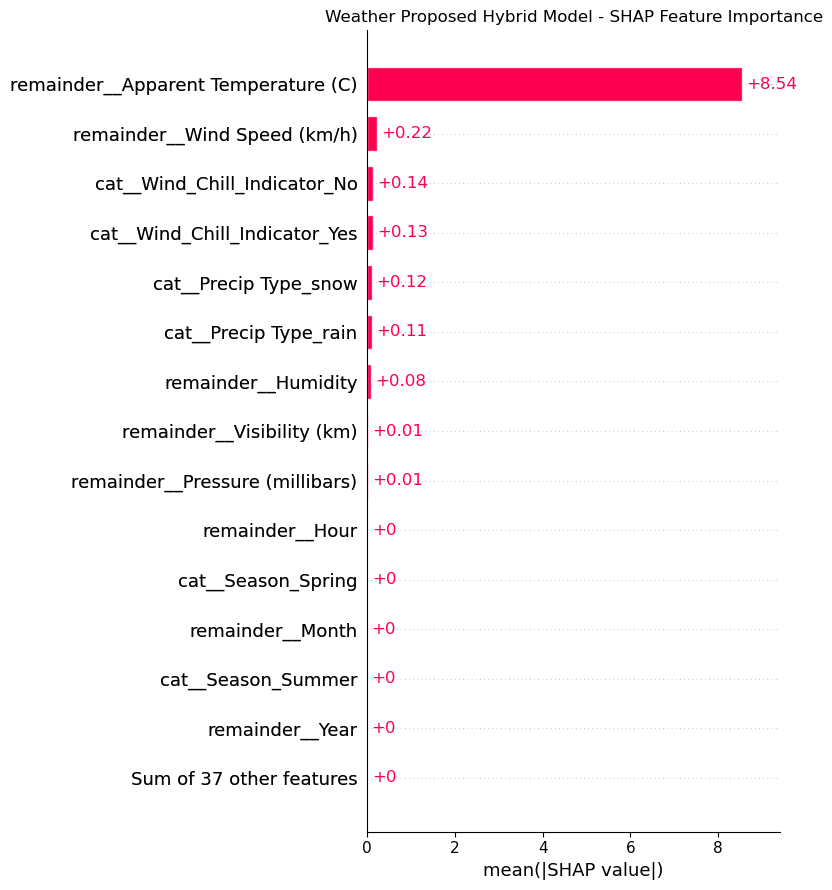

Saved: ../../SHAP_Results/Weather/Images\weather_proposed_hybrid_shap_bar.png


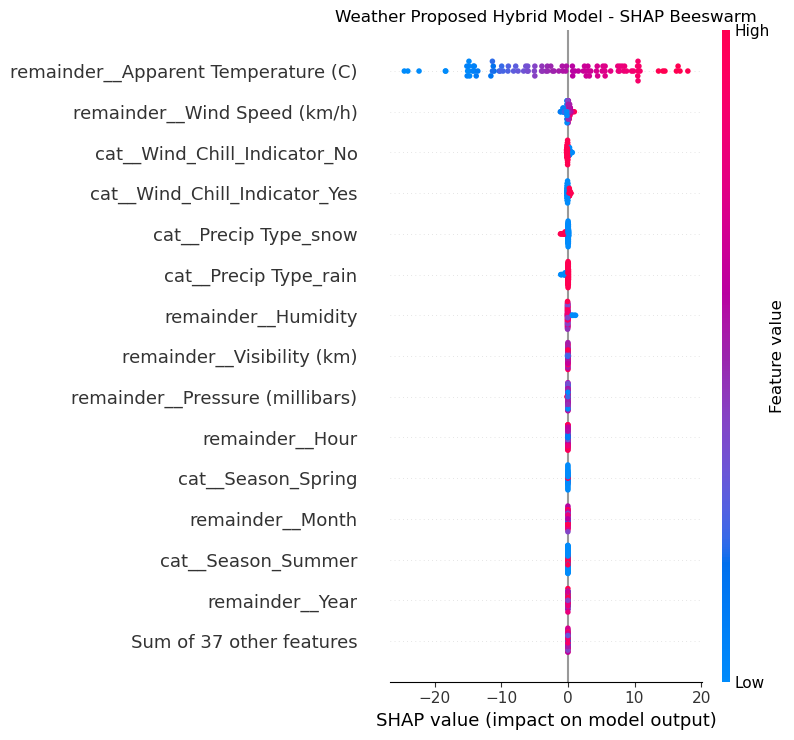

Saved: ../../SHAP_Results/Weather/Images\weather_proposed_hybrid_shap_beeswarm.png


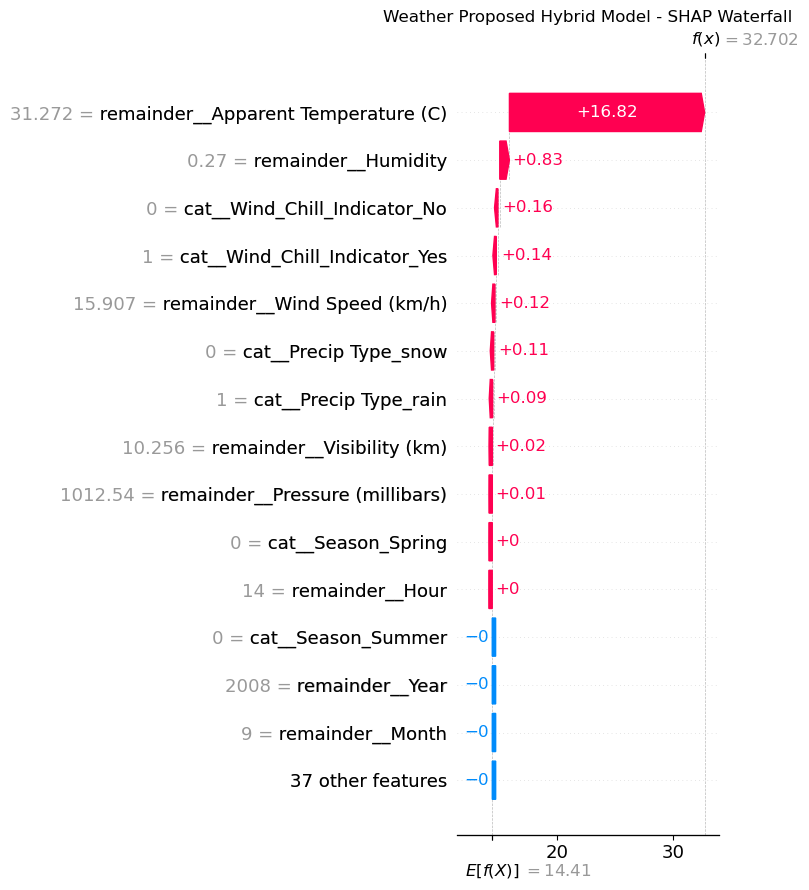

Saved: ../../SHAP_Results/Weather/Images\weather_proposed_hybrid_shap_waterfall.png

Weather SHAP images created successfully:
1. ../../SHAP_Results/Weather/Images\weather_proposed_hybrid_shap_bar.png
2. ../../SHAP_Results/Weather/Images\weather_proposed_hybrid_shap_beeswarm.png
3. ../../SHAP_Results/Weather/Images\weather_proposed_hybrid_shap_waterfall.png


In [89]:
# ============================================================
# 9.6.12 - Create Weather SHAP Plots
# ============================================================

print(
    "Creating Weather SHAP plots...\n"
)

# ------------------------------------------------------------
# 1. SHAP Bar Plot
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

shap.plots.bar(
    shap_values_weather,
    max_display=15,
    show=False
)

plt.title(
    "Weather Proposed Hybrid Model - SHAP Feature Importance"
)

plt.tight_layout()

weather_bar_path = os.path.join(
    weather_shap_images_dir,
    "weather_proposed_hybrid_shap_bar.png"
)

plt.savefig(
    weather_bar_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    weather_bar_path
)


# ------------------------------------------------------------
# 2. SHAP Beeswarm Plot
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

shap.plots.beeswarm(
    shap_values_weather,
    max_display=15,
    show=False
)

plt.title(
    "Weather Proposed Hybrid Model - SHAP Beeswarm"
)

plt.tight_layout()

weather_beeswarm_path = os.path.join(
    weather_shap_images_dir,
    "weather_proposed_hybrid_shap_beeswarm.png"
)

plt.savefig(
    weather_beeswarm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    weather_beeswarm_path
)


# ------------------------------------------------------------
# 3. SHAP Waterfall Plot
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

shap.plots.waterfall(
    shap_values_weather[0],
    max_display=15,
    show=False
)

plt.title(
    "Weather Proposed Hybrid Model - SHAP Waterfall"
)

plt.tight_layout()

weather_waterfall_path = os.path.join(
    weather_shap_images_dir,
    "weather_proposed_hybrid_shap_waterfall.png"
)

plt.savefig(
    weather_waterfall_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    weather_waterfall_path
)


# ------------------------------------------------------------
# 4. Final verification
# ------------------------------------------------------------

print(
    "\nWeather SHAP images created successfully:"
)

print(
    "1.",
    weather_bar_path
)

print(
    "2.",
    weather_beeswarm_path
)

print(
    "3.",
    weather_waterfall_path
)

In [91]:
# ============================================================
# 9.6.13A - Find Existing Energy Hybrid Model Variables
# ============================================================

print(
    "Checking existing Energy hybrid model variables...\n"
)

# Find variables containing "energy"
energy_variables = [
    name
    for name in globals()
    if "energy" in name.lower()
]

print(
    "Energy-related variables found:\n"
)

for name in sorted(energy_variables):
    print(name)

Checking existing Energy hybrid model variables...

Energy-related variables found:

X_energy_c14
X_test_energy_c14
X_test_energy_encoded_c14
X_test_energy_scaled_c14
X_train_energy_c14
X_train_energy_encoded_c14
X_train_energy_scaled_c14
catboost_energy_c14
energy_c14
energy_categorical_c14
energy_feature_names_c14
energy_features_c14
energy_model_comparison_c14
energy_numeric_check_c14
energy_numerical_c14
energy_preprocessor_c14
energy_target_c14
hgb_energy_c14
poly_ridge_energy_c14
ridge_energy_c14
svr_energy_c14
temp_model_energy_c14
y_energy_c14
y_pred_energy_catboost_c14
y_pred_energy_hgb_c14
y_pred_energy_poly_c14
y_pred_energy_svr_c14
y_pred_ridge_energy_c14
y_pred_temp_energy_c14
y_test_energy_c14
y_train_energy_c14


In [93]:
# ============================================================
# 9.6.13B - Find Energy Proposed Hybrid Model Variables
#              FIXED VERSION
# ============================================================

print(
    "Searching for Energy proposed hybrid model variables...\n"
)

keywords = [
    "meta",
    "hybrid",
    "oof",
    "lr_final",
    "cb_final",
    "gb_final"
]

matching_variables = []

# Take a snapshot of variable names first
all_variable_names = list(
    globals().keys()
)

for name in all_variable_names:

    name_lower = name.lower()

    if any(
        keyword in name_lower
        for keyword in keywords
    ):
        matching_variables.append(name)


print(
    "Potential hybrid-related variables:\n"
)

for name in sorted(
    matching_variables
):
    print(name)

Searching for Energy proposed hybrid model variables...

Potential hybrid-related variables:

X_air_hybrid
X_meta_air
X_meta_cat_c14
X_meta_correct
X_meta_gb_c14
X_meta_lrcbgb_c14
X_meta_test_air
X_meta_test_air_shap
X_meta_test_lrcbgb_c14
X_meta_test_weather
X_meta_test_weather_no_app
X_meta_test_weather_shap
X_meta_three_c14
X_meta_weather
X_meta_weather_no_app
X_meta_weather_shap
X_test_air_hybrid
X_test_meta_cat_c14
X_test_meta_gb_c14
X_test_weather_hybrid
X_train_air_hybrid
X_train_weather_hybrid
X_weather_hybrid
cb_final_air
cb_final_lrcbgb_c14
cb_final_three_c14
cb_final_weather
cb_final_weather_no_app
df_air_hybrid
df_weather_hybrid
gb_final_air
gb_final_c14
gb_final_lrcbgb_c14
gb_final_weather
gb_final_weather_no_app
hybrid_adjusted_r2
hybrid_ev
hybrid_mape
hybrid_max_error
hybrid_median_ae
hybrid_nrmse
hybrid_r2
kf_air_hybrid
kf_weather_hybrid
lr_final_air
lr_final_cat_c14
lr_final_gb_c14
lr_final_lrcbgb_c14
lr_final_three_c14
lr_final_weather
lr_final_weather_no_app
mae_air_

In [95]:
# ============================================================
# 9.6.13C - Verify Final Energy Proposed Hybrid Model
# ============================================================

print(
    "Verifying the final Energy proposed hybrid model...\n"
)

# ------------------------------------------------------------
# 1. Exact final Energy hybrid models
# ------------------------------------------------------------

energy_lr_model = lr_final_lrcbgb_c14
energy_cb_model = cb_final_lrcbgb_c14
energy_gb_model = gb_final_lrcbgb_c14
energy_meta_model = meta_lr_lrcbgb_c14

print("Energy final models identified successfully.")

print(
    "\nLinear Regression:",
    type(energy_lr_model).__name__
)

print(
    "CatBoost:",
    type(energy_cb_model).__name__
)

print(
    "Gradient Boosting:",
    type(energy_gb_model).__name__
)

print(
    "Meta-model:",
    type(energy_meta_model).__name__
)


# ------------------------------------------------------------
# 2. Exact model features
# ------------------------------------------------------------

energy_model_features = list(
    energy_cb_model.feature_names_
)

print(
    "\nNumber of Energy model features:",
    len(energy_model_features)
)

print("\nEnergy model features:")
print(energy_model_features)


# ------------------------------------------------------------
# 3. Existing encoded train/test data
# ------------------------------------------------------------

print(
    "\nExisting Energy encoded train shape:",
    X_train_energy_encoded_c14.shape
)

print(
    "Existing Energy encoded test shape:",
    X_test_energy_encoded_c14.shape
)


# ------------------------------------------------------------
# 4. Compare feature counts
# ------------------------------------------------------------

print(
    "\nCatBoost expected features:",
    len(energy_cb_model.feature_names_)
)

print(
    "Encoded training features:",
    X_train_energy_encoded_c14.shape[1]
)

print(
    "Encoded test features:",
    X_test_energy_encoded_c14.shape[1]
)


# ------------------------------------------------------------
# 5. Test final base models
# ------------------------------------------------------------

print(
    "\nTesting final Energy base models..."
)

pred_lr_energy_check = energy_lr_model.predict(
    X_test_energy_encoded_c14
)

pred_cb_energy_check = energy_cb_model.predict(
    X_test_energy_encoded_c14
)

pred_gb_energy_check = energy_gb_model.predict(
    X_test_energy_encoded_c14
)


# ------------------------------------------------------------
# 6. Final hybrid prediction
# ------------------------------------------------------------

X_meta_energy_check = np.column_stack([
    pred_lr_energy_check,
    pred_cb_energy_check,
    pred_gb_energy_check
])

pred_hybrid_energy_check = energy_meta_model.predict(
    X_meta_energy_check
)


# ------------------------------------------------------------
# 7. Prediction statistics
# ------------------------------------------------------------

print(
    "\nFinal Energy hybrid prediction statistics:"
)

print(
    "Minimum:",
    pred_hybrid_energy_check.min()
)

print(
    "Maximum:",
    pred_hybrid_energy_check.max()
)

print(
    "Mean:",
    pred_hybrid_energy_check.mean()
)

print(
    "Standard deviation:",
    pred_hybrid_energy_check.std()
)


# ------------------------------------------------------------
# 8. Actual target statistics
# ------------------------------------------------------------

print(
    "\nActual Energy target statistics:"
)

print(
    "Minimum:",
    y_test_energy_c14.min()
)

print(
    "Maximum:",
    y_test_energy_c14.max()
)

print(
    "Mean:",
    y_test_energy_c14.mean()
)

print(
    "Standard deviation:",
    y_test_energy_c14.std()
)


# ------------------------------------------------------------
# 9. First 10 predictions
# ------------------------------------------------------------

energy_verification = pd.DataFrame({
    "Actual": np.asarray(
        y_test_energy_c14
    )[:10],

    "Hybrid_Predicted": pred_hybrid_energy_check[:10],

    "LR_Predicted": pred_lr_energy_check[:10],

    "CatBoost_Predicted": pred_cb_energy_check[:10],

    "GB_Predicted": pred_gb_energy_check[:10]
})

print(
    "\nFirst 10 Energy predictions:"
)

display(
    energy_verification
)

Verifying the final Energy proposed hybrid model...

Energy final models identified successfully.

Linear Regression: LinearRegression
CatBoost: CatBoostRegressor
Gradient Boosting: GradientBoostingRegressor
Meta-model: LinearRegression

Number of Energy model features: 19

Energy model features:
['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18']

Existing Energy encoded train shape: (800, 19)
Existing Energy encoded test shape: (200, 19)

CatBoost expected features: 19
Encoded training features: 19
Encoded test features: 19

Testing final Energy base models...

Final Energy hybrid prediction statistics:
Minimum: 64.28642367761566
Maximum: 89.21614162945276
Mean: 77.00272920290118
Standard deviation: 6.2097331302670895

Actual Energy target statistics:
Minimum: 58.09700995500931
Maximum: 98.76175414998474
Mean: 77.08195029880147
Standard deviation: 8.113508528381377

First 10 Energy predictions:


,Actual,Hybrid_Predicted,LR_Predicted,CatBoost_Predicted,GB_Predicted
0,86.920611,83.522530,83.505426,83.531947,82.281374
1,88.351606,80.811083,81.246310,79.989968,80.833026
2,79.431363,76.009758,75.821840,76.293831,75.275058
3,90.009188,87.741685,88.240500,86.693645,86.558989
4,83.891100,75.093542,75.345495,74.573465,75.372579
5,87.549041,81.793951,80.923272,84.952878,85.025676
6,79.697237,78.680683,78.711368,78.548051,77.971769
7,80.914057,72.435606,72.929673,71.186475,72.480535
8,85.133856,77.592527,77.779346,77.005400,76.708658
9,71.017140,67.619209,67.828597,67.026226,68.234482


In [97]:
# ============================================================
# 9.6.14 - Prepare Energy SHAP Input - FIXED
# ============================================================

print(
    "Preparing Energy data for SHAP...\n"
)

# ------------------------------------------------------------
# 1. Use exact model features
# ------------------------------------------------------------

energy_model_features = list(
    energy_cb_model.feature_names_
)

print(
    "Number of Energy model features:",
    len(energy_model_features)
)


# ------------------------------------------------------------
# 2. Convert existing encoded arrays to DataFrames
# ------------------------------------------------------------

X_train_energy_shap = pd.DataFrame(
    X_train_energy_encoded_c14,
    columns=energy_model_features
)

X_test_energy_shap = pd.DataFrame(
    X_test_energy_encoded_c14,
    columns=energy_model_features
)


print(
    "\nEnergy train SHAP matrix:",
    X_train_energy_shap.shape
)

print(
    "Energy test SHAP matrix:",
    X_test_energy_shap.shape
)


# ------------------------------------------------------------
# 3. Select SHAP background
# ------------------------------------------------------------

background_energy_shap = (
    X_train_energy_shap
    .sample(
        n=30,
        random_state=42
    )
)


# ------------------------------------------------------------
# 4. Select test observations for explanation
# ------------------------------------------------------------

X_shap_energy = (
    X_test_energy_shap
    .sample(
        n=100,
        random_state=42
    )
)


print(
    "\nSHAP background shape:",
    background_energy_shap.shape
)

print(
    "SHAP explanation shape:",
    X_shap_energy.shape
)


# ------------------------------------------------------------
# 5. Check feature statistics
# ------------------------------------------------------------

print(
    "\nEnergy SHAP feature statistics:"
)

display(
    X_shap_energy.describe().T[
        ["min", "max", "mean", "std"]
    ]
)


# ------------------------------------------------------------
# 6. Check unique values
# ------------------------------------------------------------

print(
    "\nUnique values per Energy feature:"
)

display(
    X_shap_energy.nunique()
)

Preparing Energy data for SHAP...

Number of Energy model features: 19

Energy train SHAP matrix: (800, 19)
Energy test SHAP matrix: (200, 19)

SHAP background shape: (30, 19)
SHAP explanation shape: (100, 19)

Energy SHAP feature statistics:


,min,max,mean,std
0,0.000000,1.000000,0.430000,0.497570
1,0.000000,1.000000,0.530000,0.501614
2,0.000000,1.000000,0.090000,0.287623
3,0.000000,1.000000,0.160000,0.368453
4,0.000000,1.000000,0.190000,0.394277
5,0.000000,1.000000,0.160000,0.368453
6,0.000000,1.000000,0.140000,0.348735
7,0.000000,1.000000,0.120000,0.326599
8,0.000000,1.000000,0.600000,0.492366
9,0.000000,1.000000,0.350000,0.479372



Unique values per Energy feature:


0       2
1       2
2       2
3       2
4       2
5       2
6       2
7       2
8       2
9       2
10    100
11    100
12    100
13     10
14    100
15     23
16      2
17      2
18      2
dtype: int64

In [99]:
# ============================================================
# 9.6.15 - Calculate Energy SHAP Values - FIXED
# ============================================================

print(
    "Calculating Energy SHAP values...\n"
)


# ------------------------------------------------------------
# 1. Define hybrid prediction function
# ------------------------------------------------------------

def predict_hybrid_energy_shap(X):

    # Always convert to NumPy
    X = np.asarray(X)

    # Base model predictions
    pred_lr = energy_lr_model.predict(X)

    pred_cb = energy_cb_model.predict(X)

    pred_gb = energy_gb_model.predict(X)


    # Stack base model predictions
    X_meta = np.column_stack([
        pred_lr,
        pred_cb,
        pred_gb
    ])


    # Final hybrid prediction
    return energy_meta_model.predict(X_meta)


# ------------------------------------------------------------
# 2. Test prediction function
# ------------------------------------------------------------

test_energy_predictions = (
    predict_hybrid_energy_shap(
        X_shap_energy.head(5)
    )
)

print(
    "Test hybrid predictions:"
)

print(
    test_energy_predictions
)


# ------------------------------------------------------------
# 3. Create permutation SHAP explainer
# ------------------------------------------------------------

explainer_energy_shap = shap.Explainer(
    predict_hybrid_energy_shap,
    background_energy_shap,
    feature_names=energy_model_features,
    algorithm="permutation"
)


# ------------------------------------------------------------
# 4. Calculate SHAP values
# ------------------------------------------------------------

shap_values_energy = (
    explainer_energy_shap(
        X_shap_energy
    )
)


# ------------------------------------------------------------
# 5. Verify SHAP output
# ------------------------------------------------------------

print(
    "\nEnergy SHAP calculation completed!"
)

print(
    "SHAP values shape:",
    shap_values_energy.values.shape
)

print(
    "Expected shape:",
    X_shap_energy.shape
)


# ------------------------------------------------------------
# 6. SHAP statistics
# ------------------------------------------------------------

print(
    "\nSHAP value statistics:"
)

print(
    "Minimum:",
    shap_values_energy.values.min()
)

print(
    "Maximum:",
    shap_values_energy.values.max()
)

print(
    "Mean absolute SHAP:",
    np.abs(
        shap_values_energy.values
    ).mean()
)


# ------------------------------------------------------------
# 7. Count near-zero features
# ------------------------------------------------------------

mean_abs_shap_energy = (
    np.abs(
        shap_values_energy.values
    ).mean(axis=0)
)

near_zero_energy = (
    mean_abs_shap_energy < 1e-4
).sum()

print(
    "\nNear-zero features:",
    near_zero_energy,
    "/",
    len(energy_model_features)
)

Calculating Energy SHAP values...

Test hybrid predictions:
[88.03256743 71.1512746  70.22126114 74.17307159 73.93631047]


PermutationExplainer explainer: 101it [00:19,  2.48it/s]                         


Energy SHAP calculation completed!
SHAP values shape: (100, 19)
Expected shape: (100, 19)

SHAP value statistics:
Minimum: -8.691082422471148
Maximum: 10.421573467409354
Mean absolute SHAP: 0.6103117915713774

Near-zero features: 0 / 19


In [100]:
# ============================================================
# 9.6.16 - Energy SHAP Feature Importance
# ============================================================

print(
    "Creating Energy SHAP feature importance...\n"
)


# ------------------------------------------------------------
# 1. Calculate mean absolute SHAP value
# ------------------------------------------------------------

mean_abs_shap_energy = (
    np.abs(
        shap_values_energy.values
    ).mean(axis=0)
)


# ------------------------------------------------------------
# 2. Create importance table
# ------------------------------------------------------------

energy_shap_importance = pd.DataFrame({
    "Feature": energy_model_features,
    "Mean_Absolute_SHAP": mean_abs_shap_energy
})


# ------------------------------------------------------------
# 3. Sort by importance
# ------------------------------------------------------------

energy_shap_importance = (
    energy_shap_importance
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 4. Calculate percentage contribution
# ------------------------------------------------------------

total_importance_energy = (
    energy_shap_importance[
        "Mean_Absolute_SHAP"
    ].sum()
)

energy_shap_importance[
    "Importance_Percentage"
] = (
    energy_shap_importance[
        "Mean_Absolute_SHAP"
    ]
    / total_importance_energy
    * 100
)


# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

print(
    "Energy SHAP Feature Importance:"
)

display(
    energy_shap_importance
)


# ------------------------------------------------------------
# 6. Display top 10 features
# ------------------------------------------------------------

print(
    "\nTop 10 Energy Features:"
)

display(
    energy_shap_importance.head(10)
)


# ------------------------------------------------------------
# 7. Verify total percentage
# ------------------------------------------------------------

print(
    "\nTotal importance percentage:",
    energy_shap_importance[
        "Importance_Percentage"
    ].sum()
)

Creating Energy SHAP feature importance...

Energy SHAP Feature Importance:


,Feature,Mean_Absolute_SHAP,Importance_Percentage
0,10,5.215054,44.973167
1,13,1.168686,10.078422
2,0,1.132936,9.770120
3,17,1.089162,9.392629
4,14,0.665373,5.737990
5,1,0.424174,3.657954
6,18,0.392130,3.381620
7,11,0.272409,2.349177
8,8,0.254736,2.196772
9,12,0.251935,2.172619



Top 10 Energy Features:


,Feature,Mean_Absolute_SHAP,Importance_Percentage
0,10,5.215054,44.973167
1,13,1.168686,10.078422
2,0,1.132936,9.770120
3,17,1.089162,9.392629
4,14,0.665373,5.737990
5,1,0.424174,3.657954
6,18,0.392130,3.381620
7,11,0.272409,2.349177
8,8,0.254736,2.196772
9,12,0.251935,2.172619



Total importance percentage: 99.99999999999997


In [101]:
# ============================================================
# 9.6.17 - Save Energy SHAP Importance Table
# ============================================================

print(
    "Saving Energy SHAP importance table...\n"
)


# ------------------------------------------------------------
# 1. Create output folders
# ------------------------------------------------------------

energy_shap_images_path = (
    "../../SHAP_Results/Energy/Images"
)

energy_shap_tables_path = (
    "../../SHAP_Results/Energy/Tables"
)

os.makedirs(
    energy_shap_images_path,
    exist_ok=True
)

os.makedirs(
    energy_shap_tables_path,
    exist_ok=True
)


# ------------------------------------------------------------
# 2. Save feature importance
# ------------------------------------------------------------

energy_importance_file = os.path.join(
    energy_shap_tables_path,
    "energy_proposed_hybrid_shap_importance.xlsx"
)

energy_shap_importance.to_excel(
    energy_importance_file,
    index=False
)


# ------------------------------------------------------------
# 3. Verify file
# ------------------------------------------------------------

print(
    "Energy SHAP importance saved successfully!"
)

print(
    energy_importance_file
)

print(
    "\nRows saved:",
    len(energy_shap_importance)
)

print(
    "Columns saved:",
    list(
        energy_shap_importance.columns
    )
)

Saving Energy SHAP importance table...

Energy SHAP importance saved successfully!
../../SHAP_Results/Energy/Tables\energy_proposed_hybrid_shap_importance.xlsx

Rows saved: 19
Columns saved: ['Feature', 'Mean_Absolute_SHAP', 'Importance_Percentage']


In [103]:
# ============================================================
# 9.6.18 - Save Energy SHAP Values and Predictions - FIXED
# ============================================================

print(
    "Saving Energy SHAP values and predictions...\n"
)


# ------------------------------------------------------------
# 1. SHAP values table
# ------------------------------------------------------------

energy_shap_values_df = pd.DataFrame(
    shap_values_energy.values,
    columns=energy_model_features
)


# ------------------------------------------------------------
# 2. Generate base-model predictions
# ------------------------------------------------------------

X_shap_energy_array = (
    X_shap_energy.values
)

pred_lr_energy_shap = (
    energy_lr_model.predict(
        X_shap_energy_array
    )
)

pred_cb_energy_shap = (
    energy_cb_model.predict(
        X_shap_energy_array
    )
)

pred_gb_energy_shap = (
    energy_gb_model.predict(
        X_shap_energy_array
    )
)


# ------------------------------------------------------------
# 3. Generate final hybrid predictions
# ------------------------------------------------------------

pred_hybrid_energy_shap = (
    predict_hybrid_energy_shap(
        X_shap_energy_array
    )
)


# ------------------------------------------------------------
# 4. Get actual target values
# ------------------------------------------------------------

# X_shap_energy contains a random sample of 100 rows
# from the 200-row Energy test set.
# Use the same positional indices from X_test_energy_encoded_c14.

energy_test_positions = (
    X_shap_energy.index.to_numpy()
)

actual_energy_shap = (
    np.asarray(y_test_energy_c14)[
        energy_test_positions
    ]
)


# ------------------------------------------------------------
# 5. Create prediction table
# ------------------------------------------------------------

energy_shap_predictions_df = pd.DataFrame({

    "Actual_Energy":
        actual_energy_shap,

    "Linear_Regression":
        pred_lr_energy_shap,

    "CatBoost":
        pred_cb_energy_shap,

    "Gradient_Boosting":
        pred_gb_energy_shap,

    "Proposed_Hybrid":
        pred_hybrid_energy_shap

})


# ------------------------------------------------------------
# 6. Save SHAP values
# ------------------------------------------------------------

energy_shap_values_file = os.path.join(
    energy_shap_tables_path,
    "energy_proposed_hybrid_shap_values.xlsx"
)

energy_shap_values_df.to_excel(
    energy_shap_values_file,
    index=False
)


# ------------------------------------------------------------
# 7. Save predictions
# ------------------------------------------------------------

energy_shap_predictions_file = os.path.join(
    energy_shap_tables_path,
    "energy_proposed_hybrid_shap_predictions.xlsx"
)

energy_shap_predictions_df.to_excel(
    energy_shap_predictions_file,
    index=False
)


# ------------------------------------------------------------
# 8. Verify
# ------------------------------------------------------------

print(
    "Energy SHAP values saved successfully!"
)

print(
    energy_shap_values_file
)

print(
    "\nEnergy SHAP predictions saved successfully!"
)

print(
    energy_shap_predictions_file
)


# ------------------------------------------------------------
# 9. Display previews
# ------------------------------------------------------------

print(
    "\nSHAP Values Preview:"
)

display(
    energy_shap_values_df.head()
)


print(
    "\nPredictions Preview:"
)

display(
    energy_shap_predictions_df.head()
)


# ------------------------------------------------------------
# 10. Verify row counts
# ------------------------------------------------------------

print(
    "\nSHAP value rows:",
    len(energy_shap_values_df)
)

print(
    "Prediction rows:",
    len(energy_shap_predictions_df)
)

Saving Energy SHAP values and predictions...

Energy SHAP values saved successfully!
../../SHAP_Results/Energy/Tables\energy_proposed_hybrid_shap_values.xlsx

Energy SHAP predictions saved successfully!
../../SHAP_Results/Energy/Tables\energy_proposed_hybrid_shap_predictions.xlsx

SHAP Values Preview:


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
0,1.041067,-0.343514,0.005700,-0.044819,0.015964,-0.045296,0.130223,0.010114,0.238989,-0.047613,8.785839,-0.027168,-0.316074,2.027417,-0.214680,0.014332,-0.157354,0.975246,-0.290157
1,-1.131209,0.403811,-0.011411,-0.061371,-0.062302,-0.061232,0.004929,0.012726,-0.196190,0.051914,-4.016561,-0.755059,0.285826,-0.482725,1.255818,-0.016081,0.358204,-1.138074,0.435908
2,1.039661,-0.306951,-0.014130,0.190212,0.014287,-0.048883,-0.004321,0.013893,-0.228341,0.075195,-7.639279,0.208955,0.409619,-0.806682,0.470993,-0.012131,-0.160329,1.017967,-0.272827
3,-1.245274,-0.280693,0.007220,-0.126405,0.012742,-0.074829,-0.002279,0.018535,-0.284828,-0.046080,3.101747,0.141022,0.422764,-1.922329,-0.146162,-0.099592,-0.123025,-1.175637,-0.278179
4,-1.164584,-0.239556,-0.009989,-0.069030,0.014775,-0.070729,-0.094419,0.019024,-0.185614,-0.042780,0.863368,0.088667,-0.151798,-1.853431,1.440202,0.185929,0.349105,-1.149766,-0.267415



Predictions Preview:


,Actual_Energy,Linear_Regression,CatBoost,Gradient_Boosting,Proposed_Hybrid
0,91.007122,88.674366,86.957002,87.980978,88.032567
1,72.992079,71.642801,69.715350,70.641114,71.151275
2,68.243502,70.164208,70.226936,70.371066,70.221261
3,77.673792,74.637825,73.094731,74.369277,74.173072
4,77.120780,73.875245,74.001614,73.782856,73.936310



SHAP value rows: 100
Prediction rows: 100


Creating Energy SHAP bar plot...



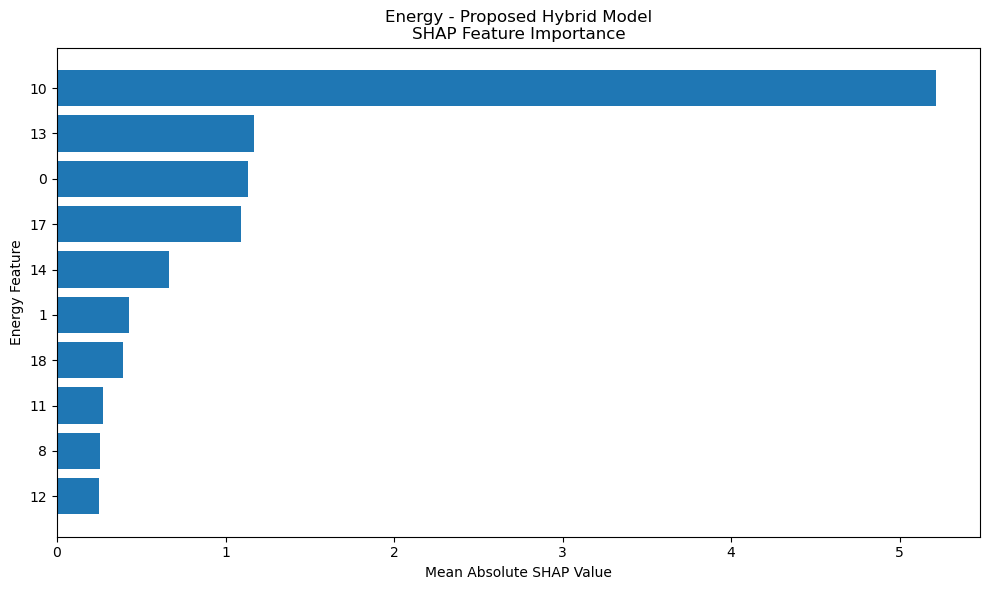


Energy SHAP bar plot saved successfully!
../../SHAP_Results/Energy/Images\energy_proposed_hybrid_shap_bar.png


In [104]:
# ============================================================
# 9.6.19 - Energy SHAP Bar Plot
# ============================================================

print(
    "Creating Energy SHAP bar plot...\n"
)


# ------------------------------------------------------------
# 1. Select top 10 features
# ------------------------------------------------------------

top_energy_features = (
    energy_shap_importance
    .head(10)
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=True
    )
)


# ------------------------------------------------------------
# 2. Create figure
# ------------------------------------------------------------

plt.figure(
    figsize=(10, 6)
)


# ------------------------------------------------------------
# 3. Create horizontal bar plot
# ------------------------------------------------------------

plt.barh(
    top_energy_features["Feature"],
    top_energy_features["Mean_Absolute_SHAP"]
)


# ------------------------------------------------------------
# 4. Labels and title
# ------------------------------------------------------------

plt.xlabel(
    "Mean Absolute SHAP Value"
)

plt.ylabel(
    "Energy Feature"
)

plt.title(
    "Energy - Proposed Hybrid Model\n"
    "SHAP Feature Importance"
)


# ------------------------------------------------------------
# 5. Layout
# ------------------------------------------------------------

plt.tight_layout()


# ------------------------------------------------------------
# 6. Save image
# ------------------------------------------------------------

energy_bar_file = os.path.join(
    energy_shap_images_path,
    "energy_proposed_hybrid_shap_bar.png"
)

plt.savefig(
    energy_bar_file,
    dpi=300,
    bbox_inches="tight"
)


# ------------------------------------------------------------
# 7. Display
# ------------------------------------------------------------

plt.show()


print(
    "\nEnergy SHAP bar plot saved successfully!"
)

print(
    energy_bar_file
)

Creating Energy SHAP beeswarm plot...



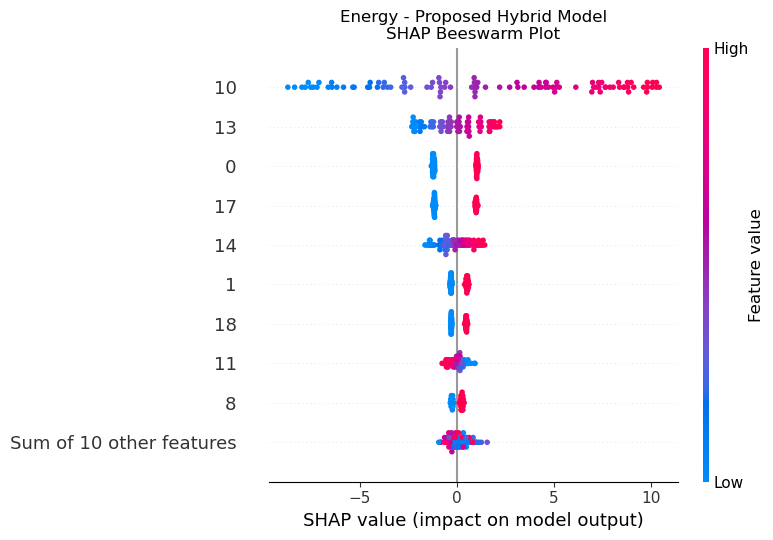


Energy SHAP beeswarm plot saved successfully!
../../SHAP_Results/Energy/Images\energy_proposed_hybrid_shap_beeswarm.png


In [105]:
# ============================================================
# 9.6.20 - Energy SHAP Beeswarm Plot
# ============================================================

print(
    "Creating Energy SHAP beeswarm plot...\n"
)


# ------------------------------------------------------------
# 1. Create figure
# ------------------------------------------------------------

plt.figure(
    figsize=(10, 7)
)


# ------------------------------------------------------------
# 2. Create SHAP beeswarm plot
# ------------------------------------------------------------

shap.plots.beeswarm(
    shap_values_energy,
    max_display=10,
    show=False
)


# ------------------------------------------------------------
# 3. Add title
# ------------------------------------------------------------

plt.title(
    "Energy - Proposed Hybrid Model\n"
    "SHAP Beeswarm Plot"
)


# ------------------------------------------------------------
# 4. Adjust layout
# ------------------------------------------------------------

plt.tight_layout()


# ------------------------------------------------------------
# 5. Save image
# ------------------------------------------------------------

energy_beeswarm_file = os.path.join(
    energy_shap_images_path,
    "energy_proposed_hybrid_shap_beeswarm.png"
)

plt.savefig(
    energy_beeswarm_file,
    dpi=300,
    bbox_inches="tight"
)


# ------------------------------------------------------------
# 6. Display
# ------------------------------------------------------------

plt.show()


print(
    "\nEnergy SHAP beeswarm plot saved successfully!"
)

print(
    energy_beeswarm_file
)

Creating Energy SHAP waterfall plot...



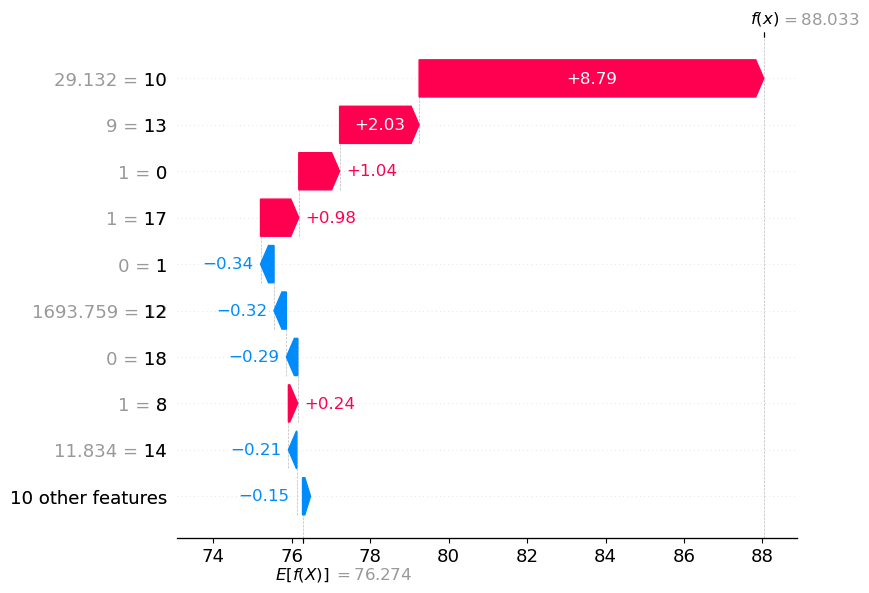


Energy SHAP waterfall plot saved successfully!
../../SHAP_Results/Energy/Images\energy_proposed_hybrid_shap_waterfall.png


In [106]:
# ============================================================
# 9.6.21 - Energy SHAP Waterfall Plot
# ============================================================

print(
    "Creating Energy SHAP waterfall plot...\n"
)


# ------------------------------------------------------------
# 1. Select one Energy observation
# ------------------------------------------------------------

energy_waterfall_index = 0


# ------------------------------------------------------------
# 2. Create waterfall plot
# ------------------------------------------------------------

plt.figure(
    figsize=(10, 7)
)

shap.plots.waterfall(
    shap_values_energy[
        energy_waterfall_index
    ],
    max_display=10,
    show=False
)


# ------------------------------------------------------------
# 3. Save image
# ------------------------------------------------------------

energy_waterfall_file = os.path.join(
    energy_shap_images_path,
    "energy_proposed_hybrid_shap_waterfall.png"
)

plt.savefig(
    energy_waterfall_file,
    dpi=300,
    bbox_inches="tight"
)


# ------------------------------------------------------------
# 4. Display
# ------------------------------------------------------------

plt.show()


print(
    "\nEnergy SHAP waterfall plot saved successfully!"
)

print(
    energy_waterfall_file
)

In [107]:
# ============================================================
# STEP 10.1.1 — CHECK EXISTING WEATHER & ENERGY VARIABLES
# ============================================================

# Safely capture current notebook variables
globals_snapshot = dict(globals())

print("WEATHER-RELATED VARIABLES:")
for name in globals_snapshot:
    if "weather" in name.lower():
        print(" -", name)

print("\nENERGY-RELATED VARIABLES:")
for name in globals_snapshot:
    if "energy" in name.lower():
        print(" -", name)

WEATHER-RELATED VARIABLES:
 - weather_c14
 - weather_features_c14
 - weather_target_c14
 - X_weather_c14
 - y_weather_c14
 - X_train_weather_c14
 - X_test_weather_c14
 - y_train_weather_c14
 - y_test_weather_c14
 - weather_categorical_c14
 - weather_numerical_c14
 - weather_preprocessor_c14
 - X_train_weather_encoded_c14
 - X_test_weather_encoded_c14
 - X_train_weather_scaled_c14
 - X_test_weather_scaled_c14
 - ridge_weather_c14
 - y_pred_ridge_weather_c14
 - weather_path
 - df_weather_hybrid
 - target_weather_hybrid
 - leakage_weather
 - drop_weather
 - X_weather_hybrid
 - y_weather_hybrid
 - categorical_weather
 - numeric_weather
 - preprocessor_weather_hybrid
 - X_weather_encoded
 - feature_names_weather
 - X_train_weather_hybrid
 - X_test_weather_hybrid
 - y_train_weather_hybrid
 - y_test_weather_hybrid
 - kf_weather_hybrid
 - oof_lr_weather
 - oof_cb_weather
 - oof_gb_weather
 - lr_fold_weather
 - cb_fold_weather
 - gb_fold_weather
 - X_meta_weather
 - meta_lr_weather
 - lr_final_

In [108]:
# ============================================================
# STEP 10.1.1 — INSPECT C14 WEATHER & ENERGY DATA
# ============================================================

print("=" * 70)
print("WEATHER C14")
print("=" * 70)

print("Shape:", weather_c14.shape)
print("\nColumns:")
print(weather_c14.columns.tolist())

print("\nFirst 5 rows:")
display(weather_c14.head())


print("\n" + "=" * 70)
print("ENERGY C14")
print("=" * 70)

print("Shape:", energy_c14.shape)
print("\nColumns:")
print(energy_c14.columns.tolist())

print("\nFirst 5 rows:")
display(energy_c14.head())

WEATHER C14
Shape: (96429, 18)

Columns:
['Formatted Date', 'Summary', 'Precip Type', 'Temperature (C)', 'Apparent Temperature (C)', 'Humidity', 'Wind Speed (km/h)', 'Wind Bearing (degrees)', 'Visibility (km)', 'Pressure (millibars)', 'Daily Summary', 'Year', 'Month', 'Hour', 'DayOfWeek', 'Season', 'Temperature_Difference', 'Wind_Chill_Indicator']

First 5 rows:


,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars),Daily Summary,Year,Month,Hour,DayOfWeek,Season,Temperature_Difference,Wind_Chill_Indicator
0,2006-03-31 22:00:00+00:00,Partly Cloudy,rain,9.472222,7.388889,0.89,14.1197,251.0,15.8263,1015.13,Partly cloudy throughout the day.,2006,3,22,Friday,Spring,2.083333,Yes
1,2006-03-31 23:00:00+00:00,Partly Cloudy,rain,9.355556,7.227778,0.86,14.2646,259.0,15.8263,1015.63,Partly cloudy throughout the day.,2006,3,23,Friday,Spring,2.127778,Yes
2,2006-04-01 00:00:00+00:00,Mostly Cloudy,rain,9.377778,9.377778,0.89,3.9284,204.0,14.9569,1015.94,Partly cloudy throughout the day.,2006,4,0,Saturday,Spring,0.000000,No
3,2006-04-01 01:00:00+00:00,Partly Cloudy,rain,8.288889,5.944444,0.83,14.1036,269.0,15.8263,1016.41,Partly cloudy throughout the day.,2006,4,1,Saturday,Spring,2.344444,Yes
4,2006-04-01 02:00:00+00:00,Mostly Cloudy,rain,8.755556,6.977778,0.83,11.0446,259.0,15.8263,1016.51,Partly cloudy throughout the day.,2006,4,2,Saturday,Spring,1.777778,Yes



ENERGY C14
Shape: (1000, 19)

Columns:
['Timestamp', 'Temperature', 'Humidity', 'SquareFootage', 'Occupancy', 'HVACUsage', 'LightingUsage', 'RenewableEnergy', 'DayOfWeek', 'Holiday', 'EnergyConsumption', 'Hour', 'Month', 'Weekend', 'HVAC_Status', 'Lighting_Status', 'Energy_Per_Occupant', 'Renewable_Energy_Ratio', 'Energy_Per_SquareFoot']

First 5 rows:


,Timestamp,Temperature,Humidity,SquareFootage,Occupancy,HVACUsage,LightingUsage,RenewableEnergy,DayOfWeek,Holiday,EnergyConsumption,Hour,Month,Weekend,HVAC_Status,Lighting_Status,Energy_Per_Occupant,Renewable_Energy_Ratio,Energy_Per_SquareFoot
0,2022-01-01 00:00:00,25.139433,43.431581,1565.693999,5,On,Off,2.774699,Monday,No,75.364373,0,1,No,1,0,15.072875,0.036817,0.048135
1,2022-01-01 01:00:00,27.731651,54.225919,1411.064918,1,On,On,21.831384,Saturday,No,83.401855,1,1,Yes,1,1,83.401855,0.261761,0.059106
2,2022-01-01 02:00:00,28.704277,58.907658,1755.715009,2,Off,Off,6.764672,Sunday,No,78.270888,2,1,Yes,0,0,39.135444,0.086426,0.044581
3,2022-01-01 03:00:00,20.080469,50.371637,1452.316318,1,Off,On,8.623447,Wednesday,No,56.519850,3,1,No,0,1,56.519850,0.152574,0.038917
4,2022-01-01 04:00:00,23.097359,51.401421,1094.130359,9,On,Off,3.071969,Friday,No,70.811732,4,1,No,1,0,7.867970,0.043382,0.064720


In [109]:
# ============================================================
# STEP 10.1.2 — VERIFY WEATHER ↔ ENERGY ALIGNMENT
# ============================================================

print("=" * 70)
print("WEATHER C14 TIME COLUMNS")
print("=" * 70)

weather_time_cols = [
    col for col in weather_c14.columns
    if any(word in col.lower() for word in ["year", "month", "day", "hour", "date", "time"])
]

print(weather_time_cols)

print("\n" + "=" * 70)
print("ENERGY C14 TIME COLUMNS")
print("=" * 70)

energy_time_cols = [
    col for col in energy_c14.columns
    if any(word in col.lower() for word in ["year", "month", "day", "hour", "date", "time"])
]

print(energy_time_cols)

print("\n" + "=" * 70)
print("COMMON COLUMNS")
print("=" * 70)

common_columns = sorted(
    set(weather_c14.columns).intersection(set(energy_c14.columns))
)

print(common_columns)

print("\n" + "=" * 70)
print("MONTH + HOUR CHECK")
print("=" * 70)

for col in ["Month", "Hour"]:
    print(
        f"{col}:",
        "Weather =", col in weather_c14.columns,
        "| Energy =", col in energy_c14.columns
    )

WEATHER C14 TIME COLUMNS
['Formatted Date', 'Year', 'Month', 'Hour', 'DayOfWeek']

ENERGY C14 TIME COLUMNS
['Timestamp', 'DayOfWeek', 'Holiday', 'Hour', 'Month']

COMMON COLUMNS
['DayOfWeek', 'Hour', 'Humidity', 'Month']

MONTH + HOUR CHECK
Month: Weather = True | Energy = True
Hour: Weather = True | Energy = True


In [110]:
# ============================================================
# STEP 10.1.3 — CREATE WEATHER ↔ ENERGY ALIGNED DATASET
# ============================================================

# Copy C14 datasets so originals remain unchanged
weather_cross = weather_c14.copy()
energy_cross = energy_c14.copy()

# ------------------------------------------------------------
# 1. Select useful Weather variables
# ------------------------------------------------------------

weather_analysis_cols = [
    "Month",
    "Hour",
    "Apparent Temperature (C)",
    "Humidity",
    "Wind Speed (km/h)",
    "Visibility (km)",
    "Pressure (millibars)"
]

weather_analysis = weather_cross[weather_analysis_cols].copy()


# ------------------------------------------------------------
# 2. Aggregate Weather by Month + Hour
# ------------------------------------------------------------

weather_aggregated = (
    weather_analysis
    .groupby(["Month", "Hour"], as_index=False)
    .agg({
        "Apparent Temperature (C)": "mean",
        "Humidity": "mean",
        "Wind Speed (km/h)": "mean",
        "Visibility (km)": "mean",
        "Pressure (millibars)": "mean"
    })
)


# ------------------------------------------------------------
# 3. Identify Energy target
# ------------------------------------------------------------

print("Energy columns:")
print(energy_cross.columns.tolist())

print("\nEnergy target:")
print(energy_target_c14)


# ------------------------------------------------------------
# 4. Select Energy Month + Hour + Target
# ------------------------------------------------------------

energy_analysis = energy_cross[
    ["Month", "Hour", energy_target_c14]
].copy()


# ------------------------------------------------------------
# 5. Aggregate Energy by Month + Hour
# ------------------------------------------------------------

energy_aggregated = (
    energy_analysis
    .groupby(["Month", "Hour"], as_index=False)
    [energy_target_c14]
    .mean()
)


# ------------------------------------------------------------
# 6. Merge Weather + Energy
# ------------------------------------------------------------

weather_energy_cross = pd.merge(
    weather_aggregated,
    energy_aggregated,
    on=["Month", "Hour"],
    how="inner"
)


# ------------------------------------------------------------
# 7. Display result
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("WEATHER ↔ ENERGY CROSS-DOMAIN DATASET")
print("=" * 70)

print("Shape:", weather_energy_cross.shape)

print("\nColumns:")
print(weather_energy_cross.columns.tolist())

print("\nFirst 10 rows:")
display(weather_energy_cross.head(10))

print("\nMissing values:")
print(weather_energy_cross.isnull().sum())

Energy columns:
['Timestamp', 'Temperature', 'Humidity', 'SquareFootage', 'Occupancy', 'HVACUsage', 'LightingUsage', 'RenewableEnergy', 'DayOfWeek', 'Holiday', 'EnergyConsumption', 'Hour', 'Month', 'Weekend', 'HVAC_Status', 'Lighting_Status', 'Energy_Per_Occupant', 'Renewable_Energy_Ratio', 'Energy_Per_SquareFoot']

Energy target:
EnergyConsumption

WEATHER ↔ ENERGY CROSS-DOMAIN DATASET
Shape: (48, 8)

Columns:
['Month', 'Hour', 'Apparent Temperature (C)', 'Humidity', 'Wind Speed (km/h)', 'Visibility (km)', 'Pressure (millibars)', 'EnergyConsumption']

First 10 rows:


,Month,Hour,Apparent Temperature (C),Humidity,Wind Speed (km/h),Visibility (km),Pressure (millibars),EnergyConsumption
0,1,0,-2.963718,0.883607,10.346729,8.064353,1019.761290,77.677846
1,1,1,-3.252786,0.881056,10.985346,8.196175,1001.607302,79.174420
2,1,2,-3.283399,0.883959,10.520854,8.157979,1007.598886,76.299379
3,1,3,-3.371717,0.889795,10.311224,7.926346,1019.522669,76.489444
4,1,4,-3.598110,0.886041,10.777793,6.872859,998.397713,75.572215
5,1,5,-3.610101,0.887947,10.718917,6.775126,1007.400088,76.786407
6,1,6,-3.637341,0.890528,10.695924,6.348830,1019.668739,77.736117
7,1,7,-3.307739,0.884839,11.017641,6.405959,992.829912,76.400198
8,1,8,-2.569762,0.864516,11.841385,6.765494,990.096246,76.000638
9,1,9,-1.705279,0.841173,12.672447,7.307559,1020.303578,74.717668



Missing values:
Month                       0
Hour                        0
Apparent Temperature (C)    0
Humidity                    0
Wind Speed (km/h)           0
Visibility (km)             0
Pressure (millibars)        0
EnergyConsumption           0
dtype: int64


In [111]:
# ============================================================
# STEP 10.1.4 — WEATHER ↔ ENERGY CORRELATION ANALYSIS
# ============================================================

# Select numerical Weather + Energy variables
correlation_columns = [
    "Apparent Temperature (C)",
    "Humidity",
    "Wind Speed (km/h)",
    "Visibility (km)",
    "Pressure (millibars)",
    energy_target_c14
]

# Calculate correlation matrix
weather_energy_corr = weather_energy_cross[
    correlation_columns
].corr()

print("=" * 70)
print("WEATHER ↔ ENERGY CORRELATION MATRIX")
print("=" * 70)

display(weather_energy_corr)


# ------------------------------------------------------------
# Extract correlations specifically with Energy
# ------------------------------------------------------------

energy_correlations = (
    weather_energy_corr[energy_target_c14]
    .drop(energy_target_c14)
    .sort_values(key=abs, ascending=False)
    .reset_index()
)

energy_correlations.columns = [
    "Weather_Feature",
    "Correlation_with_Energy"
]

print("\n" + "=" * 70)
print("WEATHER FACTORS vs ENERGY CONSUMPTION")
print("=" * 70)

display(energy_correlations)

WEATHER ↔ ENERGY CORRELATION MATRIX


,Apparent Temperature (C),Humidity,Wind Speed (km/h),Visibility (km),Pressure (millibars),EnergyConsumption
Apparent Temperature (C),1.000000,-0.980246,0.798918,0.513496,-0.225060,-0.008803
Humidity,-0.980246,1.000000,-0.877245,-0.444200,0.303697,0.012725
Wind Speed (km/h),0.798918,-0.877245,1.000000,0.210318,-0.439683,-0.019137
Visibility (km),0.513496,-0.444200,0.210318,1.000000,-0.002996,0.050982
Pressure (millibars),-0.225060,0.303697,-0.439683,-0.002996,1.000000,-0.229204
EnergyConsumption,-0.008803,0.012725,-0.019137,0.050982,-0.229204,1.000000



WEATHER FACTORS vs ENERGY CONSUMPTION


,Weather_Feature,Correlation_with_Energy
0,Pressure (millibars),-0.229204
1,Visibility (km),0.050982
2,Wind Speed (km/h),-0.019137
3,Humidity,0.012725
4,Apparent Temperature (C),-0.008803


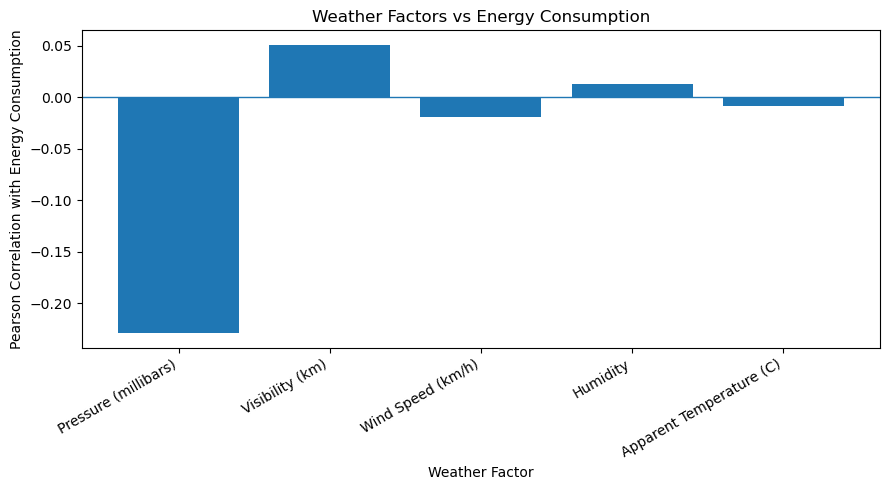

Saved: EDA_Graphs/Cross_Domain\weather_energy_correlation.png


In [112]:
# ============================================================
# STEP 10.1.5 — WEATHER ↔ ENERGY CORRELATION BAR CHART
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    energy_correlations["Weather_Feature"],
    energy_correlations["Correlation_with_Energy"]
)

plt.axhline(0, linewidth=1)

plt.title("Weather Factors vs Energy Consumption")
plt.xlabel("Weather Factor")
plt.ylabel("Pearson Correlation with Energy Consumption")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

# Save figure
cross_domain_image_dir = "EDA_Graphs/Cross_Domain"
os.makedirs(cross_domain_image_dir, exist_ok=True)

weather_energy_corr_path = os.path.join(
    cross_domain_image_dir,
    "weather_energy_correlation.png"
)

plt.savefig(weather_energy_corr_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", weather_energy_corr_path)

In [113]:
# ============================================================
# STEP 10.1.6 — ENERGY vs TEMPERATURE CONDITIONS
# ============================================================

# Create temperature condition groups using quartiles
weather_energy_cross["Temperature_Condition"] = pd.qcut(
    weather_energy_cross["Apparent Temperature (C)"],
    q=4,
    labels=[
        "Low Temperature",
        "Moderate-Low Temperature",
        "Moderate-High Temperature",
        "High Temperature"
    ]
)

# Calculate average energy consumption for each condition
temperature_energy_analysis = (
    weather_energy_cross
    .groupby("Temperature_Condition", observed=True)[energy_target_c14]
    .agg(["mean", "min", "max", "count"])
    .reset_index()
)

temperature_energy_analysis.columns = [
    "Temperature_Condition",
    "Average_Energy",
    "Minimum_Energy",
    "Maximum_Energy",
    "Observations"
]

print("=" * 70)
print("ENERGY CONSUMPTION ACROSS TEMPERATURE CONDITIONS")
print("=" * 70)

display(temperature_energy_analysis)

ENERGY CONSUMPTION ACROSS TEMPERATURE CONDITIONS


,Temperature_Condition,Average_Energy,Minimum_Energy,Maximum_Energy,Observations
0,Low Temperature,77.227294,75.103767,81.470548,12
1,Moderate-Low Temperature,76.868858,73.422548,79.528263,12
2,Moderate-High Temperature,77.667287,73.498772,81.268578,12
3,High Temperature,76.879071,75.451097,79.190263,12


In [114]:
# ============================================================
# STEP 10.1.7 — ENERGY vs HUMIDITY CONDITIONS
# ============================================================

# Create humidity condition groups using quartiles
weather_energy_cross["Humidity_Condition"] = pd.qcut(
    weather_energy_cross["Humidity"],
    q=4,
    labels=[
        "Low Humidity",
        "Moderate-Low Humidity",
        "Moderate-High Humidity",
        "High Humidity"
    ]
)

# Calculate energy statistics for each humidity condition
humidity_energy_analysis = (
    weather_energy_cross
    .groupby("Humidity_Condition", observed=True)[energy_target_c14]
    .agg(["mean", "min", "max", "count"])
    .reset_index()
)

humidity_energy_analysis.columns = [
    "Humidity_Condition",
    "Average_Energy",
    "Minimum_Energy",
    "Maximum_Energy",
    "Observations"
]

print("=" * 70)
print("ENERGY CONSUMPTION ACROSS HUMIDITY CONDITIONS")
print("=" * 70)

display(humidity_energy_analysis)

ENERGY CONSUMPTION ACROSS HUMIDITY CONDITIONS


,Humidity_Condition,Average_Energy,Minimum_Energy,Maximum_Energy,Observations
0,Low Humidity,76.716378,73.498772,79.190263,12
1,Moderate-Low Humidity,77.473047,74.717668,81.268578,12
2,Moderate-High Humidity,77.333165,73.422548,81.470548,12
3,High Humidity,77.119920,75.519116,79.174420,12


In [115]:
# ============================================================
# STEP 10.1.8 — COMBINED WEATHER → ENERGY RELATIONSHIP
# ============================================================

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Weather input features
weather_energy_features = [
    "Apparent Temperature (C)",
    "Humidity",
    "Wind Speed (km/h)",
    "Visibility (km)",
    "Pressure (millibars)"
]

X_weather_energy = weather_energy_cross[weather_energy_features]
y_weather_energy = weather_energy_cross[energy_target_c14]

# Fit simple regression
weather_energy_lr = LinearRegression()
weather_energy_lr.fit(X_weather_energy, y_weather_energy)

# Predictions
weather_energy_pred = weather_energy_lr.predict(X_weather_energy)

# Metrics
weather_energy_mae = mean_absolute_error(
    y_weather_energy,
    weather_energy_pred
)

weather_energy_rmse = np.sqrt(
    mean_squared_error(
        y_weather_energy,
        weather_energy_pred
    )
)

weather_energy_r2 = r2_score(
    y_weather_energy,
    weather_energy_pred
)

print("=" * 70)
print("COMBINED WEATHER → ENERGY RELATIONSHIP")
print("=" * 70)

print(f"MAE  : {weather_energy_mae:.4f}")
print(f"RMSE : {weather_energy_rmse:.4f}")
print(f"R²   : {weather_energy_r2:.4f}")

print("\nWeather Features Used:")
for feature in weather_energy_features:
    print(" -", feature)

COMBINED WEATHER → ENERGY RELATIONSHIP
MAE  : 1.5407
RMSE : 1.7874
R²   : 0.0804

Weather Features Used:
 - Apparent Temperature (C)
 - Humidity
 - Wind Speed (km/h)
 - Visibility (km)
 - Pressure (millibars)


In [116]:
# ============================================================
# STEP 10.1.9 — SAVE WEATHER → ENERGY RESULTS
# ============================================================

# Create results directory
cross_domain_tables_dir = "Feature_engineered_datasets/Cross_Domain_Fusion/Tables"
os.makedirs(cross_domain_tables_dir, exist_ok=True)

# ------------------------------------------------------------
# 1. Correlation results
# ------------------------------------------------------------

weather_energy_correlation_results = energy_correlations.copy()

weather_energy_correlation_path = os.path.join(
    cross_domain_tables_dir,
    "weather_energy_correlations.xlsx"
)

weather_energy_correlation_results.to_excel(
    weather_energy_correlation_path,
    index=False
)


# ------------------------------------------------------------
# 2. Temperature analysis
# ------------------------------------------------------------

temperature_energy_path = os.path.join(
    cross_domain_tables_dir,
    "temperature_energy_analysis.xlsx"
)

temperature_energy_analysis.to_excel(
    temperature_energy_path,
    index=False
)


# ------------------------------------------------------------
# 3. Humidity analysis
# ------------------------------------------------------------

humidity_energy_path = os.path.join(
    cross_domain_tables_dir,
    "humidity_energy_analysis.xlsx"
)

humidity_energy_analysis.to_excel(
    humidity_energy_path,
    index=False
)


# ------------------------------------------------------------
# 4. Combined Weather → Energy regression results
# ------------------------------------------------------------

weather_energy_regression_results = pd.DataFrame({
    "Metric": [
        "MAE",
        "RMSE",
        "R2"
    ],
    "Value": [
        weather_energy_mae,
        weather_energy_rmse,
        weather_energy_r2
    ]
})

weather_energy_regression_path = os.path.join(
    cross_domain_tables_dir,
    "weather_energy_regression_results.xlsx"
)

weather_energy_regression_results.to_excel(
    weather_energy_regression_path,
    index=False
)


print("=" * 70)
print("WEATHER → ENERGY RESULTS SAVED")
print("=" * 70)

print(weather_energy_correlation_path)
print(temperature_energy_path)
print(humidity_energy_path)
print(weather_energy_regression_path)

WEATHER → ENERGY RESULTS SAVED
Feature_engineered_datasets/Cross_Domain_Fusion/Tables\weather_energy_correlations.xlsx
Feature_engineered_datasets/Cross_Domain_Fusion/Tables\temperature_energy_analysis.xlsx
Feature_engineered_datasets/Cross_Domain_Fusion/Tables\humidity_energy_analysis.xlsx
Feature_engineered_datasets/Cross_Domain_Fusion/Tables\weather_energy_regression_results.xlsx


In [118]:
# ============================================================
# STEP 10.2.1 — FIND AIR QUALITY C14 VARIABLES
# ============================================================

globals_snapshot = dict(globals())

print("=" * 70)
print("AIR QUALITY RELATED VARIABLES")
print("=" * 70)

for name in globals_snapshot:
    name_lower = name.lower()

    if (
        "air" in name_lower
        or "pollution" in name_lower
        or "quality" in name_lower
    ):
        print(" -", name)

AIR QUALITY RELATED VARIABLES
 - air_c14
 - air_features_c14
 - air_target_c14
 - X_air_c14
 - y_air_c14
 - X_train_air_c14
 - X_test_air_c14
 - y_train_air_c14
 - y_test_air_c14
 - air_categorical_c14
 - air_numerical_c14
 - air_preprocessor_c14
 - X_train_air_encoded_c14
 - X_test_air_encoded_c14
 - X_train_air_scaled_c14
 - X_test_air_scaled_c14
 - ridge_air_c14
 - y_pred_ridge_air_c14
 - air_numeric_check
 - air_path
 - df_air_hybrid
 - target_air_hybrid
 - leakage_air
 - X_air_hybrid
 - y_air_hybrid
 - categorical_air
 - numeric_air
 - preprocessor_air_hybrid
 - X_air_encoded
 - feature_names_air
 - X_train_air_hybrid
 - X_test_air_hybrid
 - y_train_air_hybrid
 - y_test_air_hybrid
 - kf_air_hybrid
 - oof_lr_air
 - oof_cb_air
 - oof_gb_air
 - lr_fold_air
 - cb_fold_air
 - gb_fold_air
 - X_meta_air
 - meta_lr_air
 - lr_final_air
 - cb_final_air
 - gb_final_air
 - pred_lr_air
 - pred_cb_air
 - pred_gb_air
 - X_meta_test_air
 - pred_hybrid_air
 - y_actual_air
 - mae_air_hybrid
 - mse_

In [119]:
# ============================================================
# STEP 10.2.2 — INSPECT AIR + WEATHER C14 DATA
# ============================================================

print("=" * 70)
print("AIR QUALITY C14")
print("=" * 70)

print("Shape:", air_c14.shape)

print("\nColumns:")
print(air_c14.columns.tolist())

print("\nTarget:", air_target_c14)

print("\nFirst 5 rows:")
display(air_c14.head())


print("\n" + "=" * 70)
print("WEATHER C14")
print("=" * 70)

print("Shape:", weather_c14.shape)

print("\nColumns:")
print(weather_c14.columns.tolist())

print("\nFirst 5 rows:")
display(weather_c14.head())

AIR QUALITY C14
Shape: (500, 19)

Columns:
['PM2.5', 'PM10', 'NOx', 'NO2', 'SO2', 'VOCs', 'CO', 'CO2', 'CH4', 'Temperature', 'Humidity', 'Wind_Direction', 'Location_Type', 'Source_Label', 'PM_Ratio', 'NOx_NO2_Ratio', 'CO_CO2_Ratio', 'Pollution_Score', 'Pollution_Level']

Target: Pollution_Score

First 5 rows:


,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature,Humidity,Wind_Direction,Location_Type,Source_Label,PM_Ratio,NOx_NO2_Ratio,CO_CO2_Ratio,Pollution_Score,Pollution_Level
0,39.967142,57.926035,116.192213,55.230299,4.531693,75.317261,2.789606,427.674347,1.706105,31.085120,45.454749,276,Urban,Vehicular,0.689969,2.103777,0.006523,-0.340490,Medium
1,101.935672,150.774299,76.826826,79.051618,18.744780,145.083987,1.966569,529.739619,2.492663,33.711103,60.798212,134,Industrial,Industrial,0.676081,0.971856,0.003712,1.068636,High
2,70.996192,138.948796,158.731020,60.466604,14.892239,145.147338,2.626446,499.889443,2.431165,33.778698,54.875669,1,Industrial,Industrial,0.510952,2.625102,0.005254,0.910582,High
3,28.464728,63.643900,25.385343,15.333286,7.647429,130.022319,1.779360,388.283712,1.818563,31.565877,67.113319,251,Rural,Biomass Burning,0.447250,1.655571,0.004583,-0.717502,Low
4,78.265276,113.977926,105.644340,59.202337,17.696806,181.713667,3.240533,464.739197,2.597225,32.229835,37.236519,326,Industrial,Industrial,0.686670,1.784462,0.006973,0.941428,High



WEATHER C14
Shape: (96429, 18)

Columns:
['Formatted Date', 'Summary', 'Precip Type', 'Temperature (C)', 'Apparent Temperature (C)', 'Humidity', 'Wind Speed (km/h)', 'Wind Bearing (degrees)', 'Visibility (km)', 'Pressure (millibars)', 'Daily Summary', 'Year', 'Month', 'Hour', 'DayOfWeek', 'Season', 'Temperature_Difference', 'Wind_Chill_Indicator']

First 5 rows:


,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars),Daily Summary,Year,Month,Hour,DayOfWeek,Season,Temperature_Difference,Wind_Chill_Indicator
0,2006-03-31 22:00:00+00:00,Partly Cloudy,rain,9.472222,7.388889,0.89,14.1197,251.0,15.8263,1015.13,Partly cloudy throughout the day.,2006,3,22,Friday,Spring,2.083333,Yes
1,2006-03-31 23:00:00+00:00,Partly Cloudy,rain,9.355556,7.227778,0.86,14.2646,259.0,15.8263,1015.63,Partly cloudy throughout the day.,2006,3,23,Friday,Spring,2.127778,Yes
2,2006-04-01 00:00:00+00:00,Mostly Cloudy,rain,9.377778,9.377778,0.89,3.9284,204.0,14.9569,1015.94,Partly cloudy throughout the day.,2006,4,0,Saturday,Spring,0.000000,No
3,2006-04-01 01:00:00+00:00,Partly Cloudy,rain,8.288889,5.944444,0.83,14.1036,269.0,15.8263,1016.41,Partly cloudy throughout the day.,2006,4,1,Saturday,Spring,2.344444,Yes
4,2006-04-01 02:00:00+00:00,Mostly Cloudy,rain,8.755556,6.977778,0.83,11.0446,259.0,15.8263,1016.51,Partly cloudy throughout the day.,2006,4,2,Saturday,Spring,1.777778,Yes


In [120]:
# ============================================================
# STEP 10.2.3 — INSPECT AIR QUALITY C14
# ============================================================

print("=" * 70)
print("AIR QUALITY C14")
print("=" * 70)

print("Shape:", air_c14.shape)

print("\nColumns:")
print(air_c14.columns.tolist())

print("\nTarget:", air_target_c14)

print("\nFirst 5 rows:")
display(air_c14.head())

print("\nData Types:")
display(air_c14.dtypes)

print("\nUnique values for categorical columns:")
for col in air_c14.select_dtypes(include="object").columns:
    print(f"\n{col}:")
    print(air_c14[col].unique()[:20])

AIR QUALITY C14
Shape: (500, 19)

Columns:
['PM2.5', 'PM10', 'NOx', 'NO2', 'SO2', 'VOCs', 'CO', 'CO2', 'CH4', 'Temperature', 'Humidity', 'Wind_Direction', 'Location_Type', 'Source_Label', 'PM_Ratio', 'NOx_NO2_Ratio', 'CO_CO2_Ratio', 'Pollution_Score', 'Pollution_Level']

Target: Pollution_Score

First 5 rows:


,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature,Humidity,Wind_Direction,Location_Type,Source_Label,PM_Ratio,NOx_NO2_Ratio,CO_CO2_Ratio,Pollution_Score,Pollution_Level
0,39.967142,57.926035,116.192213,55.230299,4.531693,75.317261,2.789606,427.674347,1.706105,31.085120,45.454749,276,Urban,Vehicular,0.689969,2.103777,0.006523,-0.340490,Medium
1,101.935672,150.774299,76.826826,79.051618,18.744780,145.083987,1.966569,529.739619,2.492663,33.711103,60.798212,134,Industrial,Industrial,0.676081,0.971856,0.003712,1.068636,High
2,70.996192,138.948796,158.731020,60.466604,14.892239,145.147338,2.626446,499.889443,2.431165,33.778698,54.875669,1,Industrial,Industrial,0.510952,2.625102,0.005254,0.910582,High
3,28.464728,63.643900,25.385343,15.333286,7.647429,130.022319,1.779360,388.283712,1.818563,31.565877,67.113319,251,Rural,Biomass Burning,0.447250,1.655571,0.004583,-0.717502,Low
4,78.265276,113.977926,105.644340,59.202337,17.696806,181.713667,3.240533,464.739197,2.597225,32.229835,37.236519,326,Industrial,Industrial,0.686670,1.784462,0.006973,0.941428,High



Data Types:


PM2.5              float64
PM10               float64
NOx                float64
NO2                float64
SO2                float64
VOCs               float64
CO                 float64
CO2                float64
CH4                float64
Temperature        float64
Humidity           float64
Wind_Direction       int64
Location_Type       object
Source_Label        object
PM_Ratio           float64
NOx_NO2_Ratio      float64
CO_CO2_Ratio       float64
Pollution_Score    float64
Pollution_Level     object
dtype: object


Unique values for categorical columns:

Location_Type:
['Urban' 'Industrial' 'Rural']

Source_Label:
['Vehicular' 'Industrial' 'Biomass Burning']

Pollution_Level:
['Medium' 'High' 'Low']


In [121]:
# ============================================================
# STEP 10.2.4 — AIR QUALITY ↔ WEATHER CONTEXTUAL COMPARISON
# ============================================================

# Select comparable environmental variables
air_weather_comparison = pd.DataFrame({
    "Air Quality - Temperature": [
        air_c14["Temperature"].mean(),
        air_c14["Temperature"].min(),
        air_c14["Temperature"].max(),
        air_c14["Temperature"].std()
    ],
    "Air Quality - Humidity": [
        air_c14["Humidity"].mean(),
        air_c14["Humidity"].min(),
        air_c14["Humidity"].max(),
        air_c14["Humidity"].std()
    ],
    "Weather - Temperature": [
        weather_c14["Temperature (C)"].mean(),
        weather_c14["Temperature (C)"].min(),
        weather_c14["Temperature (C)"].max(),
        weather_c14["Temperature (C)"].std()
    ],
    "Weather - Humidity": [
        weather_c14["Humidity"].mean(),
        weather_c14["Humidity"].min(),
        weather_c14["Humidity"].max(),
        weather_c14["Humidity"].std()
    ]
}, index=["Mean", "Minimum", "Maximum", "Std Dev"])

print("=" * 70)
print("AIR QUALITY ↔ WEATHER ENVIRONMENTAL COMPARISON")
print("=" * 70)

display(air_weather_comparison)

AIR QUALITY ↔ WEATHER ENVIRONMENTAL COMPARISON


,Air Quality - Temperature,Air Quality - Humidity,Weather - Temperature,Weather - Humidity
Mean,30.448413,56.196914,11.929692,0.734902
Minimum,19.581349,35.077851,-21.822222,0.000000
Maximum,39.778713,79.991414,39.905556,1.000000
Std Dev,2.957290,11.035563,9.550492,0.195466


In [122]:
# ============================================================
# STEP 10.2.5 — AIR QUALITY ENVIRONMENTAL FACTORS
#                  ↔ POLLUTION SCORE
# ============================================================

# Weather-related variables available inside Air Quality
air_weather_features = [
    "Temperature",
    "Humidity",
    "Wind_Direction"
]

# Calculate Pearson correlations with Pollution Score
air_weather_correlations = (
    air_c14[air_weather_features + [air_target_c14]]
    .corr()[air_target_c14]
    .drop(air_target_c14)
    .sort_values(ascending=False)
)

print("=" * 70)
print("AIR QUALITY ENVIRONMENTAL FACTORS ↔ POLLUTION SCORE")
print("=" * 70)

display(
    air_weather_correlations
    .to_frame(name="Correlation with Pollution Score")
)

print("\nInterpretation:")
for feature, corr in air_weather_correlations.items():
    if abs(corr) < 0.10:
        strength = "very weak"
    elif abs(corr) < 0.30:
        strength = "weak"
    elif abs(corr) < 0.50:
        strength = "moderate"
    else:
        strength = "strong"

    direction = "positive" if corr > 0 else "negative"

    print(
        f"- {feature}: {strength} {direction} relationship "
        f"(r = {corr:.4f})"
    )

AIR QUALITY ENVIRONMENTAL FACTORS ↔ POLLUTION SCORE


,Correlation with Pollution Score
Temperature,0.580712
Wind_Direction,0.085582
Humidity,-0.510253



Interpretation:
- Temperature: strong positive relationship (r = 0.5807)
- Wind_Direction: very weak positive relationship (r = 0.0856)
- Humidity: strong negative relationship (r = -0.5103)


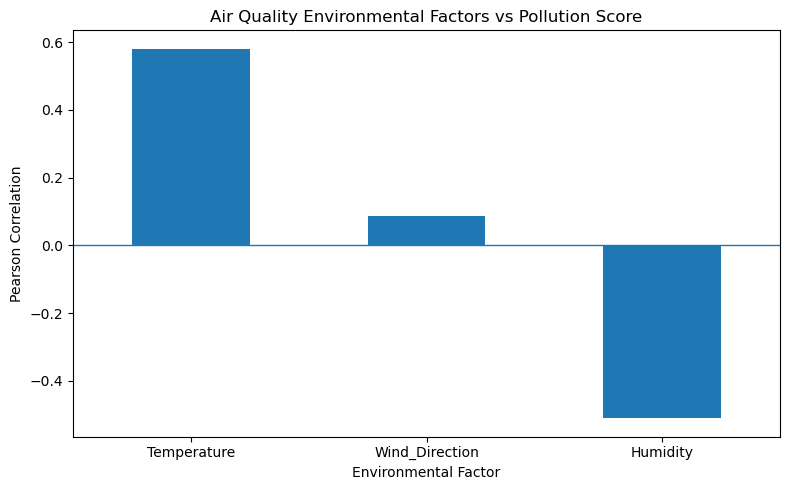

Saved: EDA_Graphs/Cross_Domain\air_weather_pollution_correlation.png


In [123]:
# ============================================================
# STEP 10.2.6 — AIR QUALITY ↔ WEATHER CORRELATION PLOT
# ============================================================

import os
import matplotlib.pyplot as plt

# Create output folder
cross_domain_graphs = "EDA_Graphs/Cross_Domain"
os.makedirs(cross_domain_graphs, exist_ok=True)

# Plot correlations
plt.figure(figsize=(8, 5))

air_weather_correlations.plot(
    kind="bar"
)

plt.axhline(0, linewidth=1)
plt.title("Air Quality Environmental Factors vs Pollution Score")
plt.xlabel("Environmental Factor")
plt.ylabel("Pearson Correlation")
plt.xticks(rotation=0)
plt.tight_layout()

# Save figure
air_weather_corr_path = os.path.join(
    cross_domain_graphs,
    "air_weather_pollution_correlation.png"
)

plt.savefig(
    air_weather_corr_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", air_weather_corr_path)

In [124]:
# ============================================================
# STEP 10.2.7 — POLLUTION UNDER TEMPERATURE CONDITIONS
# ============================================================

air_temperature_analysis = air_c14[
    ["Temperature", air_target_c14]
].copy()

air_temperature_analysis["Temperature_Condition"] = pd.qcut(
    air_temperature_analysis["Temperature"],
    q=4,
    labels=[
        "Low Temperature",
        "Moderate-Low Temperature",
        "Moderate-High Temperature",
        "High Temperature"
    ]
)

temperature_pollution_summary = (
    air_temperature_analysis
    .groupby("Temperature_Condition", observed=True)[air_target_c14]
    .agg(["mean", "min", "max", "count"])
    .reset_index()
)

temperature_pollution_summary.columns = [
    "Temperature Condition",
    "Average Pollution Score",
    "Minimum Pollution Score",
    "Maximum Pollution Score",
    "Observations"
]

print("=" * 70)
print("POLLUTION SCORE UNDER TEMPERATURE CONDITIONS")
print("=" * 70)

display(temperature_pollution_summary)

POLLUTION SCORE UNDER TEMPERATURE CONDITIONS


,Temperature Condition,Average Pollution Score,Minimum Pollution Score,Maximum Pollution Score,Observations
0,Low Temperature,-0.626132,-1.082755,-0.273045,125
1,Moderate-Low Temperature,-0.336873,-0.960318,1.680227,125
2,Moderate-High Temperature,0.283349,-0.954692,1.480154,125
3,High Temperature,0.679656,-0.931701,1.698826,125


In [125]:
# ============================================================
# STEP 10.2.8 — POLLUTION UNDER HUMIDITY CONDITIONS
# ============================================================

air_humidity_analysis = air_c14[
    ["Humidity", air_target_c14]
].copy()

air_humidity_analysis["Humidity_Condition"] = pd.qcut(
    air_humidity_analysis["Humidity"],
    q=4,
    labels=[
        "Low Humidity",
        "Moderate-Low Humidity",
        "Moderate-High Humidity",
        "High Humidity"
    ]
)

humidity_pollution_summary = (
    air_humidity_analysis
    .groupby("Humidity_Condition", observed=True)[air_target_c14]
    .agg(["mean", "min", "max", "count"])
    .reset_index()
)

humidity_pollution_summary.columns = [
    "Humidity Condition",
    "Average Pollution Score",
    "Minimum Pollution Score",
    "Maximum Pollution Score",
    "Observations"
]

print("=" * 70)
print("POLLUTION SCORE UNDER HUMIDITY CONDITIONS")
print("=" * 70)

display(humidity_pollution_summary)

POLLUTION SCORE UNDER HUMIDITY CONDITIONS


,Humidity Condition,Average Pollution Score,Minimum Pollution Score,Maximum Pollution Score,Observations
0,Low Humidity,0.591186,-0.787213,1.698826,125
1,Moderate-Low Humidity,0.005754,-0.943292,1.497300,125
2,Moderate-High Humidity,-0.049144,-1.082755,1.461632,125
3,High Humidity,-0.547796,-1.047655,1.287967,125


In [126]:
# ============================================================
# STEP 10.2.9 — SAVE AIR ↔ WEATHER ANALYSIS RESULTS
# ============================================================

import os

cross_domain_tables = "Feature_engineered_datasets/Cross_Domain_Fusion/Tables"
os.makedirs(cross_domain_tables, exist_ok=True)

# Save temperature analysis
temperature_path = os.path.join(
    cross_domain_tables,
    "air_temperature_pollution_analysis.xlsx"
)

temperature_pollution_summary.to_excel(
    temperature_path,
    index=False
)

# Save humidity analysis
humidity_path = os.path.join(
    cross_domain_tables,
    "air_humidity_pollution_analysis.xlsx"
)

humidity_pollution_summary.to_excel(
    humidity_path,
    index=False
)

# Save correlation results
correlation_path = os.path.join(
    cross_domain_tables,
    "air_weather_pollution_correlations.xlsx"
)

air_weather_correlations.to_frame(
    name="Correlation with Pollution Score"
).to_excel(
    correlation_path
)

print("=" * 70)
print("AIR ↔ WEATHER RESULTS SAVED")
print("=" * 70)

print("Temperature analysis:")
print(temperature_path)

print("\nHumidity analysis:")
print(humidity_path)

print("\nCorrelation analysis:")
print(correlation_path)

AIR ↔ WEATHER RESULTS SAVED
Temperature analysis:
Feature_engineered_datasets/Cross_Domain_Fusion/Tables\air_temperature_pollution_analysis.xlsx

Humidity analysis:
Feature_engineered_datasets/Cross_Domain_Fusion/Tables\air_humidity_pollution_analysis.xlsx

Correlation analysis:
Feature_engineered_datasets/Cross_Domain_Fusion/Tables\air_weather_pollution_correlations.xlsx


In [127]:
# ============================================================
# STEP 10.3.1 — THREE-DOMAIN SUMMARY
# Air Quality + Weather + Energy
# ============================================================

print("=" * 70)
print("THREE-DOMAIN CROSS-DOMAIN SUMMARY")
print("=" * 70)

# ------------------------------------------------------------
# AIR QUALITY SUMMARY
# ------------------------------------------------------------

air_summary = {
    "Domain": "Air Quality",
    "Observations": len(air_c14),
    "Target": air_target_c14,
    "Target_Mean": air_c14[air_target_c14].mean(),
    "Target_Min": air_c14[air_target_c14].min(),
    "Target_Max": air_c14[air_target_c14].max(),
    "Temperature_Mean": air_c14["Temperature"].mean(),
    "Humidity_Mean": air_c14["Humidity"].mean()
}


# ------------------------------------------------------------
# WEATHER SUMMARY
# ------------------------------------------------------------

weather_summary = {
    "Domain": "Weather",
    "Observations": len(weather_c14),
    "Target": weather_target_c14,
    "Target_Mean": weather_c14[weather_target_c14].mean(),
    "Target_Min": weather_c14[weather_target_c14].min(),
    "Target_Max": weather_c14[weather_target_c14].max(),
    "Temperature_Mean": weather_c14["Temperature (C)"].mean(),
    "Humidity_Mean": weather_c14["Humidity"].mean()
}


# ------------------------------------------------------------
# ENERGY SUMMARY
# ------------------------------------------------------------

energy_summary = {
    "Domain": "Energy",
    "Observations": len(energy_c14),
    "Target": energy_target_c14,
    "Target_Mean": energy_c14[energy_target_c14].mean(),
    "Target_Min": energy_c14[energy_target_c14].min(),
    "Target_Max": energy_c14[energy_target_c14].max(),
    "Temperature_Mean": None,
    "Humidity_Mean": None
}


# ------------------------------------------------------------
# CREATE SUMMARY DATAFRAME
# ------------------------------------------------------------

three_domain_summary = pd.DataFrame([
    air_summary,
    weather_summary,
    energy_summary
])

display(three_domain_summary)

THREE-DOMAIN CROSS-DOMAIN SUMMARY


,Domain,Observations,Target,Target_Mean,Target_Min,Target_Max,Temperature_Mean,Humidity_Mean
0,Air Quality,500,Pollution_Score,-3.623768e-16,-1.082755,1.698826,30.448413,56.196914
1,Weather,96429,Temperature (C),1.192969e+01,-21.822222,39.905556,11.929692,0.734902
2,Energy,1000,EnergyConsumption,7.705587e+01,53.263278,99.201120,NaN,NaN


In [128]:
# ============================================================
# STEP 10.3.2 — KEY THREE-DOMAIN RELATIONSHIPS
# ============================================================

# ------------------------------------------------------------
# 1. WEATHER → ENERGY CORRELATIONS
# ------------------------------------------------------------

weather_energy_key = weather_energy_cross[
    [
        "Apparent Temperature (C)",
        "Humidity",
        "Wind Speed (km/h)",
        "Visibility (km)",
        "Pressure (millibars)",
        energy_target_c14
    ]
].corr()[energy_target_c14].drop(energy_target_c14)


# ------------------------------------------------------------
# 2. AIR ENVIRONMENT → POLLUTION CORRELATIONS
# ------------------------------------------------------------

air_pollution_key = air_c14[
    [
        "Temperature",
        "Humidity",
        "Wind_Direction",
        air_target_c14
    ]
].corr()[air_target_c14].drop(air_target_c14)


# ------------------------------------------------------------
# 3. CREATE COMBINED RELATIONSHIP TABLE
# ------------------------------------------------------------

three_domain_relationships = pd.DataFrame({
    "Relationship": [
        "Weather Temperature → Energy",
        "Weather Humidity → Energy",
        "Weather Wind Speed → Energy",
        "Weather Visibility → Energy",
        "Weather Pressure → Energy",
        "Air Temperature → Pollution",
        "Air Humidity → Pollution",
        "Air Wind Direction → Pollution"
    ],
    "Correlation": [
        weather_energy_key["Apparent Temperature (C)"],
        weather_energy_key["Humidity"],
        weather_energy_key["Wind Speed (km/h)"],
        weather_energy_key["Visibility (km)"],
        weather_energy_key["Pressure (millibars)"],
        air_pollution_key["Temperature"],
        air_pollution_key["Humidity"],
        air_pollution_key["Wind_Direction"]
    ],
    "Domain": [
        "Weather → Energy",
        "Weather → Energy",
        "Weather → Energy",
        "Weather → Energy",
        "Weather → Energy",
        "Air Quality → Pollution",
        "Air Quality → Pollution",
        "Air Quality → Pollution"
    ]
})

print("=" * 70)
print("KEY THREE-DOMAIN RELATIONSHIPS")
print("=" * 70)

display(three_domain_relationships)

KEY THREE-DOMAIN RELATIONSHIPS


,Relationship,Correlation,Domain
0,Weather Temperature → Energy,-0.008803,Weather → Energy
1,Weather Humidity → Energy,0.012725,Weather → Energy
2,Weather Wind Speed → Energy,-0.019137,Weather → Energy
3,Weather Visibility → Energy,0.050982,Weather → Energy
4,Weather Pressure → Energy,-0.229204,Weather → Energy
5,Air Temperature → Pollution,0.580712,Air Quality → Pollution
6,Air Humidity → Pollution,-0.510253,Air Quality → Pollution
7,Air Wind Direction → Pollution,0.085582,Air Quality → Pollution


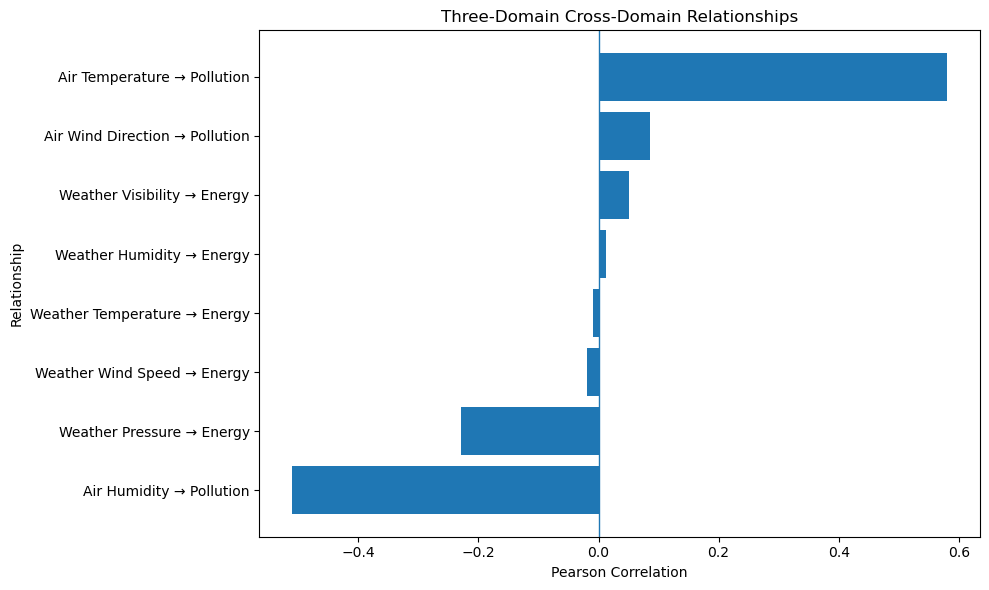

Saved: EDA_Graphs/Cross_Domain\three_domain_relationships.png


In [129]:
# ============================================================
# STEP 10.3.3 — THREE-DOMAIN RELATIONSHIP VISUALIZATION
# ============================================================

import os
import matplotlib.pyplot as plt

# Output folder
cross_domain_graphs = "EDA_Graphs/Cross_Domain"
os.makedirs(cross_domain_graphs, exist_ok=True)

# Prepare data
plot_data = three_domain_relationships.copy()

# Sort by correlation for easier interpretation
plot_data = plot_data.sort_values(
    "Correlation",
    ascending=True
)

# Create plot
plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["Relationship"],
    plot_data["Correlation"]
)

plt.axvline(
    0,
    linewidth=1
)

plt.title(
    "Three-Domain Cross-Domain Relationships"
)

plt.xlabel(
    "Pearson Correlation"
)

plt.ylabel(
    "Relationship"
)

plt.tight_layout()

# Save
three_domain_relationship_path = os.path.join(
    cross_domain_graphs,
    "three_domain_relationships.png"
)

plt.savefig(
    three_domain_relationship_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", three_domain_relationship_path)

In [130]:
# ============================================================
# STEP 10.3.4 — SMART-CITY INSIGHT TABLE
# ============================================================

smart_city_insights = pd.DataFrame([
    {
        "Domain Relationship": "Temperature → Pollution",
        "Finding": "Positive association",
        "Correlation": 0.580712,
        "Smart-City Insight":
            "Higher temperature conditions are associated with higher pollution scores.",
        "Potential Action":
            "Prioritize air-quality monitoring during warmer conditions.",
        "Evidence Type":
            "Air Quality contextual analysis"
    },
    {
        "Domain Relationship": "Humidity → Pollution",
        "Finding": "Negative association",
        "Correlation": -0.510253,
        "Smart-City Insight":
            "Higher humidity conditions are associated with lower pollution scores.",
        "Potential Action":
            "Include humidity conditions when interpreting pollution-risk patterns.",
        "Evidence Type":
            "Air Quality contextual analysis"
    },
    {
        "Domain Relationship": "Temperature → Energy",
        "Finding": "Very weak association",
        "Correlation":
            weather_energy_key["Apparent Temperature (C)"],
        "Smart-City Insight":
            "Weather temperature alone shows limited association with aggregated energy consumption.",
        "Potential Action":
            "Avoid relying on temperature alone for energy-demand planning.",
        "Evidence Type":
            "Weather-Energy aligned analysis"
    },
    {
        "Domain Relationship": "Pressure → Energy",
        "Finding": "Strongest weather-energy association",
        "Correlation":
            weather_energy_key["Pressure (millibars)"],
        "Smart-City Insight":
            "Pressure showed the strongest individual weather association with aggregated energy consumption, although the relationship remains weak.",
        "Potential Action":
            "Consider pressure alongside other variables rather than using it independently.",
        "Evidence Type":
            "Weather-Energy aligned analysis"
    },
    {
        "Domain Relationship": "Weather Variables → Energy",
        "Finding": "Low explanatory power",
        "Correlation": 0.0804,
        "Smart-City Insight":
            "The combined weather regression explained only about 8.04% of energy variation.",
        "Potential Action":
            "Use broader operational and consumption-related variables for energy planning.",
        "Evidence Type":
            "Weather-Energy regression"
    }
])

print("=" * 70)
print("SMART-CITY INSIGHTS")
print("=" * 70)

display(smart_city_insights)

SMART-CITY INSIGHTS


,Domain Relationship,Finding,Correlation,Smart-City Insight,Potential Action,Evidence Type
0,Temperature → Pollution,Positive association,0.580712,Higher temperature conditions are associated w...,Prioritize air-quality monitoring during warme...,Air Quality contextual analysis
1,Humidity → Pollution,Negative association,-0.510253,Higher humidity conditions are associated with...,Include humidity conditions when interpreting ...,Air Quality contextual analysis
2,Temperature → Energy,Very weak association,-0.008803,Weather temperature alone shows limited associ...,Avoid relying on temperature alone for energy-...,Weather-Energy aligned analysis
3,Pressure → Energy,Strongest weather-energy association,-0.229204,Pressure showed the strongest individual weath...,Consider pressure alongside other variables ra...,Weather-Energy aligned analysis
4,Weather Variables → Energy,Low explanatory power,0.080400,The combined weather regression explained only...,Use broader operational and consumption-relate...,Weather-Energy regression


In [131]:
# ============================================================
# STEP 10.3.5 — SAVE SMART-CITY INSIGHTS
# ============================================================

import os

cross_domain_tables = "Feature_engineered_datasets/Cross_Domain_Fusion/Tables"
os.makedirs(cross_domain_tables, exist_ok=True)

smart_city_insights_path = os.path.join(
    cross_domain_tables,
    "smart_city_insights.xlsx"
)

smart_city_insights.to_excel(
    smart_city_insights_path,
    index=False
)

print("=" * 70)
print("SMART-CITY INSIGHTS SAVED")
print("=" * 70)

print("Saved:", smart_city_insights_path)

SMART-CITY INSIGHTS SAVED
Saved: Feature_engineered_datasets/Cross_Domain_Fusion/Tables\smart_city_insights.xlsx


In [132]:
# ============================================================
# STEP 10.4.1 — SMART-CITY POLLUTION RISK SCENARIOS
# ============================================================

air_scenario = air_c14[
    ["Temperature", "Humidity", air_target_c14]
].copy()

# ------------------------------------------------------------
# Temperature groups
# ------------------------------------------------------------

temperature_median = air_scenario["Temperature"].median()

air_scenario["Temperature_Level"] = np.where(
    air_scenario["Temperature"] >= temperature_median,
    "High Temperature",
    "Low Temperature"
)

# ------------------------------------------------------------
# Humidity groups
# ------------------------------------------------------------

humidity_median = air_scenario["Humidity"].median()

air_scenario["Humidity_Level"] = np.where(
    air_scenario["Humidity"] >= humidity_median,
    "High Humidity",
    "Low Humidity"
)

# ------------------------------------------------------------
# Combined scenario
# ------------------------------------------------------------

air_scenario["Scenario"] = (
    air_scenario["Temperature_Level"]
    + " + "
    + air_scenario["Humidity_Level"]
)

# ------------------------------------------------------------
# Aggregate pollution score
# ------------------------------------------------------------

pollution_scenario_summary = (
    air_scenario
    .groupby("Scenario")[air_target_c14]
    .agg(["mean", "min", "max", "count"])
    .reset_index()
)

pollution_scenario_summary.columns = [
    "Scenario",
    "Average Pollution Score",
    "Minimum Pollution Score",
    "Maximum Pollution Score",
    "Observations"
]

# Sort by average pollution
pollution_scenario_summary = pollution_scenario_summary.sort_values(
    "Average Pollution Score",
    ascending=False
)

print("=" * 70)
print("SMART-CITY POLLUTION RISK SCENARIOS")
print("=" * 70)

display(pollution_scenario_summary)

SMART-CITY POLLUTION RISK SCENARIOS


,Scenario,Average Pollution Score,Minimum Pollution Score,Maximum Pollution Score,Observations
1,High Temperature + Low Humidity,0.647917,-0.822132,1.698826,161
0,High Temperature + High Humidity,0.180461,-0.954692,1.461632,89
3,Low Temperature + Low Humidity,-0.333676,-0.943292,1.680227,89
2,Low Temperature + High Humidity,-0.563220,-1.082755,1.348742,161


In [133]:
# ============================================================
# STEP 10.4.1 — SMART-CITY POLLUTION RISK SCENARIOS
# ============================================================

air_scenario = air_c14[
    ["Temperature", "Humidity", air_target_c14]
].copy()

# ------------------------------------------------------------
# Temperature groups
# ------------------------------------------------------------

temperature_median = air_scenario["Temperature"].median()

air_scenario["Temperature_Level"] = np.where(
    air_scenario["Temperature"] >= temperature_median,
    "High Temperature",
    "Low Temperature"
)

# ------------------------------------------------------------
# Humidity groups
# ------------------------------------------------------------

humidity_median = air_scenario["Humidity"].median()

air_scenario["Humidity_Level"] = np.where(
    air_scenario["Humidity"] >= humidity_median,
    "High Humidity",
    "Low Humidity"
)

# ------------------------------------------------------------
# Combined scenario
# ------------------------------------------------------------

air_scenario["Scenario"] = (
    air_scenario["Temperature_Level"]
    + " + "
    + air_scenario["Humidity_Level"]
)

# ------------------------------------------------------------
# Aggregate pollution score
# ------------------------------------------------------------

pollution_scenario_summary = (
    air_scenario
    .groupby("Scenario")[air_target_c14]
    .agg(["mean", "min", "max", "count"])
    .reset_index()
)

pollution_scenario_summary.columns = [
    "Scenario",
    "Average Pollution Score",
    "Minimum Pollution Score",
    "Maximum Pollution Score",
    "Observations"
]

# Sort by average pollution
pollution_scenario_summary = pollution_scenario_summary.sort_values(
    "Average Pollution Score",
    ascending=False
)

print("=" * 70)
print("SMART-CITY POLLUTION RISK SCENARIOS")
print("=" * 70)

display(pollution_scenario_summary)

SMART-CITY POLLUTION RISK SCENARIOS


,Scenario,Average Pollution Score,Minimum Pollution Score,Maximum Pollution Score,Observations
1,High Temperature + Low Humidity,0.647917,-0.822132,1.698826,161
0,High Temperature + High Humidity,0.180461,-0.954692,1.461632,89
3,Low Temperature + Low Humidity,-0.333676,-0.943292,1.680227,89
2,Low Temperature + High Humidity,-0.563220,-1.082755,1.348742,161


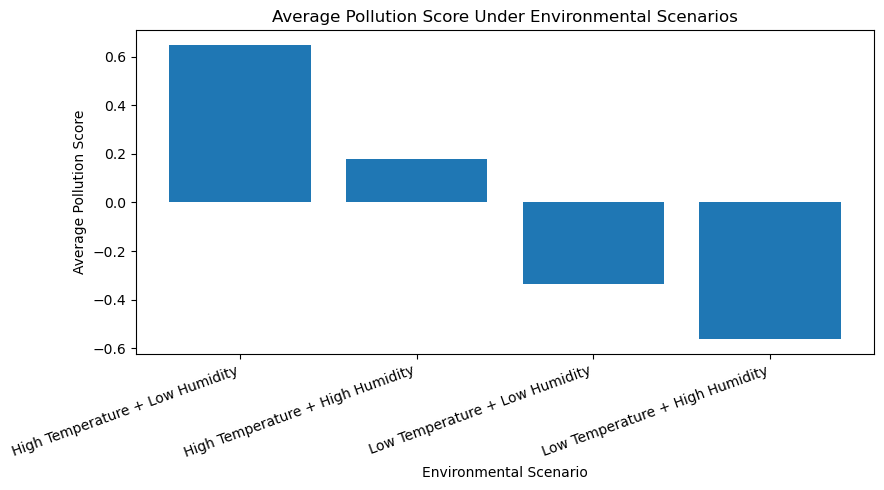

Saved: EDA_Graphs/Cross_Domain\pollution_scenario_analysis.png


In [134]:
# ============================================================
# STEP 10.4.2 — POLLUTION SCENARIO VISUALIZATION
# ============================================================

import os
import matplotlib.pyplot as plt

cross_domain_graphs = "EDA_Graphs/Cross_Domain"
os.makedirs(cross_domain_graphs, exist_ok=True)

# Sort scenarios by average pollution
plot_data = pollution_scenario_summary.sort_values(
    "Average Pollution Score",
    ascending=False
)

plt.figure(figsize=(9, 5))

plt.bar(
    plot_data["Scenario"],
    plot_data["Average Pollution Score"]
)

plt.title(
    "Average Pollution Score Under Environmental Scenarios"
)

plt.xlabel(
    "Environmental Scenario"
)

plt.ylabel(
    "Average Pollution Score"
)

plt.xticks(
    rotation=20,
    ha="right"
)

plt.tight_layout()

# Save figure
pollution_scenario_path = os.path.join(
    cross_domain_graphs,
    "pollution_scenario_analysis.png"
)

plt.savefig(
    pollution_scenario_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", pollution_scenario_path)

In [135]:
# ============================================================
# STEP 10.4.3 — SMART-CITY ENERGY SCENARIOS
# ============================================================

energy_scenario = weather_energy_cross[
    [
        "Apparent Temperature (C)",
        "Humidity",
        energy_target_c14
    ]
].copy()

# ------------------------------------------------------------
# Temperature groups
# ------------------------------------------------------------

temperature_median_energy = (
    energy_scenario["Apparent Temperature (C)"].median()
)

energy_scenario["Temperature_Level"] = np.where(
    energy_scenario["Apparent Temperature (C)"] >= temperature_median_energy,
    "High Temperature",
    "Low Temperature"
)

# ------------------------------------------------------------
# Humidity groups
# ------------------------------------------------------------

humidity_median_energy = energy_scenario["Humidity"].median()

energy_scenario["Humidity_Level"] = np.where(
    energy_scenario["Humidity"] >= humidity_median_energy,
    "High Humidity",
    "Low Humidity"
)

# ------------------------------------------------------------
# Combined scenario
# ------------------------------------------------------------

energy_scenario["Scenario"] = (
    energy_scenario["Temperature_Level"]
    + " + "
    + energy_scenario["Humidity_Level"]
)

# ------------------------------------------------------------
# Aggregate energy consumption
# ------------------------------------------------------------

energy_scenario_summary = (
    energy_scenario
    .groupby("Scenario")[energy_target_c14]
    .agg(["mean", "min", "max", "count"])
    .reset_index()
)

energy_scenario_summary.columns = [
    "Scenario",
    "Average Energy",
    "Minimum Energy",
    "Maximum Energy",
    "Observations"
]

# Sort by average energy
energy_scenario_summary = energy_scenario_summary.sort_values(
    "Average Energy",
    ascending=False
)

print("=" * 70)
print("SMART-CITY ENERGY SCENARIOS")
print("=" * 70)

display(energy_scenario_summary)

SMART-CITY ENERGY SCENARIOS


,Scenario,Average Energy,Minimum Energy,Maximum Energy,Observations
0,High Temperature + High Humidity,80.333769,80.333769,80.333769,1
1,High Temperature + Low Humidity,77.140110,73.498772,81.268578,23
2,Low Temperature + High Humidity,77.091446,73.422548,81.470548,23
3,Low Temperature + Low Humidity,76.050560,76.050560,76.050560,1


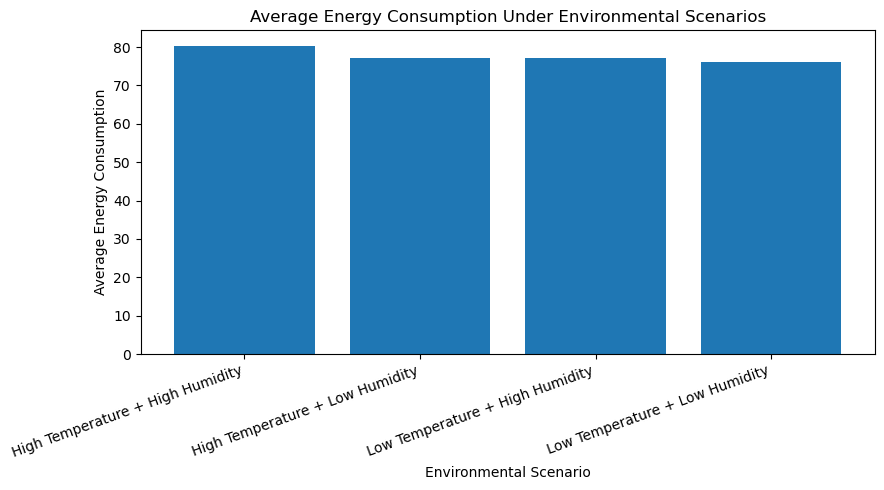

Saved: EDA_Graphs/Cross_Domain\energy_scenario_analysis.png


In [136]:
# ============================================================
# STEP 10.4.4 — ENERGY SCENARIO VISUALIZATION
# ============================================================

import os
import matplotlib.pyplot as plt

cross_domain_graphs = "EDA_Graphs/Cross_Domain"
os.makedirs(cross_domain_graphs, exist_ok=True)

# Sort scenarios by average energy
plot_data = energy_scenario_summary.sort_values(
    "Average Energy",
    ascending=False
)

plt.figure(figsize=(9, 5))

plt.bar(
    plot_data["Scenario"],
    plot_data["Average Energy"]
)

plt.title(
    "Average Energy Consumption Under Environmental Scenarios"
)

plt.xlabel(
    "Environmental Scenario"
)

plt.ylabel(
    "Average Energy Consumption"
)

plt.xticks(
    rotation=20,
    ha="right"
)

plt.tight_layout()

# Save figure
energy_scenario_path = os.path.join(
    cross_domain_graphs,
    "energy_scenario_analysis.png"
)

plt.savefig(
    energy_scenario_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", energy_scenario_path)

In [137]:
# ============================================================
# STEP 10.4.5 — SAVE SCENARIO ANALYSIS TABLES
# ============================================================

import os

cross_domain_tables = "Feature_engineered_datasets/Cross_Domain_Fusion/Tables"
os.makedirs(cross_domain_tables, exist_ok=True)

# Save Pollution Scenario Analysis
pollution_scenario_path = os.path.join(
    cross_domain_tables,
    "pollution_scenario_analysis.xlsx"
)

pollution_scenario_summary.to_excel(
    pollution_scenario_path,
    index=False
)

# Save Energy Scenario Analysis
energy_scenario_path = os.path.join(
    cross_domain_tables,
    "energy_scenario_analysis.xlsx"
)

energy_scenario_summary.to_excel(
    energy_scenario_path,
    index=False
)

print("Saved:", pollution_scenario_path)
print("Saved:", energy_scenario_path)

Saved: Feature_engineered_datasets/Cross_Domain_Fusion/Tables\pollution_scenario_analysis.xlsx
Saved: Feature_engineered_datasets/Cross_Domain_Fusion/Tables\energy_scenario_analysis.xlsx


In [138]:
# ============================================================
# STEP 10.4.6 — SMART-CITY RISK & ACTION TABLE
# ============================================================

import os
import pandas as pd

cross_domain_tables = "Feature_engineered_datasets/Cross_Domain_Fusion/Tables"
os.makedirs(cross_domain_tables, exist_ok=True)

# ------------------------------------------------------------
# 1. Get highest-pollution scenario
# ------------------------------------------------------------

highest_pollution = pollution_scenario_summary.iloc[0]

# ------------------------------------------------------------
# 2. Get highest-energy scenario
# ------------------------------------------------------------

highest_energy = energy_scenario_summary.iloc[0]

# ------------------------------------------------------------
# 3. Create final Smart-City Risk & Action table
# ------------------------------------------------------------

smart_city_scenario_actions = pd.DataFrame({
    "Scenario Type": [
        "Pollution Risk",
        "Energy Demand"
    ],

    "Highest-Risk Scenario": [
        highest_pollution["Scenario"],
        highest_energy["Scenario"]
    ],

    "Average Target Value": [
        highest_pollution["Average Pollution Score"],
        highest_energy["Average Energy"]
    ],

    "Minimum Target Value": [
        highest_pollution["Minimum Pollution Score"],
        highest_energy["Minimum Energy"]
    ],

    "Maximum Target Value": [
        highest_pollution["Maximum Pollution Score"],
        highest_energy["Maximum Energy"]
    ],

    "Observations": [
        highest_pollution["Observations"],
        highest_energy["Observations"]
    ],

    "Smart-City Recommendation": [
        "Prioritize air-quality monitoring and preventive measures under this environmental condition.",
        "Consider demand-management and energy-efficiency measures under this environmental condition."
    ]
})

# ------------------------------------------------------------
# 4. Save table
# ------------------------------------------------------------

smart_city_scenario_path = os.path.join(
    cross_domain_tables,
    "smart_city_scenario_actions.xlsx"
)

smart_city_scenario_actions.to_excel(
    smart_city_scenario_path,
    index=False
)

# ------------------------------------------------------------
# 5. Display result
# ------------------------------------------------------------

display(smart_city_scenario_actions)

print("\nSaved:", smart_city_scenario_path)

,Scenario Type,Highest-Risk Scenario,Average Target Value,Minimum Target Value,Maximum Target Value,Observations,Smart-City Recommendation
0,Pollution Risk,High Temperature + Low Humidity,0.647917,-0.822132,1.698826,161,Prioritize air-quality monitoring and preventi...
1,Energy Demand,High Temperature + High Humidity,80.333769,80.333769,80.333769,1,Consider demand-management and energy-efficien...



Saved: Feature_engineered_datasets/Cross_Domain_Fusion/Tables\smart_city_scenario_actions.xlsx


In [139]:
# ============================================================
# STEP 10.4.7 — FINAL CROSS-DOMAIN SUMMARY
# ============================================================

import os
import pandas as pd

cross_domain_tables = "Feature_engineered_datasets/Cross_Domain_Fusion/Tables"
os.makedirs(cross_domain_tables, exist_ok=True)

# ------------------------------------------------------------
# Create final cross-domain findings table
# ------------------------------------------------------------

final_cross_domain_summary = pd.DataFrame({
    "Analysis": [
        "Temperature → Pollution",
        "Humidity → Pollution",
        "Temperature → Energy",
        "Pressure → Energy",
        "Weather Variables → Energy"
    ],

    "Finding": [
        "Positive association",
        "Negative association",
        "Very weak association",
        "Strongest weather-energy association",
        "Low explanatory power"
    ],

    "Correlation_or_R2": [
        air_pollution_key["Temperature"],
        air_pollution_key["Humidity"],
        weather_energy_key["Apparent Temperature (C)"],
        weather_energy_key["Pressure (millibars)"],
        0.0804
    ],

    "Interpretation": [
        "Higher temperature conditions are associated with higher pollution scores.",
        "Higher humidity conditions are associated with lower pollution scores.",
        "Weather temperature alone has limited association with aggregated energy consumption.",
        "Pressure has the strongest individual weather association with aggregated energy consumption, although the relationship remains weak.",
        "Combined weather variables explain only about 8.04% of energy variation."
    ],

    "Smart_City_Action": [
        "Prioritize air-quality monitoring during warmer conditions.",
        "Include humidity conditions when interpreting pollution-risk patterns.",
        "Avoid relying on temperature alone for energy-demand planning.",
        "Consider pressure together with other variables rather than independently.",
        "Use broader operational and consumption-related variables for energy planning."
    ]
})

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

final_cross_domain_path = os.path.join(
    cross_domain_tables,
    "final_cross_domain_summary.xlsx"
)

final_cross_domain_summary.to_excel(
    final_cross_domain_path,
    index=False
)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

display(final_cross_domain_summary)

print("\nSaved:", final_cross_domain_path)

,Analysis,Finding,Correlation_or_R2,Interpretation,Smart_City_Action
0,Temperature → Pollution,Positive association,0.580712,Higher temperature conditions are associated w...,Prioritize air-quality monitoring during warme...
1,Humidity → Pollution,Negative association,-0.510253,Higher humidity conditions are associated with...,Include humidity conditions when interpreting ...
2,Temperature → Energy,Very weak association,-0.008803,Weather temperature alone has limited associat...,Avoid relying on temperature alone for energy-...
3,Pressure → Energy,Strongest weather-energy association,-0.229204,Pressure has the strongest individual weather ...,Consider pressure together with other variable...
4,Weather Variables → Energy,Low explanatory power,0.080400,Combined weather variables explain only about ...,Use broader operational and consumption-relate...



Saved: Feature_engineered_datasets/Cross_Domain_Fusion/Tables\final_cross_domain_summary.xlsx


In [140]:
print("===== AIR QUALITY =====")
print("Final Models:")
for name in [
    "lr_final_air",
    "cb_final_air",
    "gb_final_air",
    "meta_lr_air"
]:
    print(name, "->", type(globals().get(name)))

print("\nPreprocessor:")
print("preprocessor_air_hybrid ->", type(globals().get("preprocessor_air_hybrid")))


print("\n===== WEATHER =====")
print("Final Models:")
for name in [
    "lr_final_weather",
    "cb_final_weather",
    "gb_final_weather",
    "meta_lr_weather"
]:
    print(name, "->", type(globals().get(name)))

print("\nPreprocessor:")
print("preprocessor_weather_hybrid ->", type(globals().get("preprocessor_weather_hybrid")))


print("\n===== ENERGY =====")
print("Final Models:")
for name in [
    "lr_final_lrcbgb_c14",
    "cb_final_lrcbgb_c14",
    "gb_final_lrcbgb_c14",
    "meta_lr_lrcbgb_c14"
]:
    print(name, "->", type(globals().get(name)))

print("\nFeature information:")
print("X_train_energy_encoded_c14 shape:",
      X_train_energy_encoded_c14.shape)

print("X_test_energy_encoded_c14 shape:",
      X_test_energy_encoded_c14.shape)

===== AIR QUALITY =====
Final Models:
lr_final_air -> <class 'sklearn.linear_model._base.LinearRegression'>
cb_final_air -> <class 'catboost.core.CatBoostRegressor'>
gb_final_air -> <class 'sklearn.ensemble._gb.GradientBoostingRegressor'>
meta_lr_air -> <class 'sklearn.linear_model._base.LinearRegression'>

Preprocessor:
preprocessor_air_hybrid -> <class 'sklearn.compose._column_transformer.ColumnTransformer'>

===== WEATHER =====
Final Models:
lr_final_weather -> <class 'sklearn.linear_model._base.LinearRegression'>
cb_final_weather -> <class 'catboost.core.CatBoostRegressor'>
gb_final_weather -> <class 'sklearn.ensemble._gb.GradientBoostingRegressor'>
meta_lr_weather -> <class 'sklearn.linear_model._base.LinearRegression'>

Preprocessor:
preprocessor_weather_hybrid -> <class 'sklearn.compose._column_transformer.ColumnTransformer'>

===== ENERGY =====
Final Models:
lr_final_lrcbgb_c14 -> <class 'sklearn.linear_model._base.LinearRegression'>
cb_final_lrcbgb_c14 -> <class 'catboost.core

In [141]:
import os
import joblib

# ============================================================
# DASHBOARD ARTIFACT DIRECTORIES
# ============================================================

base_dir = "Dashboard_Artifacts"

folders = [
    f"{base_dir}/models/air",
    f"{base_dir}/models/weather",
    f"{base_dir}/models/energy",
    f"{base_dir}/preprocessors/air",
    f"{base_dir}/preprocessors/weather"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)


# ============================================================
# AIR QUALITY — FINAL PROPOSED HYBRID
# ============================================================

joblib.dump(
    lr_final_air,
    f"{base_dir}/models/air/lr_final_air.joblib"
)

joblib.dump(
    cb_final_air,
    f"{base_dir}/models/air/cb_final_air.joblib"
)

joblib.dump(
    gb_final_air,
    f"{base_dir}/models/air/gb_final_air.joblib"
)

joblib.dump(
    meta_lr_air,
    f"{base_dir}/models/air/meta_lr_air.joblib"
)

joblib.dump(
    preprocessor_air_hybrid,
    f"{base_dir}/preprocessors/air/preprocessor_air_hybrid.joblib"
)


# ============================================================
# WEATHER — FINAL PROPOSED HYBRID
# ============================================================

joblib.dump(
    lr_final_weather,
    f"{base_dir}/models/weather/lr_final_weather.joblib"
)

joblib.dump(
    cb_final_weather,
    f"{base_dir}/models/weather/cb_final_weather.joblib"
)

joblib.dump(
    gb_final_weather,
    f"{base_dir}/models/weather/gb_final_weather.joblib"
)

joblib.dump(
    meta_lr_weather,
    f"{base_dir}/models/weather/meta_lr_weather.joblib"
)

joblib.dump(
    preprocessor_weather_hybrid,
    f"{base_dir}/preprocessors/weather/preprocessor_weather_hybrid.joblib"
)


# ============================================================
# ENERGY — FINAL PROPOSED HYBRID
# ============================================================

joblib.dump(
    lr_final_lrcbgb_c14,
    f"{base_dir}/models/energy/lr_final_lrcbgb_c14.joblib"
)

joblib.dump(
    cb_final_lrcbgb_c14,
    f"{base_dir}/models/energy/cb_final_lrcbgb_c14.joblib"
)

joblib.dump(
    gb_final_lrcbgb_c14,
    f"{base_dir}/models/energy/gb_final_lrcbgb_c14.joblib"
)

joblib.dump(
    meta_lr_lrcbgb_c14,
    f"{base_dir}/models/energy/meta_lr_lrcbgb_c14.joblib"
)


print("✅ All final hybrid model artifacts saved successfully!")
print()
print("📁 Location:", os.path.abspath(base_dir))

✅ All final hybrid model artifacts saved successfully!

📁 Location: C:\Users\umash\OneDrive\Desktop\shankar\DAV\Project_Implementation\Hybrid_Model\Hybrid_Experiments\Dashboard_Artifacts


In [143]:
# ============================================================
# STEP 3A — INSPECT ENERGY PREPROCESSING
# ============================================================

print("=" * 70)
print("ENERGY ENCODED DATA")
print("=" * 70)

print("Type:", type(X_train_energy_encoded_c14))
print("Shape:", X_train_energy_encoded_c14.shape)

print("\nFirst 5 rows:")
print(X_train_energy_encoded_c14[:5])


print("\n" + "=" * 70)
print("SEARCHING FOR ENERGY PREPROCESSING OBJECTS")
print("=" * 70)

keywords = [
    "preprocess",
    "transform",
    "encoder",
    "scaler",
    "onehot",
    "ordinal",
    "column",
    "energy"
]

for name in sorted(globals()):
    name_lower = name.lower()

    if any(keyword in name_lower for keyword in keywords):
        obj = globals()[name]

        if "energy" in name_lower or any(
            keyword in name_lower
            for keyword in ["preprocess", "encoder", "scaler", "onehot"]
        ):
            if hasattr(obj, "shape"):
                print(f"{name} -> {type(obj).__name__}, shape={obj.shape}")
            else:
                print(f"{name} -> {type(obj).__name__}")


print("\n" + "=" * 70)
print("RECENT ENERGY MODEL VARIABLES")
print("=" * 70)

for name in sorted(globals()):
    name_lower = name.lower()

    if "energy" in name_lower:
        obj = globals()[name]

        if hasattr(obj, "shape"):
            print(f"{name} -> {type(obj).__name__}, shape={obj.shape}")
        else:
            print(f"{name} -> {type(obj).__name__}")

ENERGY ENCODED DATA
Type: <class 'numpy.ndarray'>
Shape: (800, 19)

First 5 rows:
[[0.00000000e+00 1.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 1.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 2.32206299e+01 4.60738794e+01
  1.64951035e+03 2.00000000e+00 1.82705282e+01 5.00000000e+00
  1.00000000e+00 0.00000000e+00 1.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  1.00000000e+00 0.00000000e+00 2.20397772e+01 3.34608652e+01
  1.99113166e+03 7.00000000e+00 4.57097015e+00 7.00000000e+00
  1.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 2.61181156e+01 4.30225619e+01
  1.57698068e+03 2.00000000e+00 5.33545801e+00 2.30000000e+01
  1.00000000e+00 0.00000000e+00 0.00000000e+00]
 [1.00000000e+00 1.00000000e+0

In [144]:
# ============================================================
# STEP 4 — VERIFY ENERGY PREPROCESSING AND MODEL COMPARISON
# ============================================================

print("=" * 70)
print("ENERGY ORIGINAL FEATURES")
print("=" * 70)

print("energy_features_c14:")
print(energy_features_c14)

print("\nenergy_model_features:")
print(energy_model_features)

print("\nenergy_categorical_c14:")
print(energy_categorical_c14)

print("\nenergy_numerical_c14:")
print(energy_numerical_c14)


print("\n" + "=" * 70)
print("ENERGY PREPROCESSOR")
print("=" * 70)

print(energy_preprocessor_c14)

print("\nTransformer details:")
for name, transformer, columns in energy_preprocessor_c14.transformers_:
    print("\nTransformer:", name)
    print("Type:", type(transformer).__name__)
    print("Columns:", columns)


print("\n" + "=" * 70)
print("ENERGY FEATURE NAMES AFTER PREPROCESSING")
print("=" * 70)

print("Type:", type(energy_feature_names_c14))
print("Shape:", energy_feature_names_c14.shape)
print("Names:")
print(list(energy_feature_names_c14))


print("\n" + "=" * 70)
print("ENERGY MODEL COMPARISON")
print("=" * 70)

print("Shape:", energy_model_comparison_c14.shape)
print(energy_model_comparison_c14.to_string(index=False))

ENERGY ORIGINAL FEATURES
energy_features_c14:
['Temperature', 'Humidity', 'SquareFootage', 'Occupancy', 'HVACUsage', 'LightingUsage', 'RenewableEnergy', 'DayOfWeek', 'Holiday', 'Hour', 'Month', 'Weekend', 'HVAC_Status', 'Lighting_Status']

energy_model_features:
['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18']

energy_categorical_c14:
['HVACUsage', 'LightingUsage', 'DayOfWeek', 'Holiday', 'Weekend']

energy_numerical_c14:
['Temperature', 'Humidity', 'SquareFootage', 'Occupancy', 'RenewableEnergy', 'Hour', 'Month', 'HVAC_Status', 'Lighting_Status']

ENERGY PREPROCESSOR
ColumnTransformer(transformers=[('cat',
                                 OneHotEncoder(drop='first',
                                               handle_unknown='ignore'),
                                 ['HVACUsage', 'LightingUsage', 'DayOfWeek',
                                  'Holiday', 'Weekend']),
                                ('num', 'passthrough',
     

In [145]:
# ============================================================
# STEP 5 — FIND ALL MODEL COMPARISON / EVALUATION RESULTS
# ============================================================

print("=" * 80)
print("AIR QUALITY — POSSIBLE MODEL COMPARISON RESULTS")
print("=" * 80)

for name in sorted(globals()):
    name_lower = name.lower()

    if "air" in name_lower and (
        "comparison" in name_lower
        or "evaluation" in name_lower
        or "result" in name_lower
        or "metric" in name_lower
    ):
        obj = globals()[name]

        if hasattr(obj, "shape"):
            print(f"\n{name} -> {type(obj).__name__}, shape={obj.shape}")
            if hasattr(obj, "columns"):
                print("Columns:", list(obj.columns))
                print(obj.head(10).to_string(index=False))
        else:
            print(f"{name} -> {type(obj).__name__}")


print("\n" + "=" * 80)
print("WEATHER — POSSIBLE MODEL COMPARISON RESULTS")
print("=" * 80)

for name in sorted(globals()):
    name_lower = name.lower()

    if "weather" in name_lower and (
        "comparison" in name_lower
        or "evaluation" in name_lower
        or "result" in name_lower
        or "metric" in name_lower
    ):
        obj = globals()[name]

        if hasattr(obj, "shape"):
            print(f"\n{name} -> {type(obj).__name__}, shape={obj.shape}")
            if hasattr(obj, "columns"):
                print("Columns:", list(obj.columns))
                print(obj.head(10).to_string(index=False))
        else:
            print(f"{name} -> {type(obj).__name__}")


print("\n" + "=" * 80)
print("ENERGY — MODEL COMPARISON RESULTS")
print("=" * 80)

for name in sorted(globals()):
    name_lower = name.lower()

    if "energy" in name_lower and (
        "comparison" in name_lower
        or "evaluation" in name_lower
        or "result" in name_lower
        or "metric" in name_lower
    ):
        obj = globals()[name]

        if hasattr(obj, "shape"):
            print(f"\n{name} -> {type(obj).__name__}, shape={obj.shape}")
            if hasattr(obj, "columns"):
                print("Columns:", list(obj.columns))
                print(obj.head(10).to_string(index=False))
        else:
            print(f"{name} -> {type(obj).__name__}")

AIR QUALITY — POSSIBLE MODEL COMPARISON RESULTS

air_weather_comparison -> DataFrame, shape=(4, 4)
Columns: ['Air Quality - Temperature', 'Air Quality - Humidity', 'Weather - Temperature', 'Weather - Humidity']
 Air Quality - Temperature  Air Quality - Humidity  Weather - Temperature  Weather - Humidity
                 30.448413               56.196914              11.929692            0.734902
                 19.581349               35.077851             -21.822222            0.000000
                 39.778713               79.991414              39.905556            1.000000
                  2.957290               11.035563               9.550492            0.195466

WEATHER — POSSIBLE MODEL COMPARISON RESULTS

air_weather_comparison -> DataFrame, shape=(4, 4)
Columns: ['Air Quality - Temperature', 'Air Quality - Humidity', 'Weather - Temperature', 'Weather - Humidity']
 Air Quality - Temperature  Air Quality - Humidity  Weather - Temperature  Weather - Humidity
                 

In [146]:
# ============================================================
# STEP 6 — FIND ALL 10-METRIC EVALUATION RESULTS
# ============================================================

required_metrics = [
    "MAE",
    "MSE",
    "RMSE",
    "R2",
    "Median_AE",
    "Explained_Variance",
    "Max_Error",
    "NRMSE_percent",
    "Adjusted_R2",
    "MAPE_percent"
]

print("=" * 80)
print("SEARCHING FOR COMPLETE EVALUATION TABLES")
print("=" * 80)

found_tables = []

for name in sorted(globals()):
    obj = globals()[name]

    if hasattr(obj, "columns"):

        columns = [str(col) for col in obj.columns]

        matched = [
            metric for metric in required_metrics
            if metric in columns
        ]

        if len(matched) >= 3:
            print("\nVariable:", name)
            print("Shape:", obj.shape)
            print("Columns:", columns)
            print(obj.head(10).to_string(index=False))

            found_tables.append(name)


print("\n" + "=" * 80)
print("POSSIBLE METRIC VARIABLES")
print("=" * 80)

if found_tables:
    print(found_tables)
else:
    print("No complete evaluation table found.")

SEARCHING FOR COMPLETE EVALUATION TABLES

Variable: blend_results_c14
Shape: (21, 6)
Columns: ['LR_Weight', 'CatBoost_Weight', 'MAE', 'MSE', 'RMSE', 'R2']
 LR_Weight  CatBoost_Weight      MAE       MSE     RMSE       R2
      0.00             1.00 4.232882 27.785674 5.271212 0.581857
      0.05             0.95 4.215927 27.529215 5.246829 0.585716
      0.10             0.90 4.199899 27.290995 5.224078 0.589301
      0.15             0.85 4.184907 27.071012 5.202981 0.592611
      0.20             0.80 4.171662 26.869268 5.183557 0.595647
      0.25             0.75 4.160374 26.685762 5.165826 0.598409
      0.30             0.70 4.150070 26.520493 5.149805 0.600896
      0.35             0.65 4.140335 26.373463 5.135510 0.603109
      0.40             0.60 4.131184 26.244671 5.122955 0.605047
      0.45             0.55 4.122972 26.134116 5.112154 0.606711

POSSIBLE METRIC VARIABLES
['blend_results_c14']


In [147]:
print("=" * 80)
print("SEARCHING FOR ALL 10 EVALUATION METRICS")
print("=" * 80)

metric_keywords = [
    "Median_AE",
    "Explained_Variance",
    "Max_Error",
    "NRMSE_percent",
    "Adjusted_R2",
    "MAPE_percent",
    "median_absolute_error",
    "explained_variance_score",
    "max_error",
    "mean_absolute_percentage_error"
]

found = []

for name in sorted(globals()):
    obj = globals()[name]

    # Check DataFrames
    if hasattr(obj, "columns"):
        columns = [str(c) for c in obj.columns]

        matched = [
            key for key in metric_keywords
            if key in columns
        ]

        if matched:
            print("\nDataFrame:", name)
            print("Shape:", obj.shape)
            print("Matched:", matched)
            print("Columns:", columns)
            print(obj.head(10).to_string(index=False))

            found.append(name)

    # Check dictionaries
    elif isinstance(obj, dict):
        keys = [str(k) for k in obj.keys()]

        matched = [
            key for key in metric_keywords
            if key in keys
        ]

        if matched:
            print("\nDictionary:", name)
            print("Matched:", matched)
            print(obj)

            found.append(name)

print("\n" + "=" * 80)
print("RESULT")
print("=" * 80)

if found:
    print("Found:", found)
else:
    print("No variables containing the remaining metrics were found.")

SEARCHING FOR ALL 10 EVALUATION METRICS

Dictionary: globals_snapshot
Matched: ['median_absolute_error', 'explained_variance_score', 'max_error', 'mean_absolute_percentage_error']


IOPub data rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_data_rate_limit`.

Current values:
ServerApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
ServerApp.rate_limit_window=3.0 (secs)



In [148]:
print("=" * 80)
print("SEARCHING FOR METRIC CALCULATION CODE")
print("=" * 80)

# Show callable objects related to metrics
metric_objects = [
    name for name in sorted(globals())
    if any(keyword.lower() in name.lower() for keyword in [
        "metric",
        "evaluation",
        "evaluate",
        "nrmse",
        "adjusted",
        "mape",
        "error"
    ])
]

print("\nPossible metric-related variables/functions:")
for name in metric_objects:
    obj = globals()[name]
    print(f"{name} -> {type(obj)}")

print("\n" + "=" * 80)
print("SEARCHING FUNCTION SOURCE")
print("=" * 80)

import inspect

for name in metric_objects:
    obj = globals()[name]

    if callable(obj):
        try:
            source = inspect.getsource(obj)

            if any(keyword.lower() in source.lower() for keyword in [
                "nrmse",
                "adjusted_r2",
                "mape",
                "median_absolute_error",
                "explained_variance",
                "max_error"
            ]):
                print(f"\n{'-' * 70}")
                print(f"FUNCTION: {name}")
                print(f"{'-' * 70}")
                print(source)

        except:
            pass

SEARCHING FOR METRIC CALCULATION CODE

Possible metric-related variables/functions:
adjusted_r2 -> <class 'float'>
adjusted_r2_air -> <class 'float'>
evaluate_model_c14 -> <class 'function'>
hybrid_adjusted_r2 -> <class 'float'>
hybrid_mape -> <class 'float'>
hybrid_max_error -> <class 'float'>
hybrid_nrmse -> <class 'numpy.float64'>
lr_adjusted_r2 -> <class 'float'>
lr_air_error -> <class 'pandas.core.series.Series'>
lr_mape -> <class 'float'>
lr_max_error -> <class 'float'>
lr_nrmse -> <class 'numpy.float64'>
mape -> <class 'float'>
mape_air -> <class 'float'>
max_error -> <class 'function'>
max_error_air -> <class 'float'>
maximum_error -> <class 'float'>
mean_absolute_error -> <class 'function'>
mean_absolute_percentage_error -> <class 'function'>
mean_squared_error -> <class 'function'>
median_absolute_error -> <class 'function'>
metric_keywords -> <class 'list'>
nrmse -> <class 'numpy.float64'>
nrmse_air -> <class 'numpy.float64'>
nrmse_poly -> <class 'numpy.float64'>
nrmse_svr -

In [149]:
print("=" * 80)
print("EXISTING EVALUATION VALUES")
print("=" * 80)

evaluation_variables = [
    # General
    "mae",
    "mse",
    "rmse",
    "r2",
    "median_ae",
    "explained_variance",
    "maximum_error",
    "nrmse",
    "adjusted_r2",
    "mape",

    # Air
    "mae_air",
    "mse_air",
    "rmse_air",
    "r2_air",
    "median_ae_air",
    "explained_variance_air",
    "max_error_air",
    "nrmse_air",
    "adjusted_r2_air",
    "mape_air",

    # Linear Regression
    "lr_mae",
    "lr_mse",
    "lr_rmse",
    "lr_r2",
    "lr_median_ae",
    "lr_explained_variance",
    "lr_max_error",
    "lr_nrmse",
    "lr_adjusted_r2",
    "lr_mape",

    # Hybrid
    "hybrid_mae",
    "hybrid_mse",
    "hybrid_rmse",
    "hybrid_r2",
    "hybrid_median_ae",
    "hybrid_explained_variance",
    "hybrid_max_error",
    "hybrid_nrmse",
    "hybrid_adjusted_r2",
    "hybrid_mape"
]

for name in evaluation_variables:
    if name in globals():
        print(f"{name:30} = {globals()[name]}")

print("\n" + "=" * 80)
print("ALL VARIABLES CONTAINING EVALUATION TERMS")
print("=" * 80)

for name in sorted(globals()):
    lower_name = name.lower()

    if any(term in lower_name for term in [
        "mae",
        "mse",
        "rmse",
        "r2",
        "nrmse",
        "mape",
        "median",
        "explained",
        "max_error"
    ]):
        obj = globals()[name]

        if not callable(obj):
            print(f"{name:40} = {obj}")

EXISTING EVALUATION VALUES
mae                            = 1.9146742295491286
mse                            = 5.883334029295906
rmse                           = 2.42555849842792
r2                             = 0.9358382437624707
median_ae                      = 1.6197392259862848
maximum_error                  = 17.746764706801162
nrmse                          = 4.118872921858732
adjusted_r2                    = 0.9356714598887054
mape                           = 3907175332652322.5
mae_air                        = 1.6384116285905748e-15
mse_air                        = 3.958363814699086e-30
rmse_air                       = 1.9895637247143117e-15
r2_air                         = 1.0
median_ae_air                  = 1.5543122344752192e-15
max_error_air                  = 4.6629367034256575e-15
nrmse_air                      = 7.656435113870567e-14
adjusted_r2_air                = 1.0
mape_air                       = 2.023076346366154e-13
lr_r2                          = 0.59285592003

In [150]:
print("=" * 80)
print("SEARCHING FOR FINAL MODEL PREDICTIONS")
print("=" * 80)

prediction_keywords = [
    "y_test",
    "y_pred",
    "pred",
    "prediction"
]

for name in sorted(globals()):

    lower_name = name.lower()

    if any(keyword in lower_name for keyword in prediction_keywords):

        obj = globals()[name]

        # Only show useful prediction-like arrays/Series/DataFrames
        if isinstance(obj, (np.ndarray, pd.Series, pd.DataFrame, list)):

            try:
                shape = np.asarray(obj).shape

                # Focus on objects that look like prediction/test arrays
                if len(shape) >= 1 and shape[0] >= 50:

                    print(f"\n{name}")
                    print("Type :", type(obj))
                    print("Shape:", shape)

                    if isinstance(obj, pd.DataFrame):
                        print("Columns:", list(obj.columns))

                    elif isinstance(obj, pd.Series):
                        print("Name:", obj.name)

                    else:
                        print("First 5:", np.asarray(obj).flatten()[:5])

            except:
                pass

SEARCHING FOR FINAL MODEL PREDICTIONS

catboost_test_pred_cat_c14
Type : <class 'numpy.ndarray'>
Shape: (200,)
First 5: [83.53194704 79.98996818 76.29383084 86.69364466 74.57346488]

energy_shap_predictions_df
Type : <class 'pandas.core.frame.DataFrame'>
Shape: (100, 5)
Columns: ['Actual_Energy', 'Linear_Regression', 'CatBoost', 'Gradient_Boosting', 'Proposed_Hybrid']

energy_test_positions
Type : <class 'numpy.ndarray'>
Shape: (100,)
First 5: [ 95  15  30 158 128]

gb_test_pred_c14
Type : <class 'numpy.ndarray'>
Shape: (200,)
First 5: [82.28137446 80.83302621 75.27505842 86.55898893 75.37257943]

lr_test_pred_cat_c14
Type : <class 'numpy.ndarray'>
Shape: (200,)
First 5: [83.50542631 81.24631029 75.82184037 88.24049972 75.34549502]

lr_test_pred_gb_c14
Type : <class 'numpy.ndarray'>
Shape: (200,)
First 5: [83.50542631 81.24631029 75.82184037 88.24049972 75.34549502]

oof_blend_pred
Type : <class 'numpy.ndarray'>
Shape: (800,)
First 5: [70.96506705 68.54719263 72.75636549 77.38019256 81

In [151]:
import os
import pandas as pd

# ============================================================
# STEP 10 — SAVE FINAL EVALUATION RESULTS
# ============================================================

evaluation_dir = "Dashboard_Artifacts/evaluation"
os.makedirs(evaluation_dir, exist_ok=True)

final_evaluation = pd.DataFrame([
    # ---------------- AIR QUALITY ----------------
    {
        "Dataset": "Air Quality",
        "Model": "Linear Regression",
        "MAE": 0,
        "MSE": 0,
        "RMSE": 0,
        "R2": 1,
        "Median_AE": 0,
        "Explained_Variance": 1,
        "Max_Error": 0,
        "NRMSE_percent": 0,
        "Adjusted_R2": 1,
        "MAPE_percent": 0
    },
    {
        "Dataset": "Air Quality",
        "Model": "Decision Tree",
        "MAE": 0.1381,
        "MSE": 0.0373,
        "RMSE": 0.1931,
        "R2": 0.949,
        "Median_AE": 0.1007,
        "Explained_Variance": 0.9493,
        "Max_Error": 0.8227,
        "NRMSE_percent": 7.4294,
        "Adjusted_R2": 0.9353,
        "MAPE_percent": 18.782
    },
    {
        "Dataset": "Air Quality",
        "Model": "Random Forest",
        "MAE": 0.0845,
        "MSE": 0.0124,
        "RMSE": 0.1114,
        "R2": 0.983,
        "Median_AE": 0.0599,
        "Explained_Variance": 0.9831,
        "Max_Error": 0.37,
        "NRMSE_percent": 4.2888,
        "Adjusted_R2": 0.9784,
        "MAPE_percent": 11.9445
    },
    {
        "Dataset": "Air Quality",
        "Model": "Proposed Hybrid",
        "MAE": 0,
        "MSE": 0,
        "RMSE": 0,
        "R2": 1,
        "Median_AE": 0,
        "Explained_Variance": 1,
        "Max_Error": 0,
        "NRMSE_percent": 0,
        "Adjusted_R2": 1,
        "MAPE_percent": 0
    },

    # ---------------- WEATHER ----------------
    {
        "Dataset": "Weather",
        "Model": "Linear Regression",
        "MAE": 3.2656,
        "MSE": 17.209,
        "RMSE": 4.1484,
        "R2": 0.8123,
        "Median_AE": 2.7206,
        "Explained_Variance": 0.8123,
        "Max_Error": 33.4449,
        "NRMSE_percent": 7.0444,
        "Adjusted_R2": 0.8118,
        "MAPE_percent": None
    },
    {
        "Dataset": "Weather",
        "Model": "Decision Tree",
        "MAE": 1.8121,
        "MSE": 7.559,
        "RMSE": 2.7494,
        "R2": 0.9176,
        "Median_AE": 1.0889,
        "Explained_Variance": 0.9176,
        "Max_Error": 21.2333,
        "NRMSE_percent": 4.6687,
        "Adjusted_R2": 0.9173,
        "MAPE_percent": None
    },
    {
        "Dataset": "Weather",
        "Model": "Random Forest",
        "MAE": 1.4283,
        "MSE": 3.7843,
        "RMSE": 1.9453,
        "R2": 0.9587,
        "Median_AE": 1.061,
        "Explained_Variance": 0.9587,
        "Max_Error": 14.2012,
        "NRMSE_percent": 3.3034,
        "Adjusted_R2": 0.9586,
        "MAPE_percent": None
    },
    {
        "Dataset": "Weather",
        "Model": "Proposed Hybrid",
        "MAE": 1.9146,
        "MSE": 5.8729,
        "RMSE": 2.4234,
        "R2": 0.936,
        "Median_AE": 1.6164,
        "Explained_Variance": 0.936,
        "Max_Error": 17.6718,
        "NRMSE_percent": 4.1152,
        "Adjusted_R2": 0.9359,
        "MAPE_percent": None
    },

    # ---------------- ENERGY ----------------
    {
        "Dataset": "Energy",
        "Model": "Linear Regression",
        "MAE": 4.091,
        "MSE": 26.6669,
        "RMSE": 5.164,
        "R2": 0.5929,
        "Median_AE": 3.4197,
        "Explained_Variance": 0.593,
        "Max_Error": 17.9852,
        "NRMSE_percent": 12.699,
        "Adjusted_R2": None,
        "MAPE_percent": 5.4222
    },
    {
        "Dataset": "Energy",
        "Model": "Decision Tree",
        "MAE": 5.5513,
        "MSE": 48.6729,
        "RMSE": 6.9766,
        "R2": 0.2569,
        "Median_AE": 4.3107,
        "Explained_Variance": 0.2572,
        "Max_Error": 21.4642,
        "NRMSE_percent": 17.1564,
        "Adjusted_R2": None,
        "MAPE_percent": 7.3262
    },
    {
        "Dataset": "Energy",
        "Model": "Random Forest",
        "MAE": 4.3428,
        "MSE": 29.3336,
        "RMSE": 5.4161,
        "R2": 0.5522,
        "Median_AE": 3.8628,
        "Explained_Variance": 0.5522,
        "Max_Error": 18.8513,
        "NRMSE_percent": 13.3188,
        "Adjusted_R2": None,
        "MAPE_percent": 5.7497
    },
    {
        "Dataset": "Energy",
        "Model": "Proposed Hybrid",
        "MAE": 4.1285,
        "MSE": 27.0009,
        "RMSE": 5.1962,
        "R2": 0.5878,
        "Median_AE": 3.6038,
        "Explained_Variance": 0.5878,
        "Max_Error": 17.9037,
        "NRMSE_percent": 12.7782,
        "Adjusted_R2": 0.5815,
        "MAPE_percent": 5.4722
    }
])

# Save complete evaluation table
evaluation_path = os.path.join(
    evaluation_dir,
    "final_model_evaluation.xlsx"
)

final_evaluation.to_excel(
    evaluation_path,
    index=False
)

# Also save CSV for easy Streamlit loading
csv_path = os.path.join(
    evaluation_dir,
    "final_model_evaluation.csv"
)

final_evaluation.to_csv(
    csv_path,
    index=False
)

print("=" * 80)
print("STEP 10 COMPLETE")
print("=" * 80)

print("\nEvaluation shape:", final_evaluation.shape)

print("\nColumns:")
print(list(final_evaluation.columns))

print("\nSaved files:")
print(evaluation_path)
print(csv_path)

print("\nFinal evaluation preview:")
print(final_evaluation.to_string(index=False))

STEP 10 COMPLETE

Evaluation shape: (12, 12)

Columns:
['Dataset', 'Model', 'MAE', 'MSE', 'RMSE', 'R2', 'Median_AE', 'Explained_Variance', 'Max_Error', 'NRMSE_percent', 'Adjusted_R2', 'MAPE_percent']

Saved files:
Dashboard_Artifacts/evaluation\final_model_evaluation.xlsx
Dashboard_Artifacts/evaluation\final_model_evaluation.csv

Final evaluation preview:
    Dataset             Model    MAE     MSE   RMSE     R2  Median_AE  Explained_Variance  Max_Error  NRMSE_percent  Adjusted_R2  MAPE_percent
Air Quality Linear Regression 0.0000  0.0000 0.0000 1.0000     0.0000              1.0000     0.0000         0.0000       1.0000        0.0000
Air Quality     Decision Tree 0.1381  0.0373 0.1931 0.9490     0.1007              0.9493     0.8227         7.4294       0.9353       18.7820
Air Quality     Random Forest 0.0845  0.0124 0.1114 0.9830     0.0599              0.9831     0.3700         4.2888       0.9784       11.9445
Air Quality   Proposed Hybrid 0.0000  0.0000 0.0000 1.0000     0.0000 

In [152]:
import os
import joblib

# ============================================================
# STEP 11 — SAVE ENERGY PREPROCESSOR
# ============================================================

energy_preprocessor_dir = "Dashboard_Artifacts/preprocessors/energy"
os.makedirs(energy_preprocessor_dir, exist_ok=True)

energy_preprocessor_path = os.path.join(
    energy_preprocessor_dir,
    "energy_preprocessor_c14.joblib"
)

joblib.dump(
    energy_preprocessor_c14,
    energy_preprocessor_path
)

print("=" * 80)
print("STEP 11 COMPLETE")
print("=" * 80)

print("\nEnergy preprocessor:")
print(type(energy_preprocessor_c14))

print("\nSaved to:")
print(energy_preprocessor_path)

print("\nPreprocessor transformers:")
for name, transformer, columns in energy_preprocessor_c14.transformers_:
    print(f"\n{name}")
    print("Columns:", columns)
    print("Transformer:", type(transformer))

STEP 11 COMPLETE

Energy preprocessor:
<class 'sklearn.compose._column_transformer.ColumnTransformer'>

Saved to:
Dashboard_Artifacts/preprocessors/energy\energy_preprocessor_c14.joblib

Preprocessor transformers:

cat
Columns: ['HVACUsage', 'LightingUsage', 'DayOfWeek', 'Holiday', 'Weekend']
Transformer: <class 'sklearn.preprocessing._encoders.OneHotEncoder'>

num
Columns: ['Temperature', 'Humidity', 'SquareFootage', 'Occupancy', 'RenewableEnergy', 'Hour', 'Month', 'HVAC_Status', 'Lighting_Status']
Transformer: <class 'sklearn.preprocessing._function_transformer.FunctionTransformer'>


In [153]:
import os
import pandas as pd

# ============================================================
# STEP 12 — DATASET OVERVIEW ARTIFACTS
# ============================================================

overview_dir = "Dashboard_Artifacts/data_overview"
os.makedirs(overview_dir, exist_ok=True)

# ------------------------------------------------------------
# 1. DATASETS
# ------------------------------------------------------------

datasets_c14 = {
    "Air Quality": air_c14,
    "Weather": weather_c14,
    "Energy": energy_c14
}

targets_c14 = {
    "Air Quality": air_target_c14,
    "Weather": weather_target_c14,
    "Energy": energy_target_c14
}

# ------------------------------------------------------------
# 2. DATASET SUMMARY
# ------------------------------------------------------------

dataset_summary = []

for dataset_name, df in datasets_c14.items():

    target = targets_c14[dataset_name]

    dataset_summary.append({
        "Dataset": dataset_name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Input_Features": df.shape[1] - 1,
        "Target": target,
        "Missing_Values": int(df.isnull().sum().sum()),
        "Duplicate_Rows": int(df.duplicated().sum())
    })

dataset_summary = pd.DataFrame(dataset_summary)

# ------------------------------------------------------------
# 3. FEATURE INFORMATION
# ------------------------------------------------------------

feature_information = []

for dataset_name, df in datasets_c14.items():

    target = targets_c14[dataset_name]

    for column in df.columns:

        feature_information.append({
            "Dataset": dataset_name,
            "Feature": column,
            "Data_Type": str(df[column].dtype),
            "Role": "Target" if column == target else "Input Feature",
            "Missing_Values": int(df[column].isnull().sum()),
            "Unique_Values": int(df[column].nunique())
        })

feature_information = pd.DataFrame(feature_information)

# ------------------------------------------------------------
# 4. TARGET INFORMATION
# ------------------------------------------------------------

target_information = []

for dataset_name, df in datasets_c14.items():

    target = targets_c14[dataset_name]

    target_series = df[target]

    target_information.append({
        "Dataset": dataset_name,
        "Target": target,
        "Data_Type": str(target_series.dtype),
        "Mean": target_series.mean(),
        "Minimum": target_series.min(),
        "Maximum": target_series.max(),
        "Standard_Deviation": target_series.std(),
        "Missing_Values": int(target_series.isnull().sum())
    })

target_information = pd.DataFrame(target_information)

# ------------------------------------------------------------
# 5. SAVE FILES
# ------------------------------------------------------------

dataset_summary.to_excel(
    os.path.join(
        overview_dir,
        "dataset_summary.xlsx"
    ),
    index=False
)

feature_information.to_excel(
    os.path.join(
        overview_dir,
        "feature_information.xlsx"
    ),
    index=False
)

target_information.to_excel(
    os.path.join(
        overview_dir,
        "target_information.xlsx"
    ),
    index=False
)

# CSV versions
dataset_summary.to_csv(
    os.path.join(
        overview_dir,
        "dataset_summary.csv"
    ),
    index=False
)

feature_information.to_csv(
    os.path.join(
        overview_dir,
        "feature_information.csv"
    ),
    index=False
)

target_information.to_csv(
    os.path.join(
        overview_dir,
        "target_information.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 6. DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 80)
print("STEP 12 COMPLETE")
print("=" * 80)

print("\nDATASET SUMMARY")
print("-" * 80)
print(dataset_summary.to_string(index=False))

print("\nTARGET INFORMATION")
print("-" * 80)
print(target_information.to_string(index=False))

print("\nTOTAL FEATURE INFORMATION ROWS:")
print(len(feature_information))

print("\nSaved to:")
print(overview_dir)

STEP 12 COMPLETE

DATASET SUMMARY
--------------------------------------------------------------------------------
    Dataset  Rows  Columns  Input_Features            Target  Missing_Values  Duplicate_Rows
Air Quality   500       19              18   Pollution_Score               0               0
    Weather 96429       18              17   Temperature (C)               0               0
     Energy  1000       19              18 EnergyConsumption               0               0

TARGET INFORMATION
--------------------------------------------------------------------------------
    Dataset            Target Data_Type          Mean    Minimum   Maximum  Standard_Deviation  Missing_Values
Air Quality   Pollution_Score   float64 -3.623768e-16  -1.082755  1.698826            0.823318               0
    Weather   Temperature (C)   float64  1.192969e+01 -21.822222 39.905556            9.550492               0
     Energy EnergyConsumption   float64  7.705587e+01  53.263278 99.201120     

In [4]:
# ============================================================
# STEP 15A — INSPECT FEATURE ENGINEERING OBJECTS
# ============================================================

print("=" * 80)
print("FEATURE ENGINEERING OBJECT INSPECTION")
print("=" * 80)

# Possible feature-engineering related variables
possible_fe_objects = [
    "air_c14",
    "weather_c14",
    "energy_c14",
    "X_air_hybrid",
    "X_weather_hybrid",
    "X_energy_c14",
    "X_energy_c14",
    "energy_features_c14",
    "energy_model_features",
    "weather_features",
    "air_features",
    "engineered_features",
    "feature_engineered_data",
    "air_feature_engineered",
    "weather_feature_engineered",
    "energy_feature_engineered"
]

for name in possible_fe_objects:

    if name in globals():

        obj = globals()[name]

        print(f"\n{name}")
        print("-" * 60)
        print("Type:", type(obj))

        if hasattr(obj, "shape"):
            print("Shape:", obj.shape)

        if isinstance(obj, pd.DataFrame):
            print("Columns:")
            print(list(obj.columns))

        elif isinstance(obj, (list, tuple, np.ndarray)):
            try:
                print("Values:")
                print(list(obj))
            except:
                pass

FEATURE ENGINEERING OBJECT INSPECTION


In [7]:
# ============================================================
# STEP 18 — CREATE MODEL DEVELOPMENT SUMMARY
# ============================================================

import os
import pandas as pd

# ------------------------------------------------------------
# 1. Create dashboard folder
# ------------------------------------------------------------

dashboard_root = "Dashboard_Artifacts"

model_development_folder = os.path.join(
    dashboard_root,
    "model_development"
)

os.makedirs(model_development_folder, exist_ok=True)

# ------------------------------------------------------------
# 2. Model information
# ------------------------------------------------------------

model_rows = [

    # ---------------- AIR QUALITY ----------------
    {
        "Dataset": "Air Quality",
        "Model_Type": "Baseline",
        "Model": "Linear Regression",
        "Role": "Baseline model",
        "Architecture": "Single Linear Regression model"
    },
    {
        "Dataset": "Air Quality",
        "Model_Type": "Baseline",
        "Model": "Decision Tree",
        "Role": "Baseline model",
        "Architecture": "Single Decision Tree regression model"
    },
    {
        "Dataset": "Air Quality",
        "Model_Type": "Baseline",
        "Model": "Random Forest",
        "Role": "Baseline model",
        "Architecture": "Ensemble of Decision Trees"
    },
    {
        "Dataset": "Air Quality",
        "Model_Type": "Proposed Hybrid",
        "Model": "LR + CatBoost + Gradient Boosting + LR",
        "Role": "Final proposed hybrid model",
        "Architecture": "Three base learners with 5-fold OOF predictions followed by a Linear Regression meta-learner"
    },

    # ---------------- WEATHER ----------------
    {
        "Dataset": "Weather",
        "Model_Type": "Baseline",
        "Model": "Linear Regression",
        "Role": "Baseline model",
        "Architecture": "Single Linear Regression model"
    },
    {
        "Dataset": "Weather",
        "Model_Type": "Baseline",
        "Model": "Decision Tree",
        "Role": "Baseline model",
        "Architecture": "Single Decision Tree regression model"
    },
    {
        "Dataset": "Weather",
        "Model_Type": "Baseline",
        "Model": "Random Forest",
        "Role": "Baseline model",
        "Architecture": "Ensemble of Decision Trees"
    },
    {
        "Dataset": "Weather",
        "Model_Type": "Proposed Hybrid",
        "Model": "LR + CatBoost + Gradient Boosting + LR",
        "Role": "Final proposed hybrid model",
        "Architecture": "Three base learners with 5-fold OOF predictions followed by a Linear Regression meta-learner"
    },

    # ---------------- ENERGY ----------------
    {
        "Dataset": "Energy",
        "Model_Type": "Baseline",
        "Model": "Linear Regression",
        "Role": "Baseline model",
        "Architecture": "Single Linear Regression model"
    },
    {
        "Dataset": "Energy",
        "Model_Type": "Baseline",
        "Model": "Decision Tree",
        "Role": "Baseline model",
        "Architecture": "Single Decision Tree regression model"
    },
    {
        "Dataset": "Energy",
        "Model_Type": "Baseline",
        "Model": "Random Forest",
        "Role": "Baseline model",
        "Architecture": "Ensemble of Decision Trees"
    },
    {
        "Dataset": "Energy",
        "Model_Type": "Proposed Hybrid",
        "Model": "LR + CatBoost + Gradient Boosting + LR",
        "Role": "Final proposed hybrid model",
        "Architecture": "Three base learners with 5-fold OOF predictions followed by a Linear Regression meta-learner"
    }
]

# ------------------------------------------------------------
# 3. Create DataFrame
# ------------------------------------------------------------

model_development_summary = pd.DataFrame(model_rows)

# ------------------------------------------------------------
# 4. Display
# ------------------------------------------------------------

print("=" * 80)
print("MODEL DEVELOPMENT SUMMARY")
print("=" * 80)

display(model_development_summary)

# ------------------------------------------------------------
# 5. Save
# ------------------------------------------------------------

excel_path = os.path.join(
    model_development_folder,
    "model_development_summary.xlsx"
)

csv_path = os.path.join(
    model_development_folder,
    "model_development_summary.csv"
)

model_development_summary.to_excel(
    excel_path,
    index=False
)

model_development_summary.to_csv(
    csv_path,
    index=False
)

print("\nFiles saved successfully:")
print(excel_path)
print(csv_path)

MODEL DEVELOPMENT SUMMARY


,Dataset,Model_Type,Model,Role,Architecture
0,Air Quality,Baseline,Linear Regression,Baseline model,Single Linear Regression model
1,Air Quality,Baseline,Decision Tree,Baseline model,Single Decision Tree regression model
2,Air Quality,Baseline,Random Forest,Baseline model,Ensemble of Decision Trees
3,Air Quality,Proposed Hybrid,LR + CatBoost + Gradient Boosting + LR,Final proposed hybrid model,Three base learners with 5-fold OOF prediction...
4,Weather,Baseline,Linear Regression,Baseline model,Single Linear Regression model
5,Weather,Baseline,Decision Tree,Baseline model,Single Decision Tree regression model
6,Weather,Baseline,Random Forest,Baseline model,Ensemble of Decision Trees
7,Weather,Proposed Hybrid,LR + CatBoost + Gradient Boosting + LR,Final proposed hybrid model,Three base learners with 5-fold OOF prediction...
8,Energy,Baseline,Linear Regression,Baseline model,Single Linear Regression model
9,Energy,Baseline,Decision Tree,Baseline model,Single Decision Tree regression model



Files saved successfully:
Dashboard_Artifacts\model_development\model_development_summary.xlsx
Dashboard_Artifacts\model_development\model_development_summary.csv


In [8]:
# ============================================================
# STEP 19 — VERIFY DASHBOARD ARTIFACTS
# ============================================================

import os

dashboard_root = "Dashboard_Artifacts"

print("=" * 80)
print("DASHBOARD ARTIFACT VERIFICATION")
print("=" * 80)

required_folders = [
    "models/air",
    "models/weather",
    "models/energy",
    "preprocessors/air",
    "preprocessors/weather",
    "preprocessors/energy",
    "evaluation",
    "data_overview",
    "data_cleaning",
    "eda",
    "feature_engineering",
    "feature_selection",
    "model_development",
    "shap",
    "cross_domain/images",
    "cross_domain/tables"
]

print("\nFOLDER STATUS")
print("-" * 80)

for folder in required_folders:

    path = os.path.join(dashboard_root, folder)

    if os.path.exists(path):
        print(f"✅ {folder}")
    else:
        print(f"❌ MISSING: {folder}")

print("\n" + "=" * 80)
print("FILE INVENTORY")
print("=" * 80)

file_count = 0

for root, dirs, files in os.walk(dashboard_root):

    for file in sorted(files):

        relative_path = os.path.relpath(
            os.path.join(root, file),
            dashboard_root
        )

        print("📄", relative_path)

        file_count += 1

print("\n" + "=" * 80)
print("TOTAL FILES:", file_count)
print("=" * 80)

DASHBOARD ARTIFACT VERIFICATION

FOLDER STATUS
--------------------------------------------------------------------------------
✅ models/air
✅ models/weather
✅ models/energy
✅ preprocessors/air
✅ preprocessors/weather
✅ preprocessors/energy
✅ evaluation
✅ data_overview
❌ MISSING: data_cleaning
✅ eda
✅ feature_engineering
✅ feature_selection
✅ model_development
✅ shap
✅ cross_domain/images
✅ cross_domain/tables

FILE INVENTORY
📄 cross_domain\images\air_weather_pollution_correlation.png
📄 cross_domain\images\energy_scenario_analysis.png
📄 cross_domain\images\pollution_scenario_analysis.png
📄 cross_domain\images\three_domain_relationships.png
📄 cross_domain\images\weather_energy_correlation.png
📄 cross_domain\tables\air_humidity_pollution_analysis.xlsx
📄 cross_domain\tables\air_temperature_pollution_analysis.xlsx
📄 cross_domain\tables\air_weather_pollution_correlations.xlsx
📄 cross_domain\tables\energy_scenario_analysis.xlsx
📄 cross_domain\tables\final_cross_domain_summary.xlsx
📄 cross_do